In [ ]:
"""
SM-3 for :
Clarifying environmental responsibility for consistent absolute environmental sustainability assessment: A global sector-level analysis

Gabin Guillemaudᵃᵇ*, Anthony Benoistᵇᶜ, Éléonore Loiseauᵃᵇ
a ITAP, Université de Montpellier, INRAE, Institut Agro, Montpellier, France
b ELSA, Research Group for Environmental Lifecycle and Sustainability Assessment, Montpellier, France
c CIRAD, UPR BioWooEB, F-34398 Montpellier, France

* Corresponding author: gabin.guillemaud@inrae.fr


Environment used to run this notebook:
- Python 3.14.2
- pymrio 0.6.3
- pandas 2.3.3
- numpy 2.3.5
- scipy 1.16.3
- matplotlib 3.10.8
- seaborn 0.13.2
- openpyxl 3.1.0 (reading and writing .xlsx files)

Data: EXIOBASE 3.8.1, IOT pxp, years 1995-1999 and 2018-2022 (https://doi.org/10.5281/zenodo.4588235)

"""

'\nSM-3 for :\nClarifying environmental responsibility for consistent absolute environmental sustainability assessment: A global sector-level analysis\n\n\nEnvironment used to run this notebook:\n- Python 3.14.2\n- pymrio 0.6.3\n- pandas 2.3.3\n- numpy 2.3.5\n- scipy 1.16.3\n- matplotlib 3.10.8\n- seaborn 0.13.2\n- openpyxl 3.1.0 (reading and writing .xlsx files)\n\nData: EXIOBASE 3.8.1, IOT pxp, years 1995-1999 and 2018-2022 (https://doi.org/10.5281/zenodo.4588235)\n\n'

# Manuscript (année ref : 2021, année GF : 1995)

## init data for manuscript

In [2]:
# initialisation packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import scipy.stats as stats
from matplotlib.patches import Patch, Rectangle
import matplotlib.ticker as ticker

import pickle as pk
import os
import gc

import pymrio

In [3]:
path_to_files = r"YOUR_PATH_TO_FILES" # Please replace with your path to the files "caractéristique régions.xlsx" and "caractéristique secteurs.xlsx"
path_to_data = r"YOUR_PATH_TO_DATA" # Please replace with your path to the data files (.pkl, IOT_2021_pxp.zip, etc.)

In [5]:
# initialisation catégories secteurs et CC_GES
"""Files "caractéristique régions.xlsx" and "caractéristique secteurs.xlsx" are available on Zenodo: https://doi.org/10.5281/zenodo.23085076"""

data_regions = pd.read_excel(path_to_files + r"\caractéristique régions.xlsx", header=0, index_col=0)
data_sectors = pd.read_excel(path_to_files + r"\caractéristique secteurs.xlsx", header=0, index_col=0)

# Global climate change carrying capacity

Doka_factor = 8.69E-14 # (W.yr)/(m2.kg GWP100yr CO2-eq)

CC_GES_Chandra = 29.9e12 # (kg CO2-eq/year) relative au maintien de la température à 2°C d'augmentation par rapport à l'ère pré-industrielle (source: Chandramukar et al., 2019) https://doi.org/10.1111/jiec.12830
CC_GES_Doka_low = 1 / Doka_factor # (kg CO2-eq/year) relative à la limite planétaire basse de 1 W/m² (source: Doka et al., 2016) https://www.doka.ch/DokaPBA06Method.pdf
CC_GES_Doka_up = 1.5 / Doka_factor # (kg CO2-eq/year) relative à la limite planétaire haute de 1,5 W/m² (source: Doka et al., 2016) https://www.doka.ch/DokaPBA06Method.pdf

CC_GES = CC_GES_Doka_low

sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

In [6]:
def pk_index_4():
    exio_data = pymrio.parse_exiobase3(path=path_to_data + r"\IOT_2021_pxp.zip")
    x = exio_data.x
    index_agg = list(x.index)
    for i in range(len(list(x.index))):
        index_agg[i] = (list(x.index)[i][0], list(x.index)[i][1], data_regions.loc[list(x.index)[i][0], 'Aggregated Regions'], data_sectors.loc[list(x.index)[i][1], 'Aggregated Sectors'])

    columns_index = ['regions','sectors','aggregated_regions','aggregated_sectors']
    index_4 = pd.MultiIndex.from_tuples(index_agg, names=columns_index)

    return pk.dump(index_4, open(path_to_data + r"\index_4.pkl", "wb"))

In [7]:
pk_index_4()
index_4 = pk.load(open(path_to_data + r"\index_4.pkl", "rb"))

In [8]:
def path_pxp(annee):
    """Return path to the EXIOBASE pxp zip for a given year."""
    return fr"{path_to_data}\IOT_{annee}_pxp.zip"

def path_pkl(annee):
    """Return path to the pickled exio_data for a given year."""
    return fr"{path_to_data}\exio_data_{annee}.pkl"

In [9]:
def pk_exiobase_year(annee):
    """Parse EXIOBASE for a given year and pickle the result."""
    pxp = path_pxp(annee)
    pkl = path_pkl(annee)

    exio_data = pymrio.parse_exiobase3(path=pxp)
    exio_data.calc_all(include_ghosh=True)

    return pk.dump(exio_data, open(pkl, "wb"))

def load_exiobase_year(annee):
    pkl = path_pkl(annee)
    exio_data = pk.load(open(pkl, "rb"))
    data_dict = {}

    Z = exio_data.Z
    x = exio_data.x.squeeze()
    Y = exio_data.Y
    A = exio_data.A
    L = exio_data.L.squeeze()
    G = exio_data.G
    B = exio_data.B

    F = exio_data.satellite.F
    I = exio_data.impacts.F.squeeze()
    S = exio_data.impacts.S

    Z1 = Z.sum(axis=1) # total des ventes par secteur
    Z0 = Z.sum(axis=0) # total des achats par secteur
    Y_total = Y.sum(axis=1) # total de la demande finale par secteur
    J = S.loc[('GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)')].T
    v = I.loc[('Value Added')].T
    v_coeff = S.loc[('Value Added')].T

    x_4 = x.copy()
    x_4.index = index_4

    Y_total_4 = Y_total.copy()
    Y_total_4.index = index_4

    v_4 = v.copy()
    v_4.index = index_4

    data_dict['Z'] = Z
    data_dict['x'] = x
    data_dict['Y'] = Y
    data_dict['A'] = A
    data_dict['L'] = L
    data_dict['G'] = G
    data_dict['B'] = B
    data_dict['F'] = F
    data_dict['I'] = I
    data_dict['S'] = S
    data_dict['Z1'] = Z1
    data_dict['Z0'] = Z0
    data_dict['Y_total'] = Y_total
    data_dict['J'] = J
    data_dict['v'] = v
    data_dict['v_coeff'] = v_coeff
    data_dict['x_4'] = x_4
    data_dict['Y_total_4'] = Y_total_4
    data_dict['v_4'] = v_4

    return data_dict

In [10]:
def _configs(df_analysis_util, df_analysis_GF, year, gf_year):
    return [  # (approche, principe de partage, colonne d'impact, colonne d'aCC, DataFrame de l'aCC)
        ("PBA", "GO",  f"PBA_{year}", f"aCC_GO_{year}",  df_analysis_util),
        ("CBA", "FCE", f"CBA_{year}", f"aCC_FCE_{year}", df_analysis_util),
        ("IBA", "GVA", f"IBA_{year}", f"aCC_GVA_{year}", df_analysis_util),
        ("PBA", "GF",  f"PBA_{year}", f"aCC_GF (PBA, {gf_year})_{year}", df_analysis_GF),
        ("CBA", "GF",  f"CBA_{year}", f"aCC_GF (CBA, {gf_year})_{year}", df_analysis_GF),
        ("IBA", "GF",  f"IBA_{year}", f"aCC_GF (IBA, {gf_year})_{year}", df_analysis_GF),
    ]

def _esr_classes(imp, acc):
    """Classes mutuellement exclusives et exhaustives, définies à partir de l'impact et de l'aCC."""
    return {
        "ESR = NaN (impact = 0 and aCC = 0)":   (imp == 0) & (acc == 0),
        "ESR = +inf (impact > 0 and aCC = 0)":  (imp > 0) & (acc == 0),
        "ESR = -inf (impact < 0 and aCC = 0)":  (imp < 0) & (acc == 0),
        "ESR = 0 (impact = 0 and aCC != 0)":    (imp == 0) & (acc != 0),
        "ESR < 0 (finite)":                     (imp * acc) < 0,
        "ESR > 0 (finite)":                     (imp * acc) > 0,
    }

In [11]:
pk_exiobase_year(1995)
pk_exiobase_year(2021)

In [17]:
data_1995 = load_exiobase_year(1995)
data_2021 = load_exiobase_year(2021)

## impact calculation

In [15]:
# calculation
def calc_impacts(data):

    # Calcul PBA
    I_direct = data["J"] * data["x"]
    I_direct.index = index_4
    I_agg_direct = I_direct.groupby(level=[2,3]).sum()

    # calcul CBA
    Y_eye = pd.DataFrame(np.diag(data["Y_total"]), index=data["Y_total"].index, columns=data["Y_total"].index)
    X_amont_eye = data["L"] @ Y_eye
    I_amont = data["J"].T @ X_amont_eye
    I_amont.index = index_4
    I_agg_amont = I_amont.groupby(level=[2,3]).sum()

    # calcul IBA
    V_eye = pd.DataFrame(np.diag(data["v"]), index=data["v"].index, columns=data["v"].index)
    X_aval_eye = (V_eye @ data["G"]).T
    I_aval = data["J"].T @ X_aval_eye
    I_aval.index = index_4
    I_agg_aval = I_aval.groupby(level=[2,3]).sum()

    # Attributed climate change impacts
    AI = pd.DataFrame({'PBA': I_direct, 'CBA': I_amont, 'IBA': I_aval})
    AI_agg = pd.DataFrame({'PBA': I_agg_direct, 'CBA': I_agg_amont, 'IBA': I_agg_aval})

    return AI, AI_agg

In [18]:
AI_2021 = calc_impacts(data_2021)[0]
AI_1995 = calc_impacts(data_1995)[0]

# AI_2021.to_excel("Attributed_Impacts.xlsx")

## aCC and ESR calculations

In [20]:
# aCC et ESR sans aggrégation

def calc_aCC(data, AI_GF, annee_GF):

    columns_aCC = ['GO','FCE','GVA',f'GF (PBA, {annee_GF})',f'GF (CBA, {annee_GF})',f'GF (IBA, {annee_GF})']
    aCC = pd.DataFrame(np.zeros((data['x'].shape[0], len(columns_aCC))), index=index_4, columns=columns_aCC)

    for index in index_4:
        aCC.loc[index, 'GO'] = CC_GES * data['x_4'].loc[index] / data['x_4'].sum()
        aCC.loc[index, 'FCE'] = CC_GES * data['Y_total_4'].loc[index] / data['Y_total_4'].sum()
        aCC.loc[index, 'GVA'] = CC_GES * (data['v_4'].loc[index] / data['v_4'].sum())

        aCC.loc[index, f'GF (PBA, {annee_GF})'] = CC_GES * AI_GF["PBA"].loc[index] / AI_GF["PBA"].sum()
        aCC.loc[index, f'GF (CBA, {annee_GF})'] = CC_GES * AI_GF["CBA"].loc[index] / AI_GF["CBA"].sum()
        aCC.loc[index, f'GF (IBA, {annee_GF})'] = CC_GES * AI_GF["IBA"].loc[index] / AI_GF["IBA"].sum()

    return aCC

def calc_ESR(AI, aCC, annee_GF, explicit_inf=True):
    """
    explicit_inf=True  : 0/0 -> NaN ; impact != 0 et aCC = 0 -> +inf (ou -inf si l'impact est négatif) ;
                         impact = 0 et aCC != 0 -> 0
    explicit_inf=False : comportement d'origine (aCC = 0 -> NaN dans tous les cas)
    """
    def ratio(num, den):
        with np.errstate(divide='ignore', invalid='ignore'):
            r = num / den                      # 0/0 -> NaN ; x/0 -> ±inf ; 0/y -> 0
        return r if explicit_inf else r.where(den != 0)

    ESR = pd.DataFrame(index=index_4)
    ESR['ESR_PBA_GO']  = ratio(AI["PBA"], aCC['GO'])
    ESR['ESR_CBA_FCE'] = ratio(AI["CBA"], aCC['FCE'])
    ESR['ESR_IBA_GVA'] = ratio(AI["IBA"], aCC['GVA'])
    ESR['ESR_PBA_GF']  = ratio(AI["PBA"], aCC[f'GF (PBA, {annee_GF})'])
    ESR['ESR_CBA_GF']  = ratio(AI["CBA"], aCC[f'GF (CBA, {annee_GF})'])
    ESR['ESR_IBA_GF']  = ratio(AI["IBA"], aCC[f'GF (IBA, {annee_GF})'])
    return ESR

In [21]:
aCC = calc_aCC(data_2021, AI_1995, 1995)
aCC_util = aCC[['GO', 'FCE', 'GVA']]
aCC_GF = aCC[['GF (PBA, 1995)', 'GF (CBA, 1995)', 'GF (IBA, 1995)']]

# aCC.to_excel("Allocated_Carrying_Capacities.xlsx")

C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_27044\3628409007.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC.loc[index, 'GO'] = CC_GES * data['x_4'].loc[index] / data['x_4'].sum()
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_27044\3628409007.py:10: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC.loc[index, 'FCE'] = CC_GES * data['Y_total_4'].loc[index] / data['Y_total_4'].sum()
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_27044\3628409007.py:11: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC.loc[index, 'GVA'] = CC_GES * (data['v_4'].loc[index] / data['v_4'].sum())
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_27044\3628409007.py:13: PerformanceWarning: indexing past lexsort depth may impact performance.
  aCC.loc[index, f'GF (PBA, {annee_GF})'] = CC_GES * AI_GF["PBA"].loc[index] / AI_GF["PBA"].sum()
C:\Users\gguillemaud\AppData\Local\Temp\ipykernel_27044\3628409007.py:14

In [22]:
ESR = calc_ESR(AI_2021, aCC, 1995)
ESR_util = ESR[['ESR_PBA_GO', 'ESR_CBA_FCE', 'ESR_IBA_GVA']]
ESR_GF = ESR[['ESR_PBA_GF', 'ESR_CBA_GF', 'ESR_IBA_GF']]

# ESR.to_excel("Environmental_Sustainability_Ratios.xlsx")

## Direct GHG emissions from final use (households, government, NPISH)

In [24]:
# impact global et domestique
exio_data_2021 = pk.load(open(path_pkl(2021), "rb"))

F_Y = exio_data_2021.impacts.F_Y
F = exio_data_2021.impacts.F

I_glo = F.loc[('GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)')]
I_dom = F_Y.loc[('GHG emissions AR5 (GWP100) | GWP100 (IPCC, 2010)')]
print(I_dom.sum() / 1e12)
print(I_glo.sum() / 1e12)
print(I_dom.sum()/(I_dom.sum() + I_glo.sum())*100)

5.710793338473979
49.08408288536661
10.422130191781113


In [25]:
print(I_dom.groupby(level=1).sum().loc['Final consumption expenditure by households'] / 1e12)
print((I_dom.groupby(level=1).sum().loc['Final consumption expenditure by government']+I_dom.groupby(level=1).sum().loc['Final consumption expenditure by non-profit organisations serving households (NPISH)'])/1e12)

5.325053953451249
0.38573938502273036


## df_analysis_util and df_analysis_GF calculations

In [ ]:
import itertools

Liste_années_GF = [1995, 1996, 1997, 1998, 1999]
Liste_années_ref = [2018, 2019, 2020, 2021, 2022]
Liste_années = Liste_années_GF + Liste_années_ref
Liste_couples_années = list(itertools.product(Liste_années_ref,Liste_années_GF))
Liste_couples_années_2 = list(itertools.product(Liste_années_GF,Liste_années_ref))
print("Liste des années disponibles : ", Liste_années)

In [ ]:
columns_analysis_util =[]
columns_analysis_GF =[]

for annee in Liste_années_ref:
    columns_analysis_util.append(f'PBA_{annee}')
    columns_analysis_util.append(f'CBA_{annee}')
    columns_analysis_util.append(f'IBA_{annee}')
    columns_analysis_util.append(f'x_{annee}')
    columns_analysis_util.append(f'Y_{annee}')
    columns_analysis_util.append(f'v_{annee}')
    columns_analysis_util.append(f'aCC_GO_{annee}')
    columns_analysis_util.append(f'aCC_FCE_{annee}')
    columns_analysis_util.append(f'aCC_GVA_{annee}')
    columns_analysis_util.append(f'ESR_PBA_GO_{annee}')
    columns_analysis_util.append(f'ESR_CBA_FCE_{annee}')
    columns_analysis_util.append(f'ESR_IBA_GVA_{annee}')
     
for annee_ref in Liste_années_ref:
    for annee_GF in Liste_années_GF:
        columns_analysis_GF.append(f'aCC_GF (PBA, {annee_GF})_{annee_ref}')
        columns_analysis_GF.append(f'aCC_GF (CBA, {annee_GF})_{annee_ref}')
        columns_analysis_GF.append(f'aCC_GF (IBA, {annee_GF})_{annee_ref}')
        columns_analysis_GF.append(f'ESR_PBA_GF (PBA, {annee_GF})_{annee_ref}')
        columns_analysis_GF.append(f'ESR_CBA_GF (CBA, {annee_GF})_{annee_ref}')
        columns_analysis_GF.append(f'ESR_IBA_GF (IBA, {annee_GF})_{annee_ref}')

In [ ]:
for annee in Liste_années:
    pk_exiobase_year(annee)

In [ ]:
# Calcul df_analysis_util
# environ 2min50

df_analysis_util = pd.DataFrame(np.zeros((index_4.shape[0],len(columns_analysis_util))), index=index_4, columns=columns_analysis_util)

for annee in Liste_années_ref:
    data = load_exiobase_year(annee)
    AI = calc_impacts(data)[0]
    aCC = calc_aCC(data, AI, None)
    ESR = calc_ESR(AI, aCC, None)

    df_analysis_util[f'PBA_{annee}'] = AI['PBA']
    df_analysis_util[f'CBA_{annee}'] = AI['CBA']
    df_analysis_util[f'IBA_{annee}'] = AI['IBA']
    df_analysis_util[f'x_{annee}'] = data['x_4']
    df_analysis_util[f'Y_{annee}'] = data['Y_total_4']
    df_analysis_util[f'v_{annee}'] = data['v_4']
    df_analysis_util[f'aCC_GO_{annee}'] = aCC['GO']
    df_analysis_util[f'aCC_FCE_{annee}'] = aCC['FCE']
    df_analysis_util[f'aCC_GVA_{annee}'] = aCC['GVA']
    df_analysis_util[f'ESR_PBA_GO_{annee}'] = ESR['ESR_PBA_GO']
    df_analysis_util[f'ESR_CBA_FCE_{annee}'] = ESR['ESR_CBA_FCE']
    df_analysis_util[f'ESR_IBA_GVA_{annee}'] = ESR['ESR_IBA_GVA']

    del data
    gc.collect()

In [ ]:
# Calcul df_analysis_GF
# environ 21min10

df_analysis_GF = pd.DataFrame(np.zeros((index_4.shape[0],len(columns_analysis_GF))), index=index_4, columns=columns_analysis_GF)

for couple_annee in Liste_couples_années:
    data_ref = load_exiobase_year(couple_annee[0])
    data_GF = load_exiobase_year(couple_annee[1])
    AI_ref = calc_impacts(data_ref)[0]
    AI_GF = calc_impacts(data_GF)[0]
    aCC_ref = calc_aCC(data_ref, AI_GF, couple_annee[1])
    ESR_ref = calc_ESR(AI_ref, aCC_ref, couple_annee[1])

    df_analysis_GF[f'aCC_GF (PBA, {couple_annee[1]})_{couple_annee[0]}'] = aCC_ref[f'GF (PBA, {couple_annee[1]})']
    df_analysis_GF[f'aCC_GF (CBA, {couple_annee[1]})_{couple_annee[0]}'] = aCC_ref[f'GF (CBA, {couple_annee[1]})']
    df_analysis_GF[f'aCC_GF (IBA, {couple_annee[1]})_{couple_annee[0]}'] = aCC_ref[f'GF (IBA, {couple_annee[1]})']
    df_analysis_GF[f'ESR_PBA_GF (PBA, {couple_annee[1]})_{couple_annee[0]}'] = ESR_ref['ESR_PBA_GF']
    df_analysis_GF[f'ESR_CBA_GF (CBA, {couple_annee[1]})_{couple_annee[0]}'] = ESR_ref['ESR_CBA_GF']
    df_analysis_GF[f'ESR_IBA_GF (IBA, {couple_annee[1]})_{couple_annee[0]}'] = ESR_ref['ESR_IBA_GF']

    del data_ref, data_GF
    gc.collect()

In [ ]:
pk.dump(df_analysis_util, open(path_to_data + r"\df_analysis_util.pkl", "wb"))
pk.dump(df_analysis_GF, open(path_to_data + r"\df_analysis_GF.pkl", "wb"))

In [12]:
df_analysis_util = pk.load(open(path_to_data + r"\df_analysis_util.pkl", "rb"))
df_analysis_GF = pk.load(open(path_to_data + r"\df_analysis_GF.pkl", "rb"))

## Plot

In [23]:
df_analysis_impact = pd.concat([AI_2021,AI_1995], axis=1)
df_analysis_impact.columns = ['PBA_2021', 'CBA_2021', 'IBA_2021', 'PBA_1995', 'CBA_1995', 'IBA_1995']

df_analysis = pd.concat([data_2021['x_4'], data_2021['Y_total_4'], data_2021['v_4'], aCC, ESR], axis=1)
df_analysis.columns = ['x','Y','v','aCC_GO','aCC_FCE','aCC_GVA','aCC_GF (PBA, 1995)','aCC_GF (CBA, 1995)','aCC_GF (IBA, 1995)','ESR_PBA_GO','ESR_CBA_FCE','ESR_IBA_GVA','ESR_PBA_GF','ESR_CBA_GF','ESR_IBA_GF']

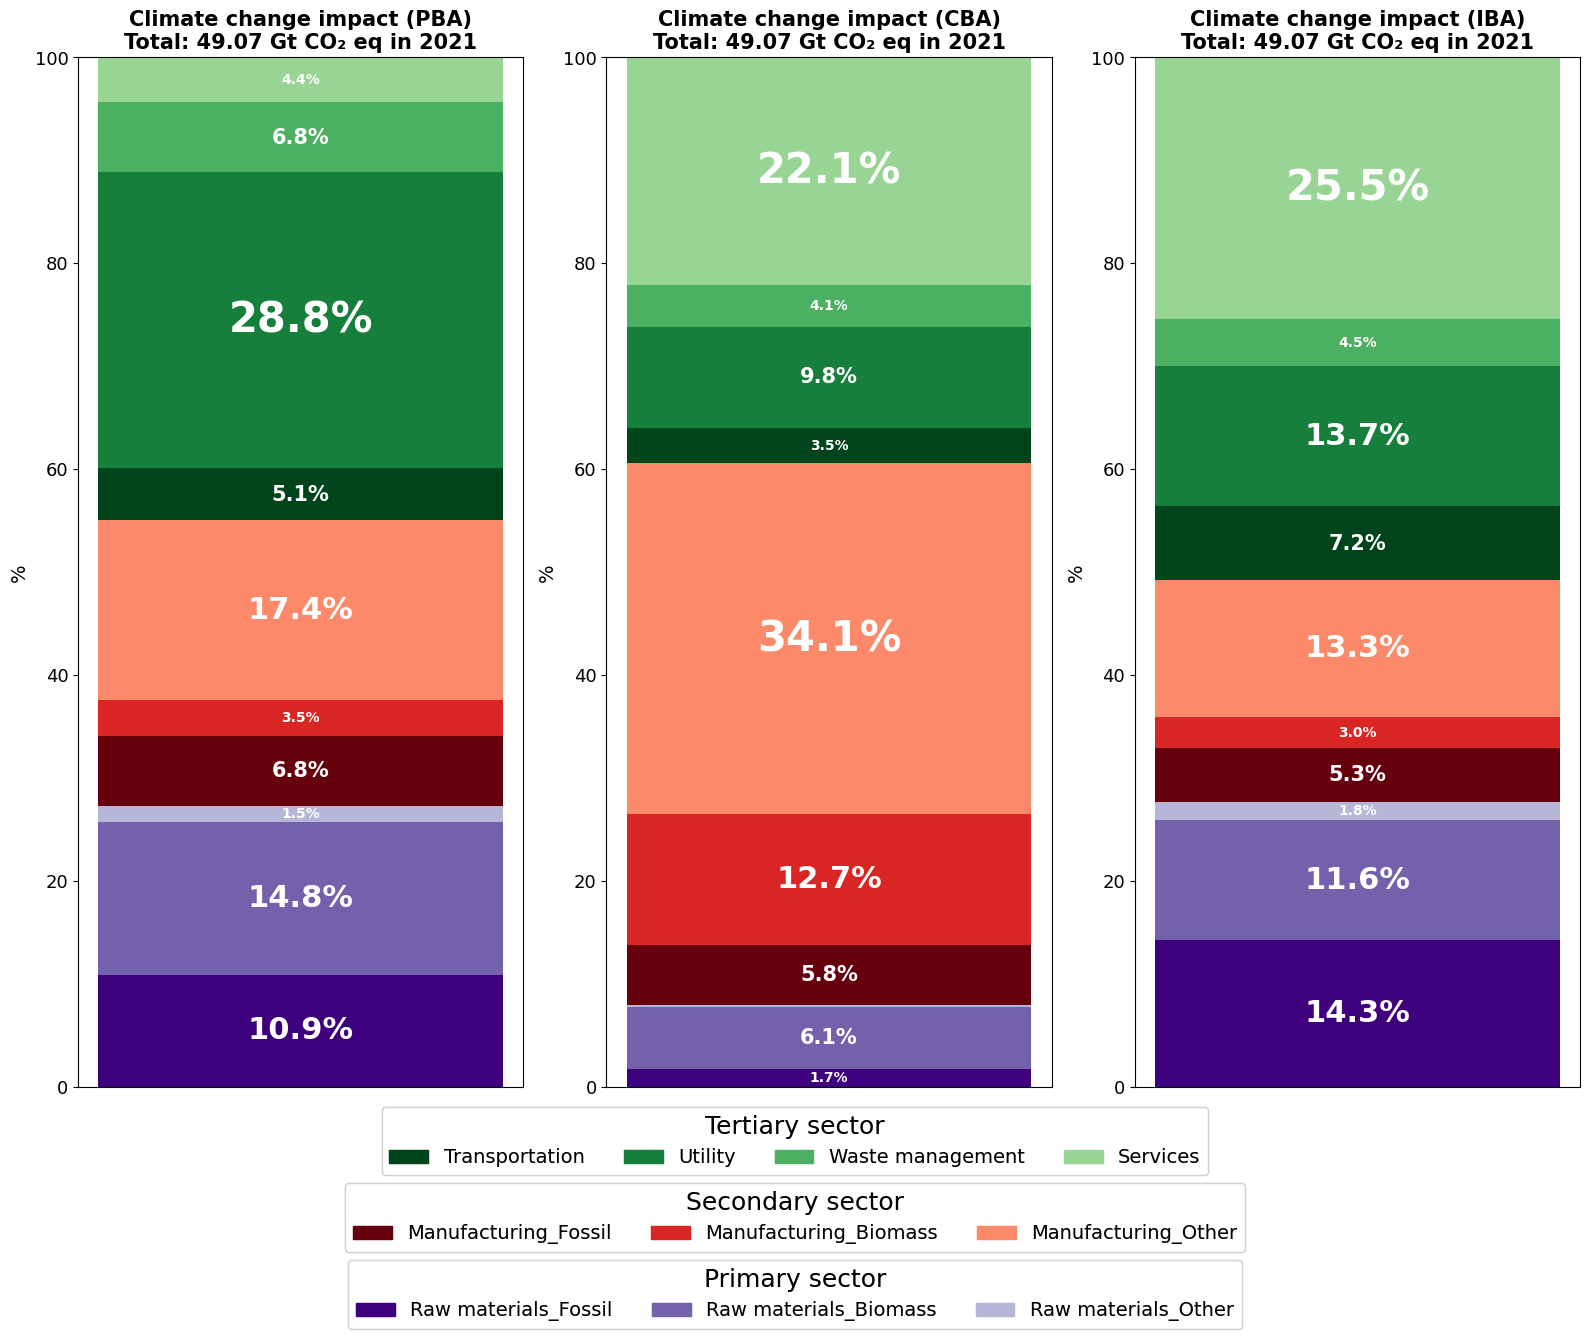

In [ ]:
# Stackbar GHG emissions (fig 3)

# Regrouper les impacts (I_direct, I_amont, I_aval) par secteur agrégé
I_direct_by_sector = AI_2021['PBA'].groupby(level=3).sum() / 1e12
I_amont_by_sector = AI_2021['CBA'].groupby(level=3).sum() / 1e12
I_aval_by_sector = AI_2021['IBA'].groupby(level=3).sum() / 1e12

# Créer les données pour stackbar
data_stackbar = pd.DataFrame({
    'PBA': I_direct_by_sector,
    'CBA': I_amont_by_sector,
    'IBA': I_aval_by_sector
})

# Ordre de référence unique des secteurs
sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

# Regrouper les secteurs en 3 familles
primary_sectors = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other']
secondary_sectors = ['Manufacturing_Fossil',
                        'Manufacturing_Biomass',
                        'Manufacturing_Other']
tertiary_sectors = ['Transportation',
                'Utility',
                'Waste management',
                'Services']

# Dégradés de couleurs par famille (plus contrastés)
def gradient_colors(cmap_name, n, vmin=1, vmax=0.4):
    if n == 0:
        return []
    if n == 1:
        return [plt.cm.get_cmap(cmap_name)(0.8)]
    vals = np.linspace(vmin, vmax, n)
    return [plt.cm.get_cmap(cmap_name)(w) for w in vals]

sector_colors = {}
for s, c in zip(primary_sectors, gradient_colors('Purples', len(primary_sectors))):
    sector_colors[s] = c
for s, c in zip(secondary_sectors, gradient_colors('Reds', len(secondary_sectors))):
    sector_colors[s] = c
for s, c in zip(tertiary_sectors, gradient_colors('Greens', len(tertiary_sectors))):
    sector_colors[s] = c

# Créer 3 barplots empilés (1 par accounting approach)
fig, axes = plt.subplots(1, 3, figsize=(16, 14))

acc_approach = ['PBA', 'CBA', 'IBA']
data_fig3 = pd.DataFrame(np.zeros((len(sector_order), len(acc_approach))), index=sector_order, columns=acc_approach)

for idx, acc_appr in enumerate(acc_approach):
    ax = axes[idx]
    # Ordre fixe identique pour les 3 accounting approaches
    data_acc = data_stackbar[acc_appr].reindex(sector_order)
    total_acc = data_acc.sum()
    data_acc_pct = (data_acc / total_acc * 100) if total_acc != 0 else data_acc * 0

    data_fig3.iloc[:, idx] = data_acc_pct
    
    # Ajouter les segments empilés avec la couleur fixe pour chaque secteur
    bottom = 0
    for sector, value_pct in data_acc_pct.items():
        ax.bar(0, value_pct, bottom=bottom, width=0.5, label=sector, color=sector_colors[sector])
        # Ajouter le label de la valeur
        if value_pct > 1:
            if value_pct > 20:
                ft = 30
            elif value_pct > 10:
                ft = 22
            elif value_pct > 5:
                ft = 15
            else:
                ft = 10
            ax.text(0, bottom + value_pct/2, f'{value_pct:.1f}%', ha='center', va='center', fontsize=ft, fontweight='bold', color='white')
        bottom += value_pct
    
    ax.set_title(f'Climate change impact ({acc_appr})\nTotal: {total_acc:.2f} Gt CO₂ eq in 2021', fontsize=15, fontweight='bold')
    ax.set_ylabel('%', fontsize=14)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    #ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=13)

# 3 sous-légendes distinctes

handles_tertiary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in tertiary_sectors]
leg3 = fig.legend(handles_tertiary, tertiary_sectors, loc='lower center',
                  ncol=min(4, len(tertiary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.15), frameon=True,
                  title='Tertiary sector', title_fontsize=18)
fig.add_artist(leg3)

handles_secondary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in secondary_sectors]
leg2 = fig.legend(handles_secondary, secondary_sectors, loc='lower center',
                  ncol=min(4, len(secondary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.095), frameon=True,
                  title='Secondary sector', title_fontsize=18)
fig.add_artist(leg2)

handles_primary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in primary_sectors]
leg1 = fig.legend(handles_primary, primary_sectors, loc='lower center',
                  ncol=min(4, len(primary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.04), frameon=True,
                  title='Primary sector', title_fontsize=18)
fig.add_artist(leg1)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
plt.savefig("fig 3.png", dpi=600)
plt.show()

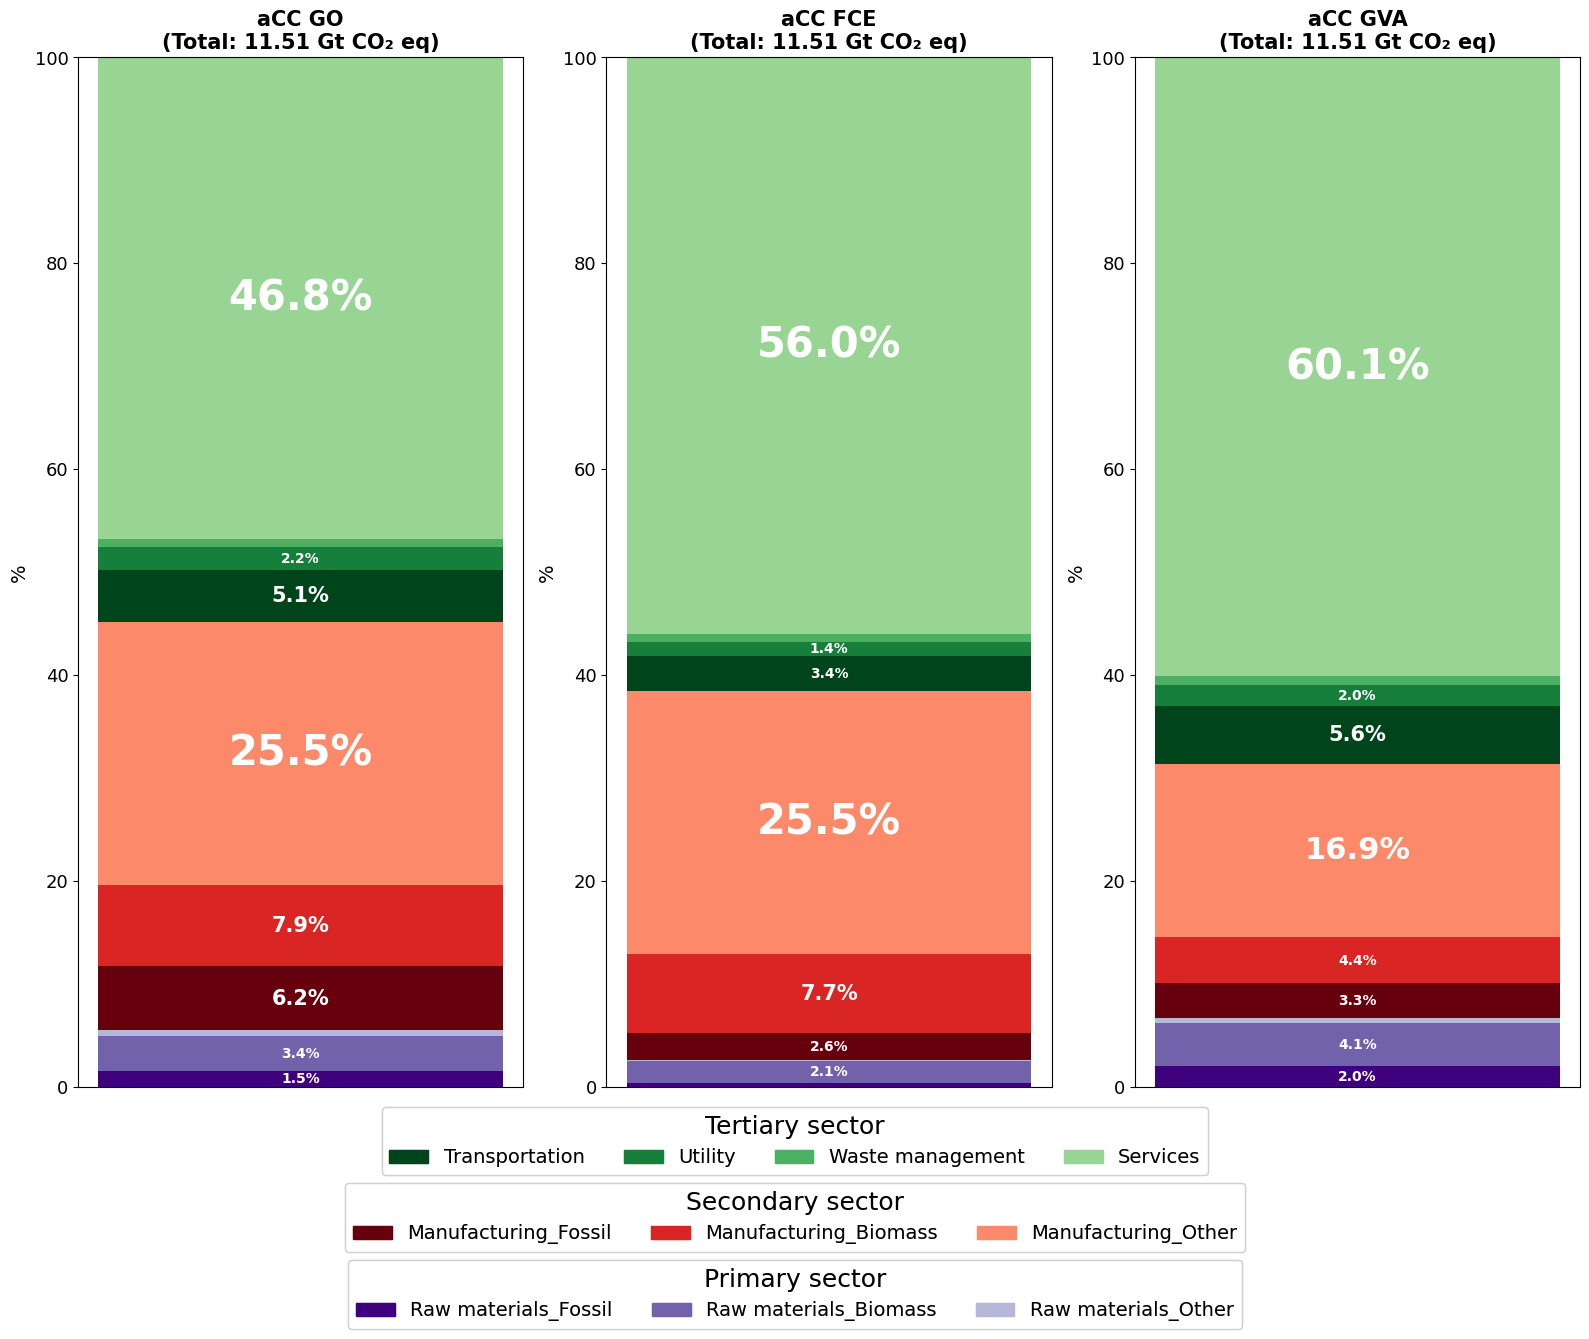

In [ ]:
# Stackbar aCC economic contribution (fig 4a)

columns = ['aCC GO', 'aCC FCE', 'aCC GVA']

# Créer les données pour stackbar
data_stackbar = aCC_util.groupby(level=3).sum() / 1e12
data_stackbar.columns = columns


# Ordre de référence unique des secteurs
sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

# Regrouper les secteurs en 3 familles
primary_sectors = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other']
secondary_sectors = ['Manufacturing_Fossil',
                        'Manufacturing_Biomass',
                        'Manufacturing_Other']
tertiary_sectors = ['Transportation',
                'Utility',
                'Waste management',
                'Services']

# Dégradés de couleurs par famille
def gradient_colors(cmap_name, n, vmin=1, vmax=0.4):
    if n == 0:
        return []
    if n == 1:
        return [plt.cm.get_cmap(cmap_name)(0.8)]
    vals = np.linspace(vmin, vmax, n)
    return [plt.cm.get_cmap(cmap_name)(w) for w in vals]

sector_colors = {}
for s, c in zip(primary_sectors, gradient_colors('Purples', len(primary_sectors))):
    sector_colors[s] = c
for s, c in zip(secondary_sectors, gradient_colors('Reds', len(secondary_sectors))):
    sector_colors[s] = c
for s, c in zip(tertiary_sectors, gradient_colors('Greens', len(tertiary_sectors))):
    sector_colors[s] = c

# Créer 3 barplots empilés (1 par accounting approach)
fig, axes = plt.subplots(1, 3, figsize=(16, 14))

data_fig4a = pd.DataFrame(np.zeros((len(sector_order), len(columns))), index=sector_order, columns=columns)

for idx, acc_appr in enumerate(columns):
    ax = axes[idx]
    # Ordre fixe identique pour les 3 accounting approaches
    data_acc = data_stackbar[acc_appr].reindex(sector_order)
    total_acc = data_acc.sum()
    data_acc_pct = (data_acc / total_acc * 100) if total_acc != 0 else data_acc * 0

    data_fig4a.iloc[:, idx] = data_acc_pct
    
    # Ajouter les segments empilés avec la couleur fixe pour chaque secteur
    bottom = 0
    for sector, value_pct in data_acc_pct.items():
        ax.bar(0, value_pct, bottom=bottom, width=0.5, label=sector, color=sector_colors[sector])
        # Ajouter le label de la valeur
        if value_pct > 1:
            if value_pct > 20:
                ft = 30
            elif value_pct > 10:
                ft = 22
            elif value_pct > 5:
                ft = 15
            else:
                ft = 10
            ax.text(0, bottom + value_pct/2, f'{value_pct:.1f}%', ha='center', va='center', fontsize=ft, fontweight='bold', color='white')
        bottom += value_pct
    
    ax.set_title(f'{acc_appr}\n(Total: {total_acc:.2f} Gt CO₂ eq)', fontsize=15, fontweight='bold')
    ax.set_ylabel('%', fontsize=14)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    #ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=13)

# 3 sous-légendes distinctes

handles_tertiary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in tertiary_sectors]
leg3 = fig.legend(handles_tertiary, tertiary_sectors, loc='lower center',
                  ncol=min(4, len(tertiary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.15), frameon=True,
                  title='Tertiary sector', title_fontsize=18)
fig.add_artist(leg3)

handles_secondary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in secondary_sectors]
leg2 = fig.legend(handles_secondary, secondary_sectors, loc='lower center',
                  ncol=min(4, len(secondary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.095), frameon=True,
                  title='Secondary sector', title_fontsize=18)
fig.add_artist(leg2)

handles_primary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in primary_sectors]
leg1 = fig.legend(handles_primary, primary_sectors, loc='lower center',
                  ncol=min(4, len(primary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.04), frameon=True,
                  title='Primary sector', title_fontsize=18)
fig.add_artist(leg1)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
plt.savefig("fig 4a.png", dpi=600)
plt.show()

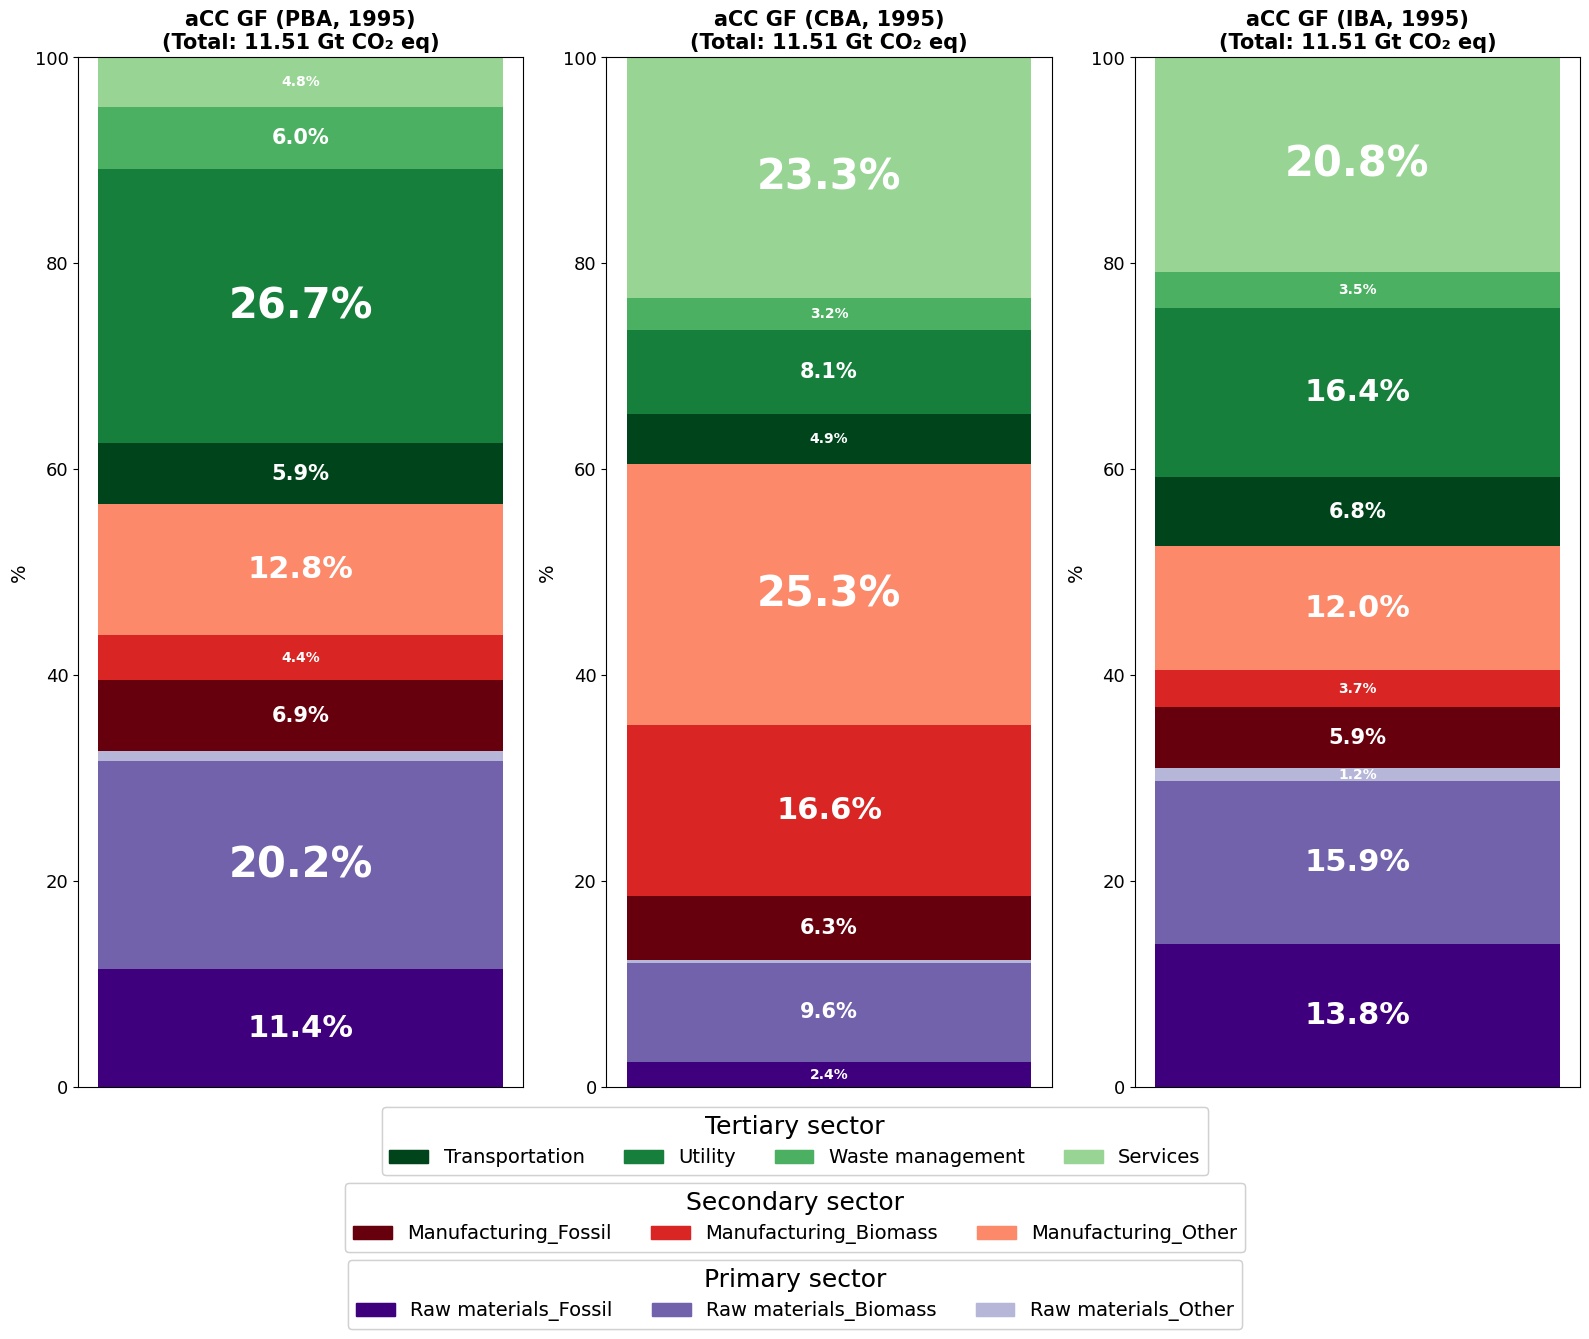

In [ ]:
# Stackbar aCC grandfathering (fig 4b)

columns = ['aCC GF (PBA, 1995)', 'aCC GF (CBA, 1995)', 'aCC GF (IBA, 1995)']

# Créer les données pour stackbar
data_stackbar = aCC_GF.groupby(level=[3]).sum() / 1e12
data_stackbar.columns = columns


# Ordre de référence unique des secteurs
sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

# Regrouper les secteurs en 3 familles
primary_sectors = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other']
secondary_sectors = ['Manufacturing_Fossil',
                        'Manufacturing_Biomass',
                        'Manufacturing_Other']
tertiary_sectors = ['Transportation',
                'Utility',
                'Waste management',
                'Services']

# Dégradés de couleurs par famille
def gradient_colors(cmap_name, n, vmin=1, vmax=0.4):
    if n == 0:
        return []
    if n == 1:
        return [plt.cm.get_cmap(cmap_name)(0.8)]
    vals = np.linspace(vmin, vmax, n)
    return [plt.cm.get_cmap(cmap_name)(w) for w in vals]

sector_colors = {}
for s, c in zip(primary_sectors, gradient_colors('Purples', len(primary_sectors))):
    sector_colors[s] = c
for s, c in zip(secondary_sectors, gradient_colors('Reds', len(secondary_sectors))):
    sector_colors[s] = c
for s, c in zip(tertiary_sectors, gradient_colors('Greens', len(tertiary_sectors))):
    sector_colors[s] = c

# Créer 3 barplots empilés (1 par accounting approach)
fig, axes = plt.subplots(1, 3, figsize=(16, 14))

data_fig4b = pd.DataFrame(np.zeros((len(sector_order), len(columns))), index=sector_order, columns=columns)

for idx, acc_appr in enumerate(columns):
    ax = axes[idx]
    # Ordre fixe identique pour les 3 accounting approaches
    data_acc = data_stackbar[acc_appr].reindex(sector_order)
    total_acc = data_acc.sum()
    data_acc_pct = (data_acc / total_acc * 100) if total_acc != 0 else data_acc * 0

    data_fig4b.iloc[:, idx] = data_acc_pct
    
    # Ajouter les segments empilés avec la couleur fixe pour chaque secteur
    bottom = 0
    for sector, value_pct in data_acc_pct.items():
        ax.bar(0, value_pct, bottom=bottom, width=0.5, label=sector, color=sector_colors[sector])
        # Ajouter le label de la valeur
        if value_pct > 1:
            if value_pct > 20:
                ft = 30
            elif value_pct > 10:
                ft = 22
            elif value_pct > 5:
                ft = 15
            else:
                ft = 10
            ax.text(0, bottom + value_pct/2, f'{value_pct:.1f}%', ha='center', va='center', fontsize=ft, fontweight='bold', color='white')
        bottom += value_pct
    
    ax.set_title(f'{acc_appr}\n(Total: {total_acc:.2f} Gt CO₂ eq)', fontsize=15, fontweight='bold')
    ax.set_ylabel('%', fontsize=14)
    ax.set_ylim(0, 100)
    ax.set_xticks([])
    #ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='y', labelsize=13)

# 3 sous-légendes distinctes

handles_tertiary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in tertiary_sectors]
leg3 = fig.legend(handles_tertiary, tertiary_sectors, loc='lower center',
                  ncol=min(4, len(tertiary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.15), frameon=True,
                  title='Tertiary sector', title_fontsize=18)
fig.add_artist(leg3)

handles_secondary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in secondary_sectors]
leg2 = fig.legend(handles_secondary, secondary_sectors, loc='lower center',
                  ncol=min(4, len(secondary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.095), frameon=True,
                  title='Secondary sector', title_fontsize=18)
fig.add_artist(leg2)

handles_primary = [plt.Rectangle((0, 0), 1, 1, color=sector_colors[s]) for s in primary_sectors]
leg1 = fig.legend(handles_primary, primary_sectors, loc='lower center',
                  ncol=min(4, len(primary_sectors)), fontsize=14,
                  bbox_to_anchor=(0.5, 0.04), frameon=True,
                  title='Primary sector', title_fontsize=18)
fig.add_artist(leg1)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
plt.savefig("fig 4b.png", dpi=600)
plt.show()

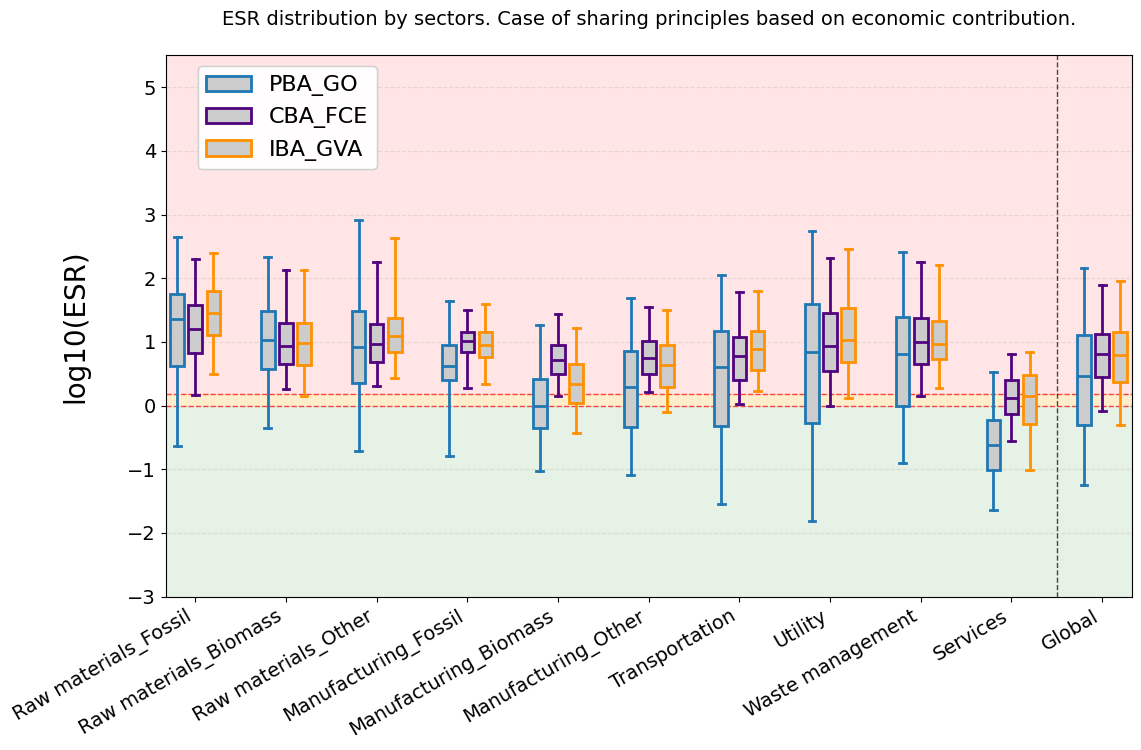

In [ ]:
# boxplot log. Economic contribution (fig 5a)

df_plot = np.log10(ESR_util.copy())

df_plot = df_plot.reset_index()

data_fig5a = df_plot.copy()
data_fig5a[["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]] = data_fig5a[["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]].replace([np.inf, -np.inf], np.nan)
#data_fig5a.to_excel("data_fig5a.xlsx", index=False)

# Colonnes
sector_col = "aggregated_sectors"
region_col = "aggregated_regions"
value_vars = ["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]

sector_order = ['Raw materials_Fossil',
                'Raw materials_Biomass',
                'Raw materials_Other',
                'Manufacturing_Fossil',
                'Manufacturing_Biomass',
                'Manufacturing_Other',
                'Transportation',
                'Utility',
                'Waste management',
                'Services'
                ]

sector_order_global = sector_order + ['Global']

indicator_labels = ["PBA_GO", "CBA_FCE", "IBA_GVA"]
indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]

# construire data_by_indicator en incluant 'global' (tous les secteurs réunis)
data_by_indicator = pd.DataFrame(
    {
        var: [
            (
                (s := df_plot.loc[df_plot[sector_col] == sec, var])[np.isfinite(s)] if sec != 'Global'
                else (s := df_plot[var])[np.isfinite(s)]
            )
            for sec in sector_order_global
        ]
        for var in value_vars
    },
    index=sector_order_global
)

# Positions des boxplots (3 par secteur)
base = np.arange(len(sector_order_global)) * 4
offsets = [-0.8, 0.0, 0.8]

boxplot_stats_util = {}
threshold_1 = 0
threshold_2 = np.log10(CC_GES_Doka_up / CC_GES_Doka_low)


fig, ax = plt.subplots(figsize=(14, 8))

ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)

# Fenêtre de visualisation
borne_inf = -3
borne_sup = 5.5
ax.set_ylim(borne_inf, borne_sup)

if CC_GES == CC_GES_Doka_low:
    ax.axhline(y=np.log10(CC_GES_Doka_up / CC_GES_Doka_low), color='red', linestyle='--', linewidth=1, alpha=0.7)
    rect1 = Rectangle((-1.3, 0), 42.6, np.log10(CC_GES_Doka_up / CC_GES_Doka_low), linewidth=0, edgecolor='orange', facecolor='orange', alpha=0.2)
    ax.add_patch(rect1)
    rect2 = Rectangle((-1.3, 0), 42.6, borne_inf, linewidth=0, edgecolor='green', facecolor='green', alpha=0.1)
    ax.add_patch(rect2)
    rect3 = Rectangle((-1.3, 0.17), 42.6, borne_sup, linewidth=0, edgecolor='red', facecolor='red', alpha=0.1)
    ax.add_patch(rect3)


c = 0
y_pos = [0,0.14,0.28] * 12
for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
    positions = base + offsets[i]
    ax.boxplot(
        data_by_indicator[var],
        positions=positions,
        widths=0.6,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
        medianprops=dict(color=color, linewidth=2),
        whiskerprops=dict(color=color, linewidth=2),
        capprops=dict(color=color, linewidth=2),
        whis=(5, 95)
    )



    # Calcul des statistiques (écart-type, écart interquartile) pour chaque boxplot
    for sector, pos, vals in zip(sector_order_global, positions, data_by_indicator[var]):
        if len(vals) == 0:
            continue
        std_val = np.std(vals, ddof=1)
        mean_val = np.mean(vals)
        cv_val = std_val / np.abs(mean_val) if mean_val != 0 else 0.0
        q1 = np.percentile(vals, 25)
        q3 = np.percentile(vals, 75)
        iqr = q3 - q1

        # Comptage selon les trois intervalles
        n_below_aCC = np.sum(vals < threshold_1)
        n_zone_incr_risk = np.sum((vals >= threshold_1) & (vals <= threshold_2))
        n_above_high_aCC = np.sum(vals > threshold_2)
        
        # Stocker les statistiques
        boxplot_stats_util[(sector, label)] = {
            'mean': mean_val,
            'std': std_val,
            'cv': cv_val,
            'q1': q1,
            'q3': q3,
            'iqr': iqr,
            'median': np.median(vals),
            'count': len(vals),
            'shapiro_p': stats.shapiro(vals)[1],
            'skewness': stats.skew(vals),

            'n_below_aCC': n_below_aCC,
            'n_zone_incr_risk': n_zone_incr_risk,
            'n_above_high_aCC': n_above_high_aCC,
            '%_below_aCC': (n_below_aCC / len(vals)) * 100,
            '%_zone_incr_risk': (n_zone_incr_risk / len(vals)) * 100,
            '%_above_high_aCC': (n_above_high_aCC / len(vals)) * 100
        }
    c += 1

boxplot_stats_df_util = pd.DataFrame(boxplot_stats_util).T
boxplot_stats_df_util.to_excel("Stats_Figure_5a.xlsx")

# Axes
ax.set_xticks(base)
ax.set_xticklabels(sector_order_global, fontsize=14, rotation=30, ha="right")
ax.set_xlabel("")
ax.set_yscale("linear")
ax.set_ylabel("log10(ESR)\n", fontsize=20)
ax.set_title("ESR distribution by sectors. Case of sharing principles based on economic contribution.\n", fontsize=14)
plt.tick_params(axis='y', labelsize=14)
ax.grid(axis="y", alpha=0.3, linestyle="--")

ax.axvline(x=38, color='black', linestyle='--', linewidth=1, alpha=0.7)

# Nombre de points affichés dans la fenêtre de visualisation
window_min, window_max = borne_inf, borne_sup
points_in_window = 0
total_points = 0
for var in value_vars:
    for vals in data_by_indicator[var]:
        total_points += len(vals)
        if len(vals) > 0:
            points_in_window += np.count_nonzero((vals >= window_min) & (vals <= window_max))

# Légende indicateurs (couleur des boxplots)
legend_handles = [Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl) for c, lbl in zip(indicator_colors, indicator_labels)]
leg_box = ax.legend(handles=legend_handles, title="", bbox_to_anchor=(0.23, 1), loc="upper right", fontsize=16, title_fontsize=15)
ax.add_artist(leg_box)

plt.tight_layout(rect=[0, 0, 0.82, 0.95])
plt.savefig("fig 5a.png", dpi=600)
plt.show()

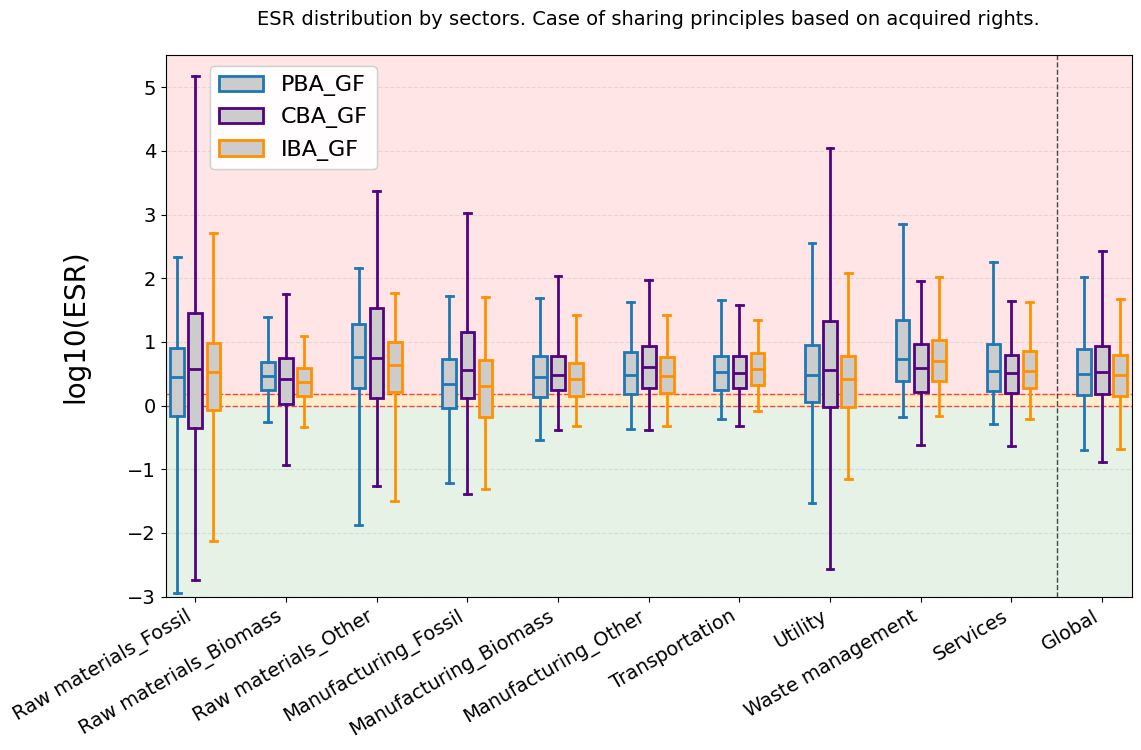

In [ ]:
# boxplot log. Grandfathering (fig 5b)

df_plot = np.log10(ESR_GF.copy())
df_plot = df_plot.reset_index()

data_fig5b = df_plot.copy()
data_fig5b[["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]] = data_fig5b[["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]].replace([np.inf, -np.inf], np.nan)
# data_fig5b.to_excel("data_fig5b.xlsx", index=False)

# Colonnes
sector_col = "aggregated_sectors"
region_col = "aggregated_regions"
value_vars = ["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]

sector_order_global = sector_order + ['Global']

indicator_labels = ["PBA_GF", "CBA_GF", "IBA_GF"]
indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]

data_by_indicator = pd.DataFrame(
    {
        var: [
            (
                (s := df_plot.loc[df_plot[sector_col] == sec, var])[np.isfinite(s)] if sec != 'Global'
                else (s := df_plot[var])[np.isfinite(s)]
            )
            for sec in sector_order_global
        ]
        for var in value_vars
    },
    index=sector_order_global
)

# Positions des boxplots (3 par secteur)
base = np.arange(len(sector_order_global)) * 4
offsets = [-0.8, 0.0, 0.8]

boxplot_stats_GF = {}
threshold_1 = 0
threshold_2 = np.log10(CC_GES_Doka_up / CC_GES_Doka_low)

fig, ax = plt.subplots(figsize=(14, 8))

ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)

# Fenêtre de visualisation
borne_inf = -3
borne_sup = 5.5
ax.set_ylim(borne_inf, borne_sup)

if CC_GES == CC_GES_Doka_low:
    ax.axhline(y=np.log10(CC_GES_Doka_up / CC_GES_Doka_low), color='red', linestyle='--', linewidth=1, alpha=0.7)
    rect1 = Rectangle((-1.3, 0), 42.6, np.log10(CC_GES_Doka_up / CC_GES_Doka_low), linewidth=0, edgecolor='orange', facecolor='orange', alpha=0.2)
    ax.add_patch(rect1)
    rect2 = Rectangle((-1.3, 0), 42.6, borne_inf, linewidth=0, edgecolor='green', facecolor='green', alpha=0.1)
    ax.add_patch(rect2)
    rect3 = Rectangle((-1.3, 0.17), 42.6, borne_sup, linewidth=0, edgecolor='red', facecolor='red', alpha=0.1)
    ax.add_patch(rect3)

c = 0
y_pos = [0,0.14,0.28] * 10
for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
    positions = base + offsets[i]
    ax.boxplot(
        data_by_indicator[var],
        positions=positions,
        widths=0.6,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
        medianprops=dict(color=color, linewidth=2),
        whiskerprops=dict(color=color, linewidth=2),
        capprops=dict(color=color, linewidth=2),
        whis=(5, 95)
    )

    # Calcul des statistiques (écart-type, écart interquartile) pour chaque boxplot
    for sector, pos, vals in zip(sector_order_global, positions, data_by_indicator[var]):
        if len(vals) == 0:
            continue
        std_val = np.std(vals, ddof=1)
        mean_val = np.mean(vals)
        cv_val = std_val / np.abs(mean_val) if mean_val != 0 else 0.0
        q1 = np.percentile(vals, 25)
        q3 = np.percentile(vals, 75)
        iqr = q3 - q1

        # Comptage selon les trois intervalles
        n_below_aCC = np.sum(vals < threshold_1)
        n_zone_incr_risk = np.sum((vals >= threshold_1) & (vals <= threshold_2))
        n_above_high_aCC = np.sum(vals > threshold_2)
        
        # Stocker les statistiques
        boxplot_stats_GF[(sector, label)] = {
            'mean': mean_val,
            'std': std_val,
            'cv': cv_val,
            'q1': q1,
            'q3': q3,
            'iqr': iqr,
            'median': np.median(vals),
            'count': len(vals),
            'shapiro_p': stats.shapiro(vals)[1],
            'skewness': stats.skew(vals),

            'n_below_aCC': n_below_aCC,
            'n_zone_incr_risk': n_zone_incr_risk,
            'n_above_high_aCC': n_above_high_aCC,
            '%_below_aCC': (n_below_aCC / len(vals)) * 100,
            '%_zone_incr_risk': (n_zone_incr_risk / len(vals)) * 100,
            '%_above_high_aCC': (n_above_high_aCC / len(vals)) * 100
        }
    c += 1

boxplot_stats_df_GF = pd.DataFrame(boxplot_stats_GF).T
boxplot_stats_df_GF.to_excel("Stats_Figure_5b.xlsx")

# Axes
ax.set_xticks(base)
ax.set_xticklabels(sector_order_global, fontsize=14, rotation=30, ha="right")
ax.set_xlabel("")
ax.set_yscale("linear")
ax.set_ylabel("log10(ESR)\n", fontsize=20)
ax.set_title("ESR distribution by sectors. Case of sharing principles based on acquired rights.\n", fontsize=14)
plt.tick_params(axis='y', labelsize=14)
ax.grid(axis="y", alpha=0.3, linestyle="--")

ax.axvline(x=38, color='black', linestyle='--', linewidth=1, alpha=0.7)

# Nombre de points affichés dans la fenêtre de visualisation
window_min, window_max = borne_inf, borne_sup
points_in_window = 0
total_points = 0
for var in value_vars:
    for vals in data_by_indicator[var]:
        total_points += len(vals)
        if len(vals) > 0:
            points_in_window += np.count_nonzero((vals >= window_min) & (vals <= window_max))

# Légende indicateurs (couleur des boxplots)
legend_handles = [Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl) for c, lbl in zip(indicator_colors, indicator_labels)]
leg_box = ax.legend(handles=legend_handles, title="", bbox_to_anchor=(0.23, 1), loc="upper right", fontsize=16, title_fontsize=15)
ax.add_artist(leg_box)

plt.tight_layout(rect=[0, 0, 0.82, 0.95])
plt.savefig("fig 5b.png", dpi=600)
plt.show()

=== Diagnostic : perte d'échantillon due à l'harmonisation par colonne ===
               sector                 comparison  n_before (pairwise)  n_after (harmonized)  n_lost
 Raw materials_Fossil  ESR_PBA_GO vs ESR_CBA_FCE                  332                   249      83
 Raw materials_Fossil  ESR_PBA_GO vs ESR_IBA_GVA                  374                   249     125
 Raw materials_Fossil ESR_CBA_FCE vs ESR_IBA_GVA                  332                   249      83
 Raw materials_Fossil   ESR_PBA_GF vs ESR_CBA_GF                  324                   249      75
 Raw materials_Fossil   ESR_PBA_GF vs ESR_IBA_GF                  416                   249     167
 Raw materials_Fossil   ESR_CBA_GF vs ESR_IBA_GF                  323                   249      74
Raw materials_Biomass  ESR_PBA_GO vs ESR_CBA_FCE                  791                   759      32
Raw materials_Biomass  ESR_PBA_GO vs ESR_IBA_GVA                  806                   759      47
Raw materials_Biomass ESR

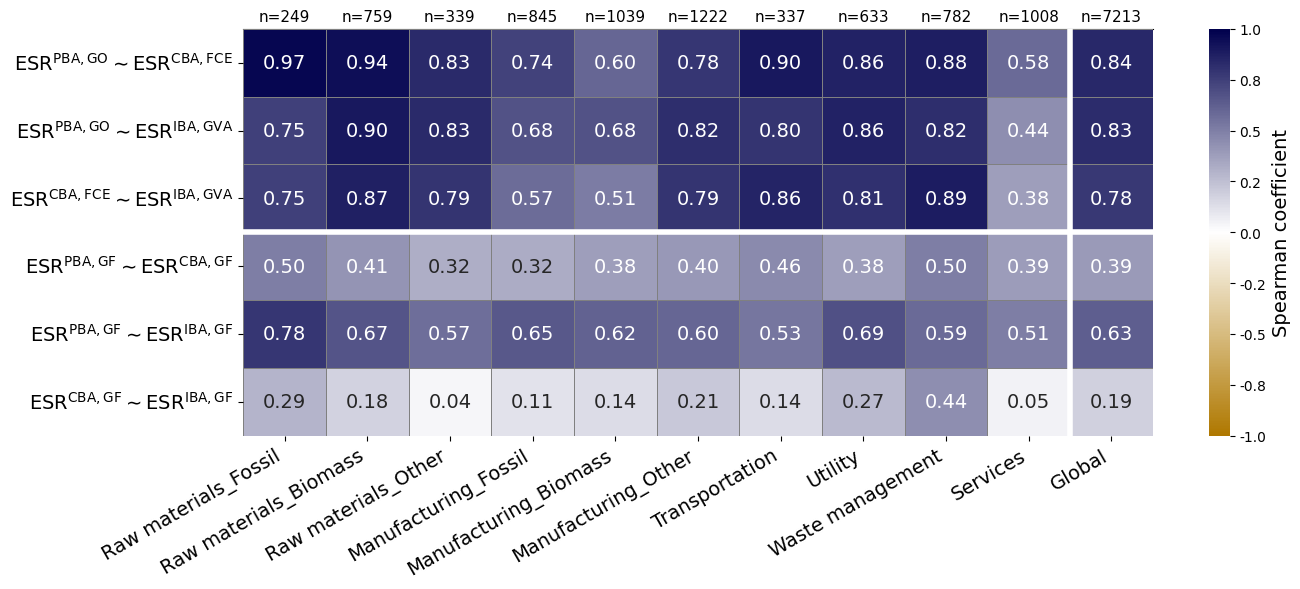

In [ ]:
# Heatmap Spearman coefficient (fig 6a)

esr_df = ESR_util.copy().assign(
    ESR_PBA_GF=ESR_GF['ESR_PBA_GF'],
    ESR_CBA_GF=ESR_GF['ESR_CBA_GF'],
    ESR_IBA_GF=ESR_GF['ESR_IBA_GF'],
)

esr_df['aggregated_sectors'] = esr_df.index.get_level_values(3)

sector_order = [
    'Raw materials_Fossil',
    'Raw materials_Biomass',
    'Raw materials_Other',
    'Manufacturing_Fossil',
    'Manufacturing_Biomass',
    'Manufacturing_Other',
    'Transportation',
    'Utility',
    'Waste management',
    'Services',
]
sector_order_global = sector_order + ['Global']

comparison = [("ESR_PBA_GO", "ESR_CBA_FCE"), ("ESR_PBA_GO", "ESR_IBA_GVA"), ("ESR_CBA_FCE", "ESR_IBA_GVA"), ("ESR_PBA_GF", "ESR_CBA_GF"), ("ESR_PBA_GF", "ESR_IBA_GF"), ("ESR_CBA_GF", "ESR_IBA_GF")]
comparison_labels = [
    r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{CBA,FCE}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    r'$\mathrm{ESR}^{\mathrm{CBA,FCE}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{CBA,GF}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
    r'$\mathrm{ESR}^{\mathrm{CBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
]

# Ensemble des variables impliquées dans au moins une comparaison
all_vars = sorted(set(v for pair in comparison for v in pair))

index = pd.MultiIndex.from_product([comparison, sector_order_global], names=['comparison', 'sector'])

Regr_results = pd.DataFrame(
    {
        'count': 0,
        'spearman': np.nan,
        'p-value': np.nan
    },
    index=index
)

# --- Étape 1 : masque commun par colonne (secteur), basé sur TOUTES les variables des comparaisons ---
common_mask_by_sector = {}
diagnostic_rows = []

for sector in sector_order_global:
    if sector == 'Global':
        subset_data = esr_df
    else:
        subset_data = esr_df[esr_df['aggregated_sectors'] == sector]

    mask_common = np.ones(len(subset_data), dtype=bool)
    for var in all_vars:
        mask_common &= np.isfinite(subset_data[var]) & (subset_data[var] >= 0)

    common_mask_by_sector[sector] = subset_data[mask_common]
    n_harmonized = mask_common.sum()

    # --- Diagnostic : n avant harmonisation, par comparaison, pour ce secteur ---
    for line in comparison:
        mask_pairwise = np.isfinite(subset_data[line[0]]) & np.isfinite(subset_data[line[1]])
        n_pairwise = mask_pairwise.sum()
        diagnostic_rows.append({
            'sector': sector,
            'comparison': f"{line[0]} vs {line[1]}",
            'n_before (pairwise)': n_pairwise,
            'n_after (harmonized)': n_harmonized,
            'n_lost': n_pairwise - n_harmonized,
        })

diagnostic_df = pd.DataFrame(diagnostic_rows)

print("=== Diagnostic : perte d'échantillon due à l'harmonisation par colonne ===")
print(diagnostic_df.to_string(index=False))

# Résumé par secteur (n_lost max sur les 6 comparaisons = perte la plus sévère visible dans la heatmap d'origine)
summary_by_sector = diagnostic_df.groupby('sector').agg(
    n_after_harmonized=('n_after (harmonized)', 'first'),
    n_before_max=('n_before (pairwise)', 'max'),
    n_before_min=('n_before (pairwise)', 'min'),
).assign(max_loss=lambda d: d['n_before_max'] - d['n_after_harmonized'])
summary_by_sector = summary_by_sector.reindex(sector_order_global)

print("\n=== Résumé par secteur ===")
print(summary_by_sector.to_string())

# --- Étape 2 : calcul du Spearman sur ce même sous-échantillon pour chaque ligne ---
for (line, sector) in index:
    subset_data = common_mask_by_sector[sector]
    n_count = len(subset_data)
    Regr_results.loc[(line, sector), 'count'] = n_count

    if n_count > 1:
        x_1 = subset_data[line[0]].values
        y_2 = subset_data[line[1]].values
        rho, p_value = stats.spearmanr(x_1, y_2, nan_policy='omit')
        Regr_results.loc[(line, sector), 'spearman'] = rho
        Regr_results.loc[(line, sector), 'p-value'] = p_value
    else:
        Regr_results.loc[(line, sector), 'spearman'] = np.nan
        Regr_results.loc[(line, sector), 'p-value'] = np.nan

data_fig6a = Regr_results.copy().reset_index()
# data_fig6a.to_excel("data_fig6a.xlsx")

spearman_pivot = Regr_results['spearman'].unstack(fill_value=np.nan)
count_pivot = Regr_results['count'].unstack(fill_value=0).astype(int)

spearman_pivot = spearman_pivot.reindex(index=comparison, columns=sector_order_global)
count_pivot = count_pivot.reindex(index=comparison, columns=sector_order_global)

annotations = np.empty_like(spearman_pivot, dtype=object)
for i in range(spearman_pivot.shape[0]):
    for j in range(spearman_pivot.shape[1]):
        rho_val = spearman_pivot.iloc[i, j]
        count_val = count_pivot.iloc[i, j]
        if np.isnan(rho_val):
            annotations[i, j] = ''
        else:
            annotations[i, j] = f"{rho_val:.2f}"

cmap_focus = mcolors.LinearSegmentedColormap.from_list(
    "dark_red_white_blue",
    [(0.0, "#af7800"), (0.5, "#ffffff"), (1.0, "#00004d")],
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    spearman_pivot,
    annot=annotations,
    annot_kws={'fontsize': 14},
    fmt='',
    cmap=cmap_focus,
    ax=ax,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='gray'
)

cbar = ax.collections[0].colorbar
cbar.set_label('Spearman coefficient', fontsize=14)
cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

ax.set_xticklabels(sector_order_global, fontsize=14, rotation=30, ha="right")
ax.set_yticklabels(comparison_labels, fontsize=14, rotation=0)
ax.set_xlabel('', fontsize=11, fontweight='bold')
ax.set_ylabel('', fontsize=11, fontweight='bold')

ax.axhline(y=3, color='white', linewidth=4)
ax.axvline(x=spearman_pivot.shape[1] - 1, color='white', linewidth=4)

# for spine in ax.spines.values():
#     spine.set_visible(True)
#     spine.set_linewidth(1)

# --- n= au-dessus de chaque colonne (identique sur toutes les lignes, donc on prend la 1ère) ---
ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels(
    [f"n={count_pivot[sector].iloc[0]}" for sector in sector_order_global],
    fontsize=11,
    rotation=0
)
ax_top.tick_params(length=0)  # pas de petits traits, juste le texte

plt.tight_layout()
plt.savefig("fig 6a.png", dpi=600)
plt.show()

=== Diagnostic : perte d'échantillon due à l'harmonisation par colonne ===
               sector                 comparison  n_before (pairwise)  n_after (harmonized)  n_lost
 Raw materials_Fossil  ESR_PBA_GO vs ESR_CBA_FCE                  332                   249      83
 Raw materials_Fossil  ESR_PBA_GO vs ESR_IBA_GVA                  374                   249     125
 Raw materials_Fossil ESR_CBA_FCE vs ESR_IBA_GVA                  332                   249      83
 Raw materials_Fossil   ESR_PBA_GF vs ESR_CBA_GF                  324                   249      75
 Raw materials_Fossil   ESR_PBA_GF vs ESR_IBA_GF                  416                   249     167
 Raw materials_Fossil   ESR_CBA_GF vs ESR_IBA_GF                  323                   249      74
Raw materials_Biomass  ESR_PBA_GO vs ESR_CBA_FCE                  791                   759      32
Raw materials_Biomass  ESR_PBA_GO vs ESR_IBA_GVA                  806                   759      47
Raw materials_Biomass ESR

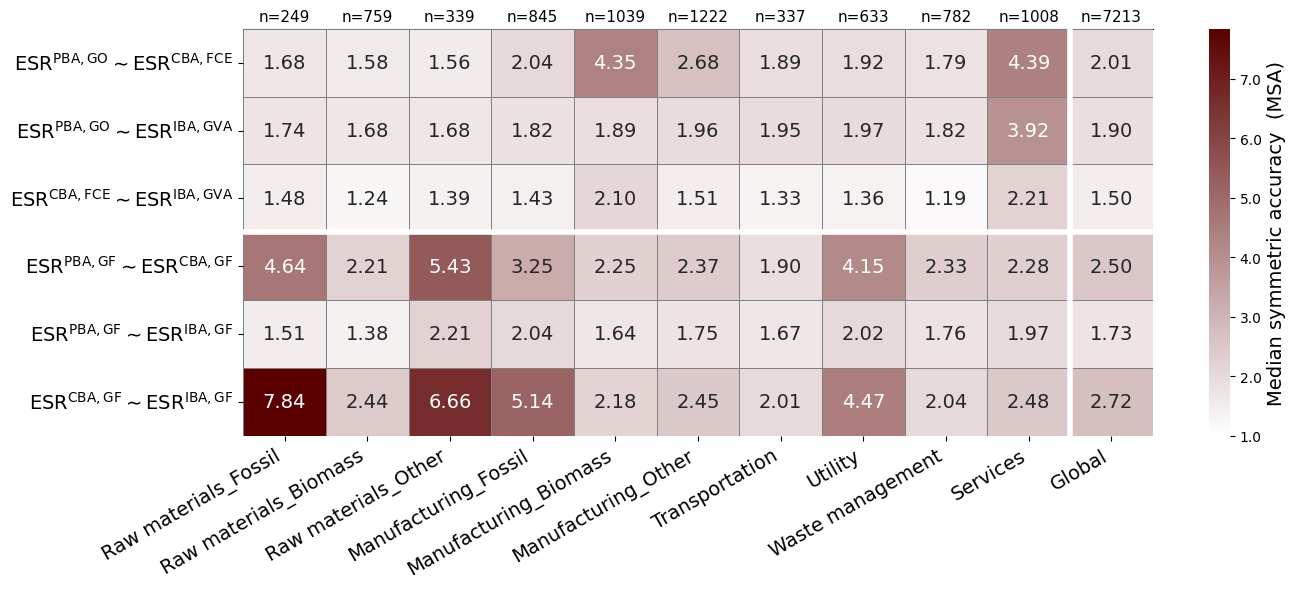

In [ ]:
# Heatmap MSA (10^MALR) (fig 6b)

esr_df = ESR_util.copy().assign(
    ESR_PBA_GF=ESR_GF['ESR_PBA_GF'],
    ESR_CBA_GF=ESR_GF['ESR_CBA_GF'],
    ESR_IBA_GF=ESR_GF['ESR_IBA_GF'],
)

esr_df['aggregated_sectors'] = esr_df.index.get_level_values(3)

sector_order = [
    'Raw materials_Fossil',
    'Raw materials_Biomass',
    'Raw materials_Other',
    'Manufacturing_Fossil',
    'Manufacturing_Biomass',
    'Manufacturing_Other',
    'Transportation',
    'Utility',
    'Waste management',
    'Services',
]
sector_order_global = sector_order + ['Global']

comparison = [("ESR_PBA_GO", "ESR_CBA_FCE"), ("ESR_PBA_GO", "ESR_IBA_GVA"), ("ESR_CBA_FCE", "ESR_IBA_GVA"), ("ESR_PBA_GF", "ESR_CBA_GF"), ("ESR_PBA_GF", "ESR_IBA_GF"), ("ESR_CBA_GF", "ESR_IBA_GF")]
comparison_labels = [
    r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{CBA,FCE}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    r'$\mathrm{ESR}^{\mathrm{CBA,FCE}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{CBA,GF}}$',
    r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
    r'$\mathrm{ESR}^{\mathrm{CBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
]

# Ensemble des variables impliquées dans au moins une comparaison
all_vars = sorted(set(v for pair in comparison for v in pair))

index = pd.MultiIndex.from_product([comparison, sector_order_global], names=['comparison', 'sector'])

MALR_results = pd.DataFrame(
    {
        'count': 0,
        'malr': np.nan,
    },
    index=index
)

# --- Étape 1 : masque commun par colonne (secteur), basé sur TOUTES les variables des comparaisons ---
common_mask_by_sector = {}
diagnostic_rows = []

for sector in sector_order_global:
    if sector == 'Global':
        subset_data = esr_df
    else:
        subset_data = esr_df[esr_df['aggregated_sectors'] == sector]

    mask_common = np.ones(len(subset_data), dtype=bool)
    for var in all_vars:
        mask_common &= np.isfinite(subset_data[var]) & (subset_data[var] >= 0)

    common_mask_by_sector[sector] = subset_data[mask_common]
    n_harmonized = mask_common.sum()

    # --- Diagnostic : n avant harmonisation, par comparaison, pour ce secteur ---
    for line in comparison:
        mask_pairwise = np.isfinite(subset_data[line[0]]) & np.isfinite(subset_data[line[1]])
        n_pairwise = mask_pairwise.sum()
        diagnostic_rows.append({
            'sector': sector,
            'comparison': f"{line[0]} vs {line[1]}",
            'n_before (pairwise)': n_pairwise,
            'n_after (harmonized)': n_harmonized,
            'n_lost': n_pairwise - n_harmonized,
        })

diagnostic_df = pd.DataFrame(diagnostic_rows)

print("=== Diagnostic : perte d'échantillon due à l'harmonisation par colonne ===")
print(diagnostic_df.to_string(index=False))

# Résumé par secteur (n_lost max sur les 6 comparaisons = perte la plus sévère visible dans la heatmap d'origine)
summary_by_sector = diagnostic_df.groupby('sector').agg(
    n_after_harmonized=('n_after (harmonized)', 'first'),
    n_before_max=('n_before (pairwise)', 'max'),
    n_before_min=('n_before (pairwise)', 'min'),
).assign(max_loss=lambda d: d['n_before_max'] - d['n_after_harmonized'])
summary_by_sector = summary_by_sector.reindex(sector_order_global)

print("\n=== Résumé par secteur ===")
print(summary_by_sector.to_string())

# --- Étape 2 : calcul du MALR sur ce même sous-échantillon pour chaque ligne ---
for (line, sector) in index:
    subset_data = common_mask_by_sector[sector]
    n_count = len(subset_data)
    MALR_results.loc[(line, sector), 'count'] = n_count

    if n_count > 0:
        x_1 = subset_data[line[0]].values
        y_2 = subset_data[line[1]].values
        log_ratio = np.log10(x_1 / y_2)
        malr = 10**(np.median(np.abs(log_ratio)))
        MALR_results.loc[(line, sector), 'malr'] = malr
    else:
        MALR_results.loc[(line, sector), 'malr'] = np.nan

data_fig6b = MALR_results.copy().reset_index()
# data_fig6b.to_excel("data_fig6b.xlsx")

malr_pivot = MALR_results['malr'].unstack(fill_value=np.nan)
count_pivot = MALR_results['count'].unstack(fill_value=0).astype(int)

malr_pivot = malr_pivot.reindex(index=comparison, columns=sector_order_global)
count_pivot = count_pivot.reindex(index=comparison, columns=sector_order_global)

annotations = np.empty_like(malr_pivot, dtype=object)
for i in range(malr_pivot.shape[0]):
    for j in range(malr_pivot.shape[1]):
        malr_val = malr_pivot.iloc[i, j]
        count_val = count_pivot.iloc[i, j]
        if np.isnan(malr_val):
            annotations[i, j] = ''
        else:
            annotations[i, j] = f"{malr_val:.2f}"

# Palette séquentielle (le MALR est positif, pas de symétrie autour de 0) : blanc -> rouge foncé
cmap_malr = mcolors.LinearSegmentedColormap.from_list(
    "white_dark_red",
    [(0.0, "#ffffff"), (1.0, "#5a0000")],
)
borne_supe_malr_scale = np.nanmax(malr_pivot.values)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    malr_pivot,
    annot=annotations,
    annot_kws={'fontsize': 14},
    fmt='',
    cmap=cmap_malr,
    ax=ax,
    vmin=1,
    vmax=borne_supe_malr_scale,  # ou une valeur fixe si vous voulez comparer plusieurs figures entre elles
    linewidths=0.5,
    linecolor='gray'
)

cbar = ax.collections[0].colorbar
cbar.set_label('Median symmetric accuracy  (MSA)', fontsize=14)
cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

ax.axhline(y=3, color='white', linewidth=4)
ax.axvline(x=malr_pivot.shape[1] - 1, color='white', linewidth=4)

# ax.set_title('Heatmap median absolute log-ratio (MALR)\n', fontsize=13, fontweight='bold')
ax.set_xticklabels(sector_order_global, fontsize=14, rotation=30, ha="right")
ax.set_yticklabels(comparison_labels, fontsize=14, rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')

# --- n= au-dessus de chaque colonne (identique sur toutes les lignes, donc on prend la 1ère) ---
ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels(
    [f"n={count_pivot[sector].iloc[0]}" for sector in sector_order_global],
    fontsize=11,
    rotation=0
)
ax_top.tick_params(length=0)  # pas de petits traits, juste le texte

plt.tight_layout()
plt.savefig("fig 6b.png", dpi=600)
plt.show()

## Proportion of the economy operating within its aCC, within the uncertainty zone, or beyond it

In [ ]:
boundary_1 = CC_GES / CC_GES
boundary_2 = CC_GES_Doka_up / CC_GES

In [ ]:
df_exceedance = df_analysis_util[['PBA_2021', 'CBA_2021', 'IBA_2021',
                                  'aCC_GO_2021', 'aCC_FCE_2021', 'aCC_GVA_2021']].join(
    df_analysis_GF[['aCC_GF (PBA, 1995)_2021', 'aCC_GF (CBA, 1995)_2021', 'aCC_GF (IBA, 1995)_2021']])

EXCEEDANCE_CONFIGS = [  # (accounting approach, sharing principle, colonne aCC)
    ('PBA', 'GO', 'aCC_GO_2021'), ('CBA', 'FCE', 'aCC_FCE_2021'), ('IBA', 'GVA', 'aCC_GVA_2021'),
    ('PBA', 'GF', 'aCC_GF (PBA, 1995)_2021'), ('CBA', 'GF', 'aCC_GF (CBA, 1995)_2021'),
    ('IBA', 'GF', 'aCC_GF (IBA, 1995)_2021')]

N  = 'Number of sectors'
S  = 'Share of the number of sectors with positive impact (%)'
R  = 'Reference (Gt CO2-eq)'
G  = 'Share of global impact of sectors with positive impact (%)'
SP = 'Special cases: share of global impact (%)'

def exceedance_stats(approach, acc_col, df=df_exceedance):
    imp, acc = df[f'{approach}_2021'], df[acc_col]
    tot, pos = imp.sum(), imp > 0
    nocap  = pos & (acc == 0)                      # impact > 0, aCC = 0  -> ESR = +inf
    ninf   = (imp < 0) & (acc == 0)                # impact < 0, aCC = 0  -> ESR = -inf
    negesr = (imp * acc) < 0                       # impact et aCC de signes opposés (aCC != 0) -> ESR < 0
    esr = (imp / acc.where(acc > 0)).where(~(acc == 0), np.inf)
    exc1, exc15 = pos & (esr > boundary_1), pos & (esr > boundary_2)
    within = pos & ~exc1
    zone   = pos & exc1 & ~exc15
    return {
        (N, 'With positive impact'): int(pos.sum()),
        (N, 'With zero impact'):                                       int((imp == 0).sum()),
        (N, 'With negative impact'):                                   int((imp < 0).sum()),
        (N, 'Positive impact, zero aCC (ESR = +inf)'):                 int(nocap.sum()),
        (N, 'Negative impact, zero aCC (ESR = -inf)'):                 int(ninf.sum()),
        (N, 'Negative ESR (impact and aCC of opposite signs)'):        int(negesr.sum()),

        (R, 'Total impact'):                               tot / 1e12,
        (R, 'Total allocated carrying capacity'):          CC_GES_Doka_low / 1e12,
        (R, 'Total high allocated carrying capacity'):     CC_GES_Doka_up / 1e12,

        (S, 'Within aCC (ESR ≤ 1)'):                                   within.sum() / pos.sum() * 100,
        (S, 'Within zone of increasing risk (1 < ESR ≤ 1.5)'):         zone.sum() / pos.sum() * 100,
        (S, 'Exceeding aCC (ESR > 1)'):                                exc1.sum() / pos.sum() * 100,
        (S, 'Exceeding high aCC (ESR > 1.5)'):                         exc15.sum() / pos.sum() * 100,

        (G, 'Within aCC (ESR ≤ 1)'):                                   (tot - imp[exc1].sum()) / tot * 100,
        (G, 'Within zone of increasing risk (1 < ESR ≤ 1.5)'):         imp[zone].sum() / tot * 100,
        (G, 'Exceeding aCC (ESR > 1)'):                                imp[exc1].sum() / tot * 100,
        (G, 'Exceeding high aCC (ESR > 1.5)'):                         imp[exc15].sum() / tot * 100,

        (SP, 'ESR = +inf (positive impact, zero aCC)'):                imp[nocap].sum() / tot * 100,
        (SP, 'ESR = -inf (negative impact, zero aCC)'):                imp[ninf].sum() / tot * 100,
        (SP, 'ESR < 0 (impact and aCC of opposite signs)'):            imp[negesr].sum() / tot * 100,
    }

esr_exceedance_summary = pd.DataFrame({(a, p): exceedance_stats(a, c) for a, p, c in EXCEEDANCE_CONFIGS})
esr_exceedance_summary.index = pd.MultiIndex.from_tuples(esr_exceedance_summary.index)   # sans noms de niveaux
esr_exceedance_summary.columns = pd.MultiIndex.from_tuples(esr_exceedance_summary.columns,
                                                           names=['Accounting approach', 'Sharing principle'])
print(esr_exceedance_summary.round(1).to_string())

# esr_exceedance_summary.to_excel("Exceedance_summary.xlsx")

Accounting approach                                                                                            PBA     CBA     IBA     PBA     CBA     IBA
Sharing principle                                                                                               GO     FCE     GVA      GF      GF      GF
Number of sectors                                          With positive impact                             8134.0  7739.0  8098.0  8134.0  7739.0  8098.0
                                                           With zero impact                                 1666.0  2061.0  1662.0  1666.0  2061.0  1662.0
                                                           With negative impact                                0.0     0.0    40.0     0.0     0.0    40.0
                                                           Positive impact, zero aCC (ESR = +inf)              0.0     0.0     0.0   266.0   438.0   278.0
                                                           Negative im

In [ ]:
def esr_categories_by_sector(df_analysis_util, df_analysis_GF, year=2021, gf_year=1995):
    """Number of sectors per ESR class, for the 6 ESR approaches x 10 sector categories (+ Global)."""
    sector = df_analysis_util.index.get_level_values("aggregated_sectors")
    rows = []
    for app, sharing, imp_col, acc_col, frame in _configs(df_analysis_util, df_analysis_GF, year, gf_year):
        imp, acc = df_analysis_util[imp_col], frame[acc_col]
        classes = _esr_classes(imp, acc)
        for cat in sector_order + ["Global"]:
            m = np.ones(len(imp), dtype=bool) if cat == "Global" else np.asarray(sector == cat)
            row = {"Accounting approach": app, "Sharing principle": sharing, "sector category": cat, "n sectors": int(m.sum())}
            row.update({k: int((v.values & m).sum()) for k, v in classes.items()})
            rows.append(row)
    out = pd.DataFrame(rows).set_index(["Accounting approach", "Sharing principle", "sector category"])
    assert (out.drop(columns="n sectors").sum(axis=1) == out["n sectors"]).all()
    return out

esr_cat_sector = esr_categories_by_sector(df_analysis_util, df_analysis_GF)
esr_cat_sector.to_excel("ESR_status_by_sector_cat.xlsx")

In [ ]:
def esr_impact_shares_by_sector(df_analysis_util, df_analysis_GF, year=2021, gf_year=1995):
    sector = df_analysis_util.index.get_level_values("aggregated_sectors")
    rows = []
    for app, sharing, imp_col, acc_col, frame in _configs(df_analysis_util, df_analysis_GF, year, gf_year):
        imp, acc = df_analysis_util[imp_col], frame[acc_col]
        tot = imp.sum()                                  # impact global de l'approche
        classes = _esr_classes(imp, acc)
        for cat in sector_order + ["Global"]:
            m = np.ones(len(imp), dtype=bool) if cat == "Global" else np.asarray(sector == cat)
            row = {"Accounting approach": app, "Sharing principle": sharing, "sector category": cat,
                   "share of global impact (%)": imp[m].sum() / tot * 100}
            row.update({k + " (% of global impact)": imp[v.values & m].sum() / tot * 100
                        for k, v in classes.items()})
            rows.append(row)
    out = pd.DataFrame(rows).set_index(["Accounting approach", "Sharing principle", "sector category"])
    assert np.allclose(out.drop(columns="share of global impact (%)").sum(axis=1),
                       out["share of global impact (%)"])
    return out

esr_impact_shares_cat_sector = esr_impact_shares_by_sector(df_analysis_util, df_analysis_GF)
esr_impact_shares_cat_sector.to_excel("ESR_impact_shares_by_sector_cat.xlsx")

## Focus on a single sector

In [ ]:
# Part of Brazil's GDP

v_4 = data_2021['v_4']
v_4_aggsec = v_4.groupby('regions').sum()
v_4_BR_vegeoil = v_4.loc['BR', 'products of Vegetable oils and fats', 'Central and South America', 'Manufacturing_Biomass']
print(v_4_BR_vegeoil / v_4_aggsec.loc['BR'])

0.004799569042339508
0.00010023606151703827
0.00021593844466556237
0.00010718669028987764
0.24582623521447564


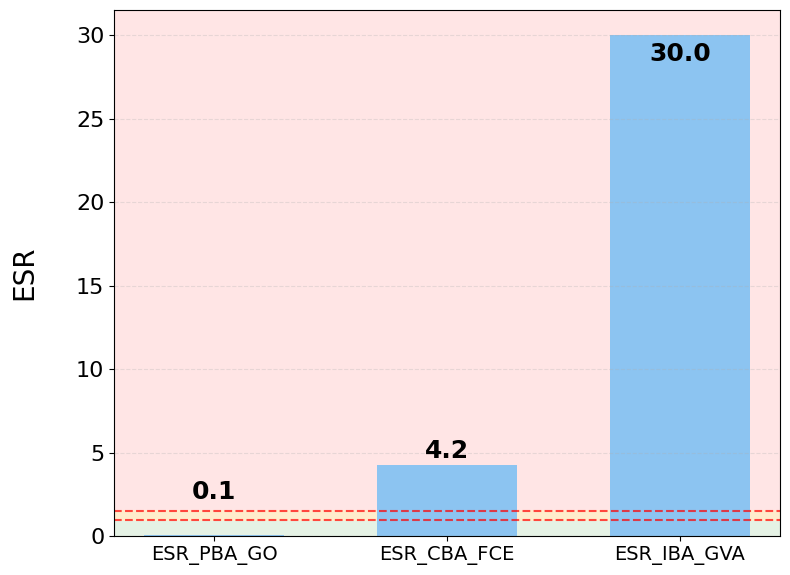

In [ ]:
# Graphique des 3 ESR EC pour le secteur étudié
sector_study_4 = ('BR', 'products of Vegetable oils and fats', 'Central and South America', 'Manufacturing_Biomass')

esr_sector = pd.DataFrame({
    'Economic contribution': [
        ESR_util.loc[sector_study_4, 'ESR_PBA_GO'],
        ESR_util.loc[sector_study_4, 'ESR_CBA_FCE'],
        ESR_util.loc[sector_study_4, 'ESR_IBA_GVA'],
    ]
    
}, index=['ESR_PBA_GO', 'ESR_CBA_FCE', 'ESR_IBA_GVA'])

fig, ax = plt.subplots(figsize=(8, 6))

values = esr_sector['Economic contribution']

if CC_GES == CC_GES_Doka_low:
    #ax.axhline(y=(CC_GES_Doka_up / CC_GES_Doka_low), color='red', linestyle='--', linewidth=1, alpha=0.7)
    rect1 = Rectangle((0.15, 0.099), 0.832, 0.018, linewidth=0, edgecolor='orange', facecolor='orange', alpha=0.2)
    fig.add_artist(rect1)
    rect2 = Rectangle((0.15, 0.073), 0.832, 0.025, linewidth=0, edgecolor='green', facecolor='green', alpha=0.1)
    fig.add_artist(rect2)
    rect3 = Rectangle((0.15, 0.117), 0.832, 0.832, linewidth=0, edgecolor='red', facecolor='red', alpha=0.1)
    fig.add_artist(rect3)

ax.set_zorder(1)             # l'axe passe devant les rectangles
ax.patch.set_visible(False)  # fond de l'axe transparent

bars = ax.bar(esr_sector.index, values, color="#8CC4F1", width=0.6)

label_positions = [22, 6, 8]
label_color = ['black', 'black', 'black']

for bar, label_y, label_c in zip(bars, label_positions, label_color):
    height = bar.get_height()
    ax.annotate(f'{height:.1f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, label_y - height),
                textcoords='offset points',
                ha='center', va='bottom', fontsize=18, weight = 'bold', color=label_c)
    
ax.set_title('')
ax.set_xlabel('')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=16)
ax.axhline(y=1, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax.axhline(y=1.5, color='red', linestyle='--', linewidth=1.5, alpha=0.7)

# rect = Rectangle((-1, 1),30 , CC_GES_Doka_up / CC_GES_Doka_low - 1, linewidth=0.1, edgecolor='orange', facecolor='orange', alpha=0.3)
# ax.add_patch(rect)

ax.set_ylabel('ESR\n', fontsize=20)
fig.suptitle("")

plt.tight_layout()
plt.savefig("fig 7.png", dpi=600)
plt.show()

In [ ]:
print(f"aCC GO for {sector_study_4[:2]}: {aCC_util.loc[sector_study_4, 'GO']:.2e}")
print(f"aCC FCE for {sector_study_4[:2]}: {aCC_util.loc[sector_study_4, 'FCE']:.2e}")
print(f"aCC GVA for {sector_study_4[:2]}: {aCC_util.loc[sector_study_4, 'GVA']:.2e}")

aCC GO for ('BR', 'products of Vegetable oils and fats'): 2.48e+09
aCC FCE for ('BR', 'products of Vegetable oils and fats'): 1.23e+09
aCC GVA for ('BR', 'products of Vegetable oils and fats'): 1.15e+09


In [ ]:
print(f"I PBA for {sector_study_4[:2]}: {AI_2021.loc[sector_study_4, 'PBA']:.2e}")
print(f"I CBA for {sector_study_4[:2]}: {AI_2021.loc[sector_study_4, 'CBA']:.2e}")
print(f"I IBA for {sector_study_4[:2]}: {AI_2021.loc[sector_study_4, 'IBA']:.2e}")

I PBA for ('BR', 'products of Vegetable oils and fats'): 2.55e+08
I CBA for ('BR', 'products of Vegetable oils and fats'): 5.24e+09
I IBA for ('BR', 'products of Vegetable oils and fats'): 3.46e+10


In [ ]:
# Analyse de contribution (SPA) - CBA (2021)
sector_study_4 = ('BR', 'products of Vegetable oils and fats', 'Central and South America', 'Manufacturing_Biomass')
sector_study_2 = ('BR', 'products of Vegetable oils and fats')

y_i = data_2021['Y_total'].loc[sector_study_2]

A_power = np.eye(len(data_2021['x']))
paths_by_order_CBA = {}
max_order = 10

for n in range(max_order + 1):
    if n > 0:
        A_power = A_power.dot(data_2021['A'].values)
    # colonne i de A^n : ce que chaque secteur j doit fournir (direct + n étapes)
    # pour produire une unité destinée à la demande finale du secteur source i
    contrib_n = data_2021['J'].values * A_power[:, data_2021['A'].index.get_loc(sector_study_2)] * y_i
    paths_by_order_CBA[n] = pd.Series(contrib_n, index=data_2021['A'].index)

total_by_order_CBA = pd.DataFrame(paths_by_order_CBA).sum(axis=0)
cumulative_CBA = total_by_order_CBA.cumsum()
result_CBA = cumulative_CBA / cumulative_CBA.iloc[-1]
print(result_CBA)

df_paths_by_order_CBA = pd.DataFrame(paths_by_order_CBA, index=index_4)
df_paths_by_order_CBA.columns = [f'order_{n}' for n in df_paths_by_order_CBA.columns]
I_amont_sector = AI_2021['CBA'].loc[sector_study_4]
print((I_amont_sector - df_paths_by_order_CBA.sum().sum()) / I_amont_sector * 100)

0     0.011975
1     0.426183
2     0.732733
3     0.871930
4     0.938323
5     0.969703
6     0.984951
7     0.992642
8     0.996655
9     0.998811
10    1.000000
dtype: float64
0.16091150579088612


In [ ]:
# Analyse de contribution (SPA) - IBA (2021)
sector_study_4 = ('BR', 'products of Vegetable oils and fats', 'Central and South America', 'Manufacturing_Biomass')
sector_study_2 = ('BR', 'products of Vegetable oils and fats')

v_i = data_2021['v'].loc[sector_study_2]

B_power = np.eye(len(data_2021['x']))
paths_by_order_IBA = {}
max_order = 10

for n in range(max_order + 1):
    if n > 0:
        B_power = B_power.dot(data_2021['B'].values)
    # émissions générées à chaque secteur j, induites par la VA fournie par la source i,
    # via n étapes de ventes successives
    contrib_n = v_i * B_power[data_2021['B'].index.get_loc(sector_study_2), :] * data_2021['J'].values
    paths_by_order_IBA[n] = pd.Series(contrib_n, index=data_2021['B'].columns)
total_by_order_IBA = pd.DataFrame(paths_by_order_IBA).sum(axis=0)
cumulative_IBA = total_by_order_IBA.cumsum()
result_IBA = cumulative_IBA / cumulative_IBA.iloc[-1]
print(result_IBA)

df_paths_by_order_IBA = pd.DataFrame(paths_by_order_IBA, index=index_4)
df_paths_by_order_IBA.columns = [f'order_{n}' for n in df_paths_by_order_IBA.columns]
I_aval_sector = AI_2021['IBA'].loc[sector_study_4]
print((I_aval_sector - df_paths_by_order_IBA.sum().sum()) / I_aval_sector * 100)

0     0.001691
1     0.786957
2     0.946802
3     0.980491
4     0.990865
5     0.995274
6     0.997463
7     0.998660
8     0.999349
9     0.999757
10    1.000000
dtype: float64
0.038634344526406


Impact non couvert par l'analyse de contribution : 0.161%
Contents of df_top_pct:
                                                     order_0    order_1  \
(BR, Oil seeds, Central and South America, Raw ...  0.000000  20.526636   
(BR, Raw milk, Central and South America, Raw m...  0.000000   0.000769   
(BR, Food waste for treatment: landfill, Centra...  0.000000   3.827061   
(BR, Electricity by gas, Central and South Amer...  0.000000   0.842245   
(BR, Dairy products, Central and South America,...  0.000000   2.079314   
(BR, Electricity by petroleum and other oil der...  0.000000   0.545889   
(BR, Cereal grains nec, Central and South Ameri...  0.000000   0.014418   
(BR, Sea and coastal water transportation servi...  0.000000   1.155297   
(Other, Other)                                      1.195581  12.362536   

                                                      order_2   order_3  \
(BR, Oil seeds, Central and South America, Raw ...   2.350154  0.388193   
(BR, Raw milk, Ce

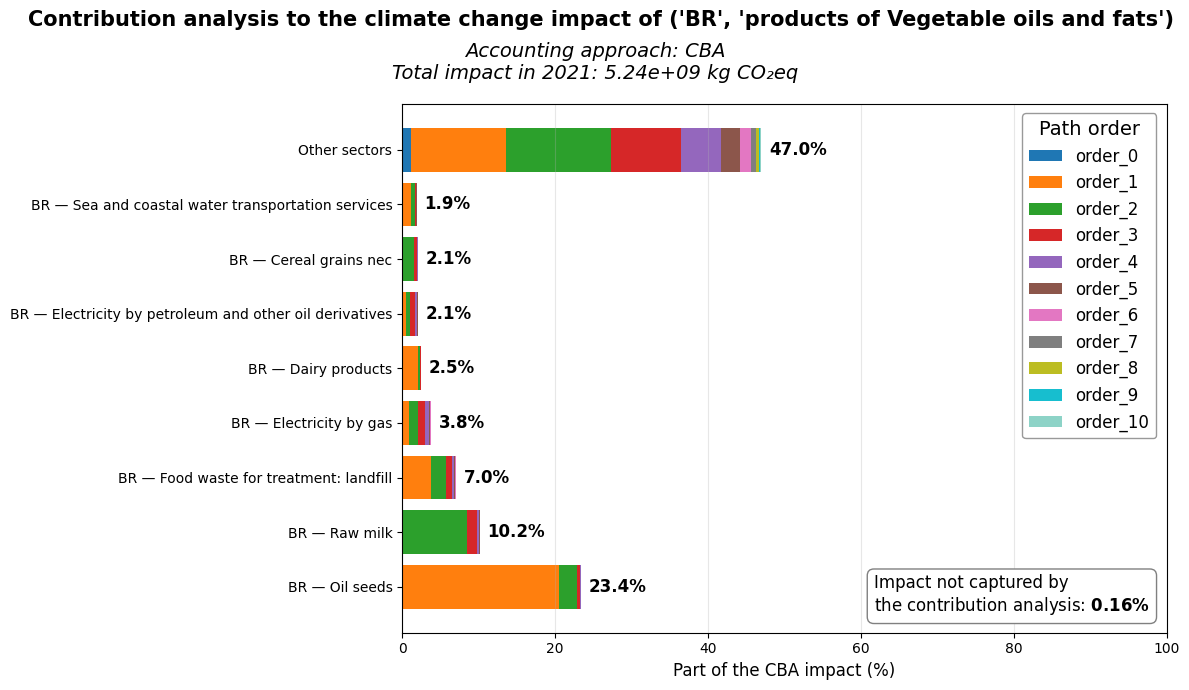

In [ ]:
# Figure S97 - Contribution analysis - CBA (2021)

top_n = 8
top_sectors = df_paths_by_order_CBA.sum(axis=1).sort_values(ascending=False).head(top_n).index
df_top = df_paths_by_order_CBA.loc[top_sectors]
other_sum = df_paths_by_order_CBA.loc[~df_paths_by_order_CBA.index.isin(top_sectors)].sum(axis=0)

# Référence: somme totale de tous les chemins identifiés
impact_ref = AI_2021['CBA'].loc[sector_study_4]

# Part de l'impact total non couverte par les chemins identifiés
impact_covered = df_paths_by_order_CBA.sum().sum()
missing_pct = (impact_ref - impact_covered) / impact_ref * 100
print(f"Impact non couvert par l'analyse de contribution : {missing_pct:.3f}%")

# Ajouter une ligne "Autres" pour les secteurs non top 12
df_top_with_other = pd.concat([df_top, pd.DataFrame([other_sum], index=[('Other', 'Other')])], axis=0)
df_top_pct = (df_top_with_other / impact_ref * 100).replace([np.inf, -np.inf], np.nan).fillna(0)

# Check the contents of df_top_pct before plotting
print("Contents of df_top_pct:")
print(df_top_pct)

# Check the total impact reference
print("Total impact reference:", impact_ref)

labels = [f"{idx[0]} — {idx[1]}" if idx != ('Other', 'Other') else "Other sectors" for idx in df_top_pct.index]

fig, ax = plt.subplots(figsize=(12, 7))
bottom = np.zeros(len(df_top_pct))
colors = plt.cm.tab10(np.linspace(0, 1, min(10, df_top_pct.shape[1])))
if df_top_pct.shape[1] > 10:
    colors_extra = plt.cm.Set3(np.linspace(0, 1, df_top_pct.shape[1] - 10))
    colors = np.vstack([colors, colors_extra])

for i, col in enumerate(df_top_pct.columns):
    ax.barh(labels, df_top_pct[col].values, left=bottom, label=col, color=colors[i])
    bottom += df_top_pct[col].values

# Ajouter les % au bout des barres
for j, label in enumerate(labels):
    total_pct = bottom[j]
    if total_pct > 1:
        ax.text(total_pct + 1, j, f'{total_pct:.1f}%', va='center', fontsize=12, fontweight='bold')

ax.set_xlabel("Part of the CBA impact (%)", fontsize=12)
ax.set_title(f"Contribution analysis to the climate change impact of {sector_study_2}\n\n\n", fontsize=15, fontweight='bold', x=0.26)
fig.text(0.5, 0.88, f"Accounting approach: CBA\nTotal impact in 2021: {impact_ref:,.2e} kg CO₂eq", ha='center', fontsize=14, style='italic')
ax.legend(title="Path order", bbox_to_anchor=(0.8, 0.998), loc='upper left', fontsize=12, title_fontsize=14, edgecolor='gray')
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, max(100, bottom.max() * 1.1))

ax.text(
    0.617, 0.03,
    f"Impact not captured by\nthe contribution analysis: $\\mathbf{{{missing_pct:.2f}\\%}}$",
    transform=ax.transAxes,
    ha='left', va='bottom', fontsize=12,
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', linewidth=1)
)

plt.tight_layout()
plt.savefig("decomposition_ordre_cba_pct.png", dpi=150)
plt.show()

Impact non couvert par l'analyse de contribution : 0.039%


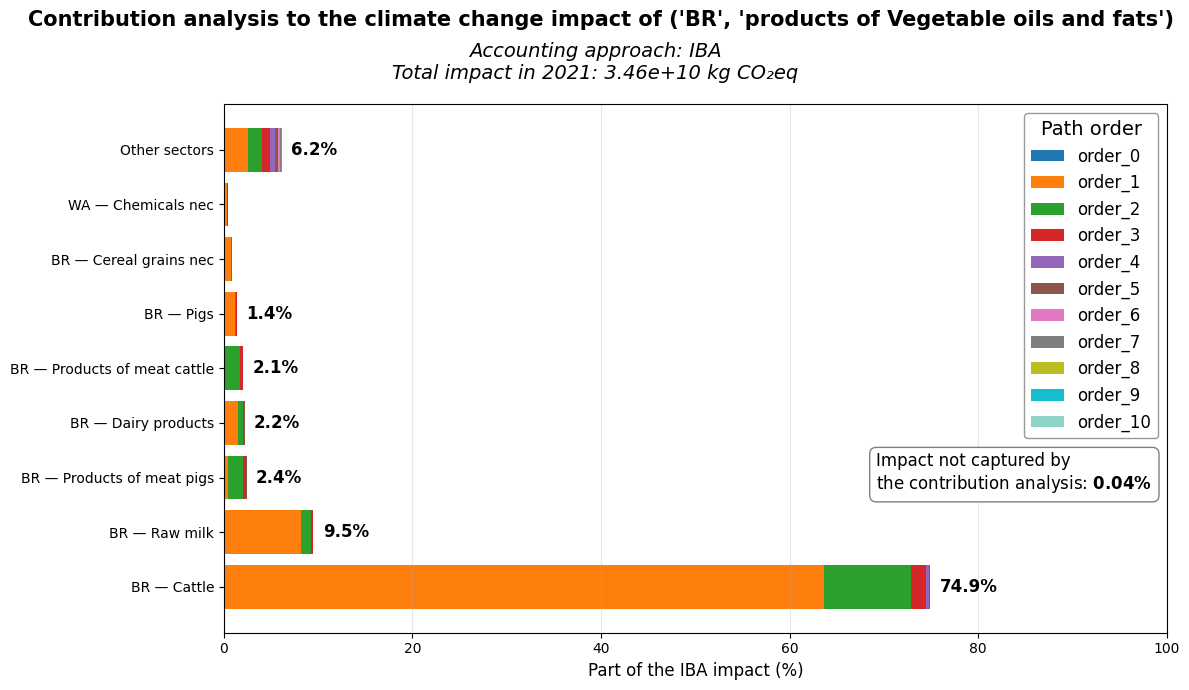

In [ ]:
# Figure S98 - Contribution analysis - IBA (2021)

top_n = 8
top_sectors = df_paths_by_order_IBA.sum(axis=1).sort_values(ascending=False).head(top_n).index
df_top = df_paths_by_order_IBA.loc[top_sectors]
other_sum = df_paths_by_order_IBA.loc[~df_paths_by_order_IBA.index.isin(top_sectors)].sum(axis=0)

# Référence: somme totale de tous les chemins identifiés
impact_ref = AI_2021['IBA'].loc[sector_study_4]

# Part de l'impact total non couverte par les chemins identifiés
impact_covered = df_paths_by_order_IBA.sum().sum()
missing_pct = (impact_ref - impact_covered) / impact_ref * 100
print(f"Impact non couvert par l'analyse de contribution : {missing_pct:.3f}%")

# Ajouter une ligne "Autres" pour les secteurs non top 12
df_top_with_other = pd.concat([df_top, pd.DataFrame([other_sum], index=[('Other', 'Other')])], axis=0)
df_top_pct = (df_top_with_other / impact_ref * 100).replace([np.inf, -np.inf], np.nan).fillna(0)

labels = [f"{idx[0]} — {idx[1]}" if idx != ('Other', 'Other') else "Other sectors" for idx in df_top_pct.index]

fig, ax = plt.subplots(figsize=(12, 7))
bottom = np.zeros(len(df_top_pct))
colors = plt.cm.tab10(np.linspace(0, 1, min(10, df_top_pct.shape[1])))
if df_top_pct.shape[1] > 10:
    colors_extra = plt.cm.Set3(np.linspace(0, 1, df_top_pct.shape[1] - 10))
    colors = np.vstack([colors, colors_extra])

for i, col in enumerate(df_top_pct.columns):
    ax.barh(labels, df_top_pct[col].values, left=bottom, label=col, color=colors[i])
    bottom += df_top_pct[col].values

# Ajouter les % au bout des barres
for j, label in enumerate(labels):
    total_pct = bottom[j]
    if total_pct > 1:
        ax.text(total_pct + 1, j, f'{total_pct:.1f}%', va='center', fontsize=12, fontweight='bold')

ax.set_xlabel("Part of the IBA impact (%)", fontsize=12)
ax.set_title(f"Contribution analysis to the climate change impact of {sector_study_2}\n\n\n", fontsize=15, fontweight='bold', x=0.4)
fig.text(0.5, 0.88, f"Accounting approach: IBA\nTotal impact in 2021: {impact_ref:,.2e} kg CO₂eq", ha='center', fontsize=14, style='italic')
ax.legend(title="Path order", bbox_to_anchor=(0.84, 0.998), loc='upper left', fontsize=12, title_fontsize=14, edgecolor='gray')
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, max(100, bottom.max() * 1.1))

ax.text(
    0.692, 0.26,
    f"Impact not captured by\nthe contribution analysis: $\\mathbf{{{missing_pct:.2f}\\%}}$",
    transform=ax.transAxes,
    ha='left', va='bottom', fontsize=12,
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='gray', linewidth=1)
)

plt.tight_layout()
plt.savefig("decomposition_ordre_iba_pct.png", dpi=150)
plt.show()

# SM

## Sensitivity analysis

### Function definition

In [ ]:
def make_col_name_EC (var, year):
    return f"{var}_{year}"

def make_col_name_GF(var, short, GF_year, study_year):
    return f"{var} ({short}, {GF_year})_{study_year}"

In [ ]:
df_plot = np.log10(df_analysis_util.copy())
data_plot_sensi_EC = pd.concat([
    df_plot['ESR_PBA_GO_2018'],
    df_plot['ESR_CBA_FCE_2018'],
    df_plot['ESR_IBA_GVA_2018'],
    df_plot['ESR_PBA_GO_2019'],
    df_plot['ESR_CBA_FCE_2019'],
    df_plot['ESR_IBA_GVA_2019'],
    df_plot['ESR_PBA_GO_2020'],
    df_plot['ESR_CBA_FCE_2020'],
    df_plot['ESR_IBA_GVA_2020'],
    df_plot['ESR_PBA_GO_2021'],
    df_plot['ESR_CBA_FCE_2021'],
    df_plot['ESR_IBA_GVA_2021'],
    df_plot['ESR_PBA_GO_2022'],
    df_plot['ESR_CBA_FCE_2022'],
    df_plot['ESR_IBA_GVA_2022']
], axis=1).replace([np.inf, -np.inf], np.nan)

df_plot = np.log10(df_analysis_GF.copy())

data_plot_sensi_GF = pd.concat([
    df_plot['ESR_PBA_GF (PBA, 1995)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2018'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2019'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2020'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2021'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2022'],

], axis=1).replace([np.inf, -np.inf], np.nan)

In [ ]:
df_plot = df_analysis_util.copy()

data_plot_sensi_HM_EC = pd.concat([
    df_plot['ESR_PBA_GO_2018'],
    df_plot['ESR_CBA_FCE_2018'],
    df_plot['ESR_IBA_GVA_2018'],
    df_plot['ESR_PBA_GO_2019'],
    df_plot['ESR_CBA_FCE_2019'],
    df_plot['ESR_IBA_GVA_2019'],
    df_plot['ESR_PBA_GO_2020'],
    df_plot['ESR_CBA_FCE_2020'],
    df_plot['ESR_IBA_GVA_2020'],
    df_plot['ESR_PBA_GO_2021'],
    df_plot['ESR_CBA_FCE_2021'],
    df_plot['ESR_IBA_GVA_2021'],
    df_plot['ESR_PBA_GO_2022'],
    df_plot['ESR_CBA_FCE_2022'],
    df_plot['ESR_IBA_GVA_2022']
], axis=1).replace([np.inf, -np.inf], np.nan)

df_plot = df_analysis_GF.copy()

data_plot_HM_GF = pd.concat([
    df_plot['ESR_PBA_GF (PBA, 1995)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2018'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2018'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2018'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2018'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2019'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2019'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2019'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2019'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2020'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2020'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2020'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2020'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2021'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2021'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2021'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2021'],

    df_plot['ESR_PBA_GF (PBA, 1995)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1995)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1995)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1996)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1996)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1996)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1997)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1997)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1997)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1998)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1998)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1998)_2022'],
    df_plot['ESR_PBA_GF (PBA, 1999)_2022'],
    df_plot['ESR_CBA_GF (CBA, 1999)_2022'],
    df_plot['ESR_IBA_GF (IBA, 1999)_2022'],

], axis=1).replace([np.inf, -np.inf], np.nan)

In [ ]:
def plot_global_sensi_distr_EC():

    years = [2018, 2019, 2020, 2021, 2022]
    value_vars = ["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]
    indicator_labels = ["PBA_GO", "CBA_FCE", "IBA_GVA"]
    indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]

    # construire data_by_indicator_year : pour chaque config, une valeur (array) par année
    # = l'ensemble des ~9800 ESR pays-secteur pour cette année, sans découpage sectoriel
    data_by_indicator_year = pd.DataFrame(
        {
            var: [
                (s := data_plot_sensi_EC[f"{var}_{year}"])[np.isfinite(s)]
                for year in years
            ]
            for var in value_vars
        },
        index=years
    )

    # Positions des boxplots (3 par année)
    base = np.arange(len(years)) * 4
    offsets = [-0.8, 0.0, 0.8]

    fig, ax = plt.subplots(figsize=(12, 8))

    ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)

    # Fenêtre de visualisation
    borne_inf = -1.5
    borne_sup = 2.5
    ax.set_ylim(borne_inf, borne_sup)

    if CC_GES == CC_GES_Doka_low:
        ax.axhline(y=np.log10(CC_GES_Doka_up / CC_GES_Doka_low), color='red', linestyle='--', linewidth=1, alpha=0.7)
        rect1 = Rectangle((-1.3, 0), 18.58, np.log10(CC_GES_Doka_up / CC_GES_Doka_low), linewidth=0, edgecolor='orange', facecolor='orange', alpha=0.2)
        ax.add_patch(rect1)
        rect2 = Rectangle((-1.3, 0), 18.58, borne_inf, linewidth=0, edgecolor='green', facecolor='green', alpha=0.1)
        ax.add_patch(rect2)
        rect3 = Rectangle((-1.3, 0.17), 18.58, borne_sup, linewidth=0, edgecolor='red', facecolor='red', alpha=0.1)
        ax.add_patch(rect3)


    for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
        positions = base + offsets[i]
        ax.boxplot(
            data_by_indicator_year[var],
            positions=positions,
            widths=0.6,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
            medianprops=dict(color=color, linewidth=2),
            whiskerprops=dict(color=color, linewidth=2),
            capprops=dict(color=color, linewidth=2),
            whis=(5, 95)
        )

    # Axes
    ax.set_xticks(base)
    ax.set_xticklabels(years, fontsize=18)
    ax.set_xlabel("")
    ax.set_yscale("linear")
    ax.set_ylabel("log10(ESR)", fontsize=18)
    ax.set_title("ESR global distributions, case of economic contribution-based sharing principles\n\n\n\n", fontsize=16, weight='bold')
    fig.text(0.5, 0.93, "Study reference years: 2018 → 2022", ha='center', fontsize=14, style='italic')
    ax.grid(axis="y", alpha=0.3, linestyle="--")


    # Nombre de points affichés dans la fenêtre de visualisation
    window_min, window_max = borne_inf, borne_sup
    points_in_window = 0
    total_points = 0
    for var in value_vars:
        for vals in data_by_indicator_year[var]:
            total_points += len(vals)
            if len(vals) > 0:
                points_in_window += np.count_nonzero((vals >= window_min) & (vals <= window_max))

    # Légende indicateurs
    legend_handles = [Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl) for c, lbl in zip(indicator_colors, indicator_labels)]
    fig.legend(handles=legend_handles, title="", bbox_to_anchor=(0.73, 0.91), loc="upper right", fontsize=15, ncol=3)

    rect4 = Rectangle((10.5, -1.4), 3, 3.7, linewidth=1.5, linestyle='--', edgecolor='black', facecolor='None', alpha=1)
    ax.add_patch(rect4)
    ax.add_artist(plt.text(11.0, 2.35, f"in manuscript", fontsize=12, style='italic', color='black'))

    plt.tight_layout()
    plt.show()


In [ ]:
def plot_global_sensi_distr_GF():

    value_vars = ["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]
    indicator_labels = ["PBA_GF", "CBA_GF", "IBA_GF"]
    indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]
    indicator_short = ["PBA", "CBA", "IBA"]

    couples = Liste_couples_années_2

    data_by_indicator_year = pd.DataFrame(
        {
            var: [
                (s := data_plot_sensi_GF[make_col_name_GF(var, short, GF_year, study_year)])[np.isfinite(s)]
                for (GF_year, study_year) in couples
            ]
            for var, short in zip(value_vars, indicator_short)
        },
        index=pd.MultiIndex.from_tuples(couples, names=['ref_year', 'study_year'])
    )

    # Regrouper les couples par année de référence (grandfathering)
    GF_years = sorted(set(gf for (gf, sy) in couples))  # ex. [1995, 1996, 1997, 1998, 1999]
    study_years_by_gf = {
        gf: [sy for (g, sy) in couples if g == gf] for gf in GF_years
    }
    # Fenêtre de visualisation
    borne_inf = -1.5
    borne_sup = 2.5

    fig, axes = plt.subplots(len(GF_years), 1, figsize=(10, 4 * len(GF_years)), sharex=True, sharey=True)

    for ax, gf_year in zip(axes, GF_years):

        ax.set_ylim(borne_inf, borne_sup)

        ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)

        if CC_GES == CC_GES_Doka_low:
            ax.axhline(y=np.log10(CC_GES_Doka_up / CC_GES_Doka_low), color='red', linestyle='--', linewidth=1, alpha=0.7)
            rect1 = Rectangle((-1.3, 0), 18.58, np.log10(CC_GES_Doka_up / CC_GES_Doka_low), linewidth=0, edgecolor='orange', facecolor='orange', alpha=0.2)
            ax.add_patch(rect1)
            rect2 = Rectangle((-1.3, 0), 18.58, borne_inf, linewidth=0, edgecolor='green', facecolor='green', alpha=0.1)
            ax.add_patch(rect2)
            rect3 = Rectangle((-1.3, 0.17), 18.58, borne_sup, linewidth=0, edgecolor='red', facecolor='red', alpha=0.1)
            ax.add_patch(rect3)

        study_years = study_years_by_gf[gf_year]
        n_groups = len(study_years)
        base = np.arange(n_groups) * 4
        offsets = [-0.8, 0.0, 0.8]

        for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
            positions = base + offsets[i]
            box_data = [data_by_indicator_year.loc[(gf_year, sy), var] for sy in study_years]
            ax.boxplot(
                box_data,
                positions=positions,
                widths=0.6,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
                medianprops=dict(color=color, linewidth=2),
                whiskerprops=dict(color=color, linewidth=2),
                capprops=dict(color=color, linewidth=2),
                whis=(5, 95)
            )

        ax.set_xticks(base)
        ax.set_xticklabels(study_years, fontsize=18)
        ax.set_ylabel(f"log10(ESR)\nGF year: {gf_year}", fontsize=14)
        ax.grid(axis="y", alpha=0.3, linestyle="--")


    axes[-1].set_xlabel("")
    fig.suptitle("ESR global distributions, case of acquired rights-based sharing principles", 
                fontsize=16, weight='bold', y=0.995)

    fig.text(0.5, 0.975, "Grandfathering reference years: 1995 → 1999, study reference years: 2018 → 2022", ha='center', fontsize=14, style='italic')

    legend_handles = [Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl) 
                    for c, lbl in zip(indicator_colors, indicator_labels)]
    fig.legend(handles=legend_handles, title="", bbox_to_anchor=(0.8, 0.97), loc="upper right", fontsize=15, ncol=3)

    rect4 = Rectangle((0.67, 0.791), 0.13, 0.15, linewidth=1.5, linestyle='--', edgecolor='black', facecolor='None', alpha=1)
    fig.add_artist(rect4)
    fig.text(0.676, 0.782, f"in manuscript", fontsize=12, style='italic', color='black')


    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

In [ ]:
def plot_global_sensi_HM_spear_EC():
    # Heatmap Spearman coefficient (fig 6) — par année, échantillon harmonisé par colonne

    years = [2018, 2019, 2020, 2021, 2022]

    comparison = [("ESR_PBA_GO", "ESR_CBA_FCE"), ("ESR_PBA_GO", "ESR_IBA_GVA"), ("ESR_CBA_FCE", "ESR_IBA_GVA")]
    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{CBA,FCE}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,FCE}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    ]

    # Ensemble des variables impliquées dans au moins une comparaison
    all_vars = sorted(set(v for pair in comparison for v in pair))

    index = pd.MultiIndex.from_product([comparison, years], names=['comparison', 'year'])

    Regr_results = pd.DataFrame(
        {
            'count': 0,
            'spearman': np.nan,
            'p-value': np.nan
        },
        index=index
    )

    # --- Étape 1 : masque commun par colonne (année), basé sur TOUTES les variables des comparaisons ---
    common_mask_by_year = {}
    diagnostic_rows = []

    for year in years:

        # --- 3 ESR Economic Contribution ---
        ec_cols = [
            f'ESR_PBA_GO_{year}',
            f'ESR_CBA_FCE_{year}',
            f'ESR_IBA_GVA_{year}'
        ]

        # --- 3 ESR Grandfathering ---
        gf_cols = [
            f'ESR_PBA_GF (PBA, 1995)_{year}',
            f'ESR_CBA_GF (CBA, 1995)_{year}',
            f'ESR_IBA_GF (IBA, 1995)_{year}'
        ]

        # Masque EC : les 3 ESR doivent être disponibles
        mask_EC = (data_plot_sensi_HM_EC[ec_cols].notna().all(axis=1) & data_plot_sensi_HM_EC[ec_cols].ge(0).all(axis=1))

        # Masque GF : les 3 ESR doivent être disponibles
        mask_GF = (data_plot_HM_GF[gf_cols].notna().all(axis=1) & data_plot_HM_GF[gf_cols].ge(0).all(axis=1))

        # Masque final : les 6 ESR doivent être disponibles
        mask_common = mask_EC & mask_GF

        common_mask_by_year[year] = data_plot_sensi_HM_EC.loc[mask_common]

        n_harmonized = mask_common.sum()

        # Diagnostic
        for line in comparison:
            col_1 = f"{line[0]}_{year}"
            col_2 = f"{line[1]}_{year}"

            mask_pairwise = (
                data_plot_sensi_HM_EC[col_1].notna()
                & data_plot_sensi_HM_EC[col_2].notna()
            )

            n_pairwise = mask_pairwise.sum()

            diagnostic_rows.append({
                'year': year,
                'comparison': f"{line[0]} vs {line[1]}",
                'n_before (pairwise)': n_pairwise,
                'n_after (harmonized)': n_harmonized,
                'n_lost': n_pairwise - n_harmonized,
            })

    diagnostic_df = pd.DataFrame(diagnostic_rows)

    # --- Étape 2 : calcul du Spearman sur ce même sous-échantillon pour chaque ligne ---
    for (line, year) in index:
        subset_data = common_mask_by_year[year]
        col_1 = f"{line[0]}_{year}"
        col_2 = f"{line[1]}_{year}"

        n_count = len(subset_data)
        Regr_results.loc[(line, year), 'count'] = n_count

        if n_count > 1:
            x_1 = subset_data[col_1].values
            y_2 = subset_data[col_2].values
            rho, p_value = stats.spearmanr(x_1, y_2, nan_policy='omit')
            Regr_results.loc[(line, year), 'spearman'] = rho
            Regr_results.loc[(line, year), 'p-value'] = p_value
        else:
            Regr_results.loc[(line, year), 'spearman'] = np.nan
            Regr_results.loc[(line, year), 'p-value'] = np.nan

    data_fig6 = Regr_results.copy().reset_index()
    # data_fig6.to_excel("data_fig6.xlsx")

    spearman_pivot = Regr_results['spearman'].unstack(fill_value=np.nan)
    count_pivot = Regr_results['count'].unstack(fill_value=0).astype(int)

    spearman_pivot = spearman_pivot.reindex(index=comparison, columns=years)
    count_pivot = count_pivot.reindex(index=comparison, columns=years)

    annotations = np.empty_like(spearman_pivot, dtype=object)
    for i in range(spearman_pivot.shape[0]):
        for j in range(spearman_pivot.shape[1]):
            rho_val = spearman_pivot.iloc[i, j]
            count_val = count_pivot.iloc[i, j]
            if np.isnan(rho_val):
                annotations[i, j] = ''
            else:
                annotations[i, j] = f"{rho_val:.2f}"

    cmap_focus = mcolors.LinearSegmentedColormap.from_list(
        "dark_red_white_blue",
        [(0.0, "#af7800"), (0.5, "#ffffff"), (1.0, "#00004d")],
    )

    fig, ax = plt.subplots(figsize=(8, 3))
    sns.heatmap(
        spearman_pivot,
        annot=annotations,
        fmt='',
        cmap=cmap_focus,
        ax=ax,
        annot_kws={"fontsize": 14},
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        linecolor='gray'
    )

    cbar = ax.collections[0].colorbar
    cbar.set_label('Spearman coefficient (ρ)', fontsize=12)
    cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

    ax.set_xticklabels(years, rotation=0, ha="center", fontsize=14)
    ax.set_yticklabels(comparison_labels, rotation=0, fontsize=14)
    ax.set_xlabel('', fontsize=11, fontweight='bold')
    ax.set_ylabel('', fontsize=11, fontweight='bold')
    ax.set_title("Global Spearman correlation of ESR values,\ncase of ESR calculated with economic contribution-based sharing principles\n\n", fontsize=12, weight='bold', x=0.3)
    fig.text(0.45, 0.75, "Study reference years: 2018 → 2022", ha='center', fontsize=12, style='italic')
    ax.axvline(x=spearman_pivot.shape[1] - 1, color='white', linewidth=4)
    ax.axvline(x=spearman_pivot.shape[1] - 2, color='white', linewidth=4)
    ax.axvline(x=spearman_pivot.shape[1] - 3, color='white', linewidth=4)
    ax.axvline(x=spearman_pivot.shape[1] - 4, color='white', linewidth=4)

    ax_top = ax.secondary_xaxis('top')
    ax_top.set_xticks(ax.get_xticks())
    ax_top.set_xticklabels(
        [f"n={count_pivot[year].iloc[0]}" for year in years],
        fontsize=11,
        rotation=0
    )
    ax_top.tick_params(length=0)  # pas de petits traits, juste le texte

    rect4 = Rectangle((0.632, 0.03), 0.108, 0.66, linewidth=1.5, linestyle='--', edgecolor='black', facecolor='None', alpha=1, zorder=5)
    fig.add_artist(rect4)
    ax.add_artist(plt.text(3.2, -0.7, f"in manuscript", fontsize=10, style='italic', color='black'))

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_global_sensi_HM_spear_GF():
    # Heatmap Spearman coefficient (fig 6) — GF
    # 5 années de référence GF, une heatmap par année

    years = [2018, 2019, 2020, 2021, 2022]
    reference_years = [1995, 1996, 1997, 1998, 1999]

    comparison = [
        ("ESR_PBA_GF", "ESR_CBA_GF"),
        ("ESR_PBA_GF", "ESR_IBA_GF"),
        ("ESR_CBA_GF", "ESR_IBA_GF")
    ]

    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{CBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
    ]


    fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(8, 12))

    for ax, ref_year in zip(axes, reference_years):

        # Ensemble des variables impliquées dans les comparaisons
        all_vars = sorted(set(v for pair in comparison for v in pair))

        index = pd.MultiIndex.from_product(
            [comparison, years],
            names=['comparison', 'year']
        )

        Regr_results = pd.DataFrame(
            {
                'count': 0,
                'spearman': np.nan,
                'p-value': np.nan
            },
            index=index
        )

        # --------------------------------------------------------
        # Étape 1 : masque commun par colonne (année)
        # --------------------------------------------------------

        common_mask_by_year = {}
        diagnostic_rows = []

        for year in years:

            # --- 3 ESR Economic Contribution ---
            ec_cols = [
                f'ESR_PBA_GO_{year}',
                f'ESR_CBA_FCE_{year}',
                f'ESR_IBA_GVA_{year}'
            ]

            # --- 3 ESR Grandfathering ---
            gf_cols = [
                f'ESR_PBA_GF (PBA, {ref_year})_{year}',
                f'ESR_CBA_GF (CBA, {ref_year})_{year}',
                f'ESR_IBA_GF (IBA, {ref_year})_{year}'
            ]

            mask_EC = (
                data_plot_sensi_HM_EC[ec_cols].notna().all(axis=1)
                & data_plot_sensi_HM_EC[ec_cols].ge(0).all(axis=1)
            )

            mask_GF = (
                data_plot_HM_GF[gf_cols].notna().all(axis=1)
                & data_plot_HM_GF[gf_cols].ge(0).all(axis=1)
            )

            mask_common = mask_EC & mask_GF
            common_mask_by_year[year] = data_plot_HM_GF.loc[mask_common]
            n_harmonized = mask_common.sum()

            # Diagnostic
            for line in comparison:

                name = {
                    "ESR_PBA_GF": "PBA",
                    "ESR_CBA_GF": "CBA",
                    "ESR_IBA_GF": "IBA"
                }

                col_1 = f"{line[0]} ({name[line[0]]}, {ref_year})_{year}"
                col_2 = f"{line[1]} ({name[line[1]]}, {ref_year})_{year}"

                mask_pairwise = (
                    data_plot_HM_GF[col_1].notna()
                    & data_plot_HM_GF[col_2].notna()
                    & data_plot_HM_GF[col_1].ge(0)
                    & data_plot_HM_GF[col_2].ge(0)
                )

                n_pairwise = mask_pairwise.sum()

                diagnostic_rows.append({
                    'year': year,
                    'comparison': f"{line[0]} vs {line[1]}",
                    'n_before (pairwise)': n_pairwise,
                    'n_after (harmonized)': n_harmonized,
                    'n_lost': n_pairwise - n_harmonized,
                })

        diagnostic_df = pd.DataFrame(diagnostic_rows)

        # --------------------------------------------------------
        # Étape 2 : calcul du Spearman
        # --------------------------------------------------------

        for (line, year) in index:

            subset_data = common_mask_by_year[year]

            name = {
                "ESR_PBA_GF": "PBA",
                "ESR_CBA_GF": "CBA",
                "ESR_IBA_GF": "IBA"
            }

            col_1 = f"{line[0]} ({name[line[0]]}, {ref_year})_{year}"
            col_2 = f"{line[1]} ({name[line[1]]}, {ref_year})_{year}"

            n_count = len(subset_data)

            Regr_results.loc[(line, year), 'count'] = n_count

            if n_count > 1:

                x_1 = subset_data[col_1].values
                y_2 = subset_data[col_2].values

                rho, p_value = stats.spearmanr(x_1, y_2, nan_policy='omit')

                Regr_results.loc[(line, year), 'spearman'] = rho
                Regr_results.loc[(line, year), 'p-value'] = p_value

            else:

                Regr_results.loc[(line, year), 'spearman'] = np.nan
                Regr_results.loc[(line, year), 'p-value'] = np.nan

        # --------------------------------------------------------
        # Étape 3 : Heatmap
        # --------------------------------------------------------

        data_fig6 = Regr_results.copy().reset_index()

        spearman_pivot = Regr_results['spearman'].unstack(fill_value=np.nan)
        count_pivot = Regr_results['count'].unstack(fill_value=0).astype(int)

        spearman_pivot = spearman_pivot.reindex(
            index=comparison,
            columns=years
        )

        count_pivot = count_pivot.reindex(
            index=comparison,
            columns=years
        )

        annotations = np.empty_like(
            spearman_pivot,
            dtype=object
        )

        for i in range(spearman_pivot.shape[0]):

            for j in range(spearman_pivot.shape[1]):

                rho_val = spearman_pivot.iloc[i, j]

                if np.isnan(rho_val):
                    annotations[i, j] = ''
                else:
                    annotations[i, j] = f"{rho_val:.2f}"


        cmap_focus = mcolors.LinearSegmentedColormap.from_list("dark_red_white_blue", [(0.0, "#af7800"), (0.5, "#ffffff"), (1.0, "#00004d")])

        sns.heatmap(
            spearman_pivot,
            annot=annotations,
            fmt='',
            cmap=cmap_focus,
            ax=ax,
            annot_kws={"fontsize": 12},
            vmin=-1,
            vmax=1,
            linewidths=0.5,
            linecolor='gray',
            cbar=False
        )

        # --------------------------------------------------------
        # Étape 4 : Axes
        # --------------------------------------------------------

        ax.set_xticklabels(years, rotation=0, ha="center", fontsize=12)
        ax.set_yticklabels(comparison_labels, rotation=0, fontsize=11)
        ax.set_xlabel('')
        ax.set_ylabel('')

        ax.axvline(x=spearman_pivot.shape[1] - 1, color='white', linewidth=4)
        ax.axvline(x=spearman_pivot.shape[1] - 2, color='white', linewidth=4)
        ax.axvline(x=spearman_pivot.shape[1] - 3, color='white', linewidth=4)
        ax.axvline(x=spearman_pivot.shape[1] - 4, color='white', linewidth=4)

        ax.set_title(f"GF reference year: {ref_year}", fontsize=12, weight='bold', style='italic', x=-0.14)

        ax_top = ax.secondary_xaxis('top')
        ax_top.set_xticks(ax.get_xticks())
        ax_top.set_xticklabels([f"n={count_pivot[year].iloc[0]}" for year in years], fontsize=10, rotation=0)
        ax_top.tick_params(length=0)


    fig.suptitle("Global Spearman correlation of ESR values,\ncase of ESR calculated with acquired rights-based sharing principles\n", fontsize=13, weight='bold')
    fig.text(0.5, 0.93, "Grandfathering reference years: 1995 → 1999, study reference years: 2018 → 2022", ha='center', fontsize=11, style='italic')

    # Colorbar commune aux 5 heatmaps

    # [left, bottom, width, height]
    cbar_ax = fig.add_axes([0.94, 0.265, 0.02, 0.40])

    sm = plt.cm.ScalarMappable(
        cmap=cmap_focus,
        norm=plt.Normalize(vmin=-1, vmax=1)
    )
    sm.set_array([])

    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Spearman coefficient (ρ)', fontsize=12)
    cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

    plt.subplots_adjust(
        hspace=0.8,
        top=0.88,
        bottom=0.05,
        left=0.25,
        right=0.90
    )

    rect4 = Rectangle((0.64, 0.75), 0.131, 0.15, linewidth=1.5, linestyle='--', edgecolor='black', facecolor='None', alpha=1, zorder=5)
    fig.add_artist(rect4)
    fig.text(0.635, 0.907, f"in manuscript", fontsize=12, style='italic', color='black')

    plt.show()

In [ ]:
def plot_global_sensi_HM_malr_EC():

    years = [2018, 2019, 2020, 2021, 2022]

    comparison = [("ESR_PBA_GO", "ESR_CBA_FCE"), ("ESR_PBA_GO", "ESR_IBA_GVA"), ("ESR_CBA_FCE", "ESR_IBA_GVA")]
    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{CBA,FCE}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,FCE}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
    ]

    # Ensemble des variables impliquées dans au moins une comparaison
    all_vars = sorted(set(v for pair in comparison for v in pair))

    index = pd.MultiIndex.from_product([comparison, years], names=['comparison', 'year'])

    MALR_results = pd.DataFrame(
        {
            'count': 0,
            'malr': np.nan,
        },
        index=index
    )

    # --- Étape 1 : masque commun par colonne (année), basé sur TOUTES les variables des comparaisons ---
    common_mask_by_year = {}
    diagnostic_rows = []

    for year in years:

        # --- 3 ESR Economic Contribution ---
        ec_cols = [
            f'ESR_PBA_GO_{year}',
            f'ESR_CBA_FCE_{year}',
            f'ESR_IBA_GVA_{year}'
        ]

        # --- 3 ESR Grandfathering ---
        gf_cols = [
            f'ESR_PBA_GF (PBA, 1995)_{year}',
            f'ESR_CBA_GF (CBA, 1995)_{year}',
            f'ESR_IBA_GF (IBA, 1995)_{year}'
        ]

        # Masque EC : les 3 ESR doivent être disponibles
        mask_EC = (data_plot_sensi_HM_EC[ec_cols].notna().all(axis=1 ) & data_plot_sensi_HM_EC[ec_cols].ge(0).all(axis=1))

        # Masque GF : les 3 ESR doivent être disponibles
        mask_GF = (data_plot_HM_GF[gf_cols].notna().all(axis=1) & data_plot_HM_GF[gf_cols].ge(0).all(axis=1))

        # Masque final : les 6 ESR doivent être disponibles
        mask_common = mask_EC & mask_GF

        common_mask_by_year[year] = data_plot_sensi_HM_EC.loc[mask_common]

        n_harmonized = mask_common.sum()

        # Diagnostic
        for line in comparison:
            col_1 = f"{line[0]}_{year}"
            col_2 = f"{line[1]}_{year}"

            mask_pairwise = (
                data_plot_sensi_HM_EC[col_1].notna()
                & data_plot_sensi_HM_EC[col_2].notna()
            )

            n_pairwise = mask_pairwise.sum()

            diagnostic_rows.append({
                'year': year,
                'comparison': f"{line[0]} vs {line[1]}",
                'n_before (pairwise)': n_pairwise,
                'n_after (harmonized)': n_harmonized,
                'n_lost': n_pairwise - n_harmonized,
            })

    diagnostic_df = pd.DataFrame(diagnostic_rows)

    # --- Étape 2 : calcul du Spearman sur ce même sous-échantillon pour chaque ligne ---
    for (line, year) in index:
        subset_data = common_mask_by_year[year]
        col_1 = f"{line[0]}_{year}"
        col_2 = f"{line[1]}_{year}"

        n_count = len(subset_data)
        MALR_results.loc[(line, year), 'count'] = n_count

        if n_count > 1:
            x_1 = subset_data[col_1].values
            y_2 = subset_data[col_2].values
            log_ratio = np.log10(x_1 / y_2)
            malr = 10**(np.median(np.abs(log_ratio)))
            MALR_results.loc[(line, year), 'malr'] = malr
        else:
            MALR_results.loc[(line, year), 'malr'] = np.nan

    data_fig6 = MALR_results.copy().reset_index()
    # data_fig6.to_excel("data_fig6.xlsx")

    malr_pivot = MALR_results['malr'].unstack(fill_value=np.nan)
    count_pivot = MALR_results['count'].unstack(fill_value=0).astype(int)

    malr_pivot = malr_pivot.reindex(index=comparison, columns=years)
    count_pivot = count_pivot.reindex(index=comparison, columns=years)

    annotations = np.empty_like(malr_pivot, dtype=object)
    for i in range(malr_pivot.shape[0]):
        for j in range(malr_pivot.shape[1]):
            malr_val = malr_pivot.iloc[i, j]
            count_val = count_pivot.iloc[i, j]
            if np.isnan(malr_val):
                annotations[i, j] = ''
            else:
                annotations[i, j] = f"{malr_val:.2f}"

    # Palette séquentielle (le MALR est positif, pas de symétrie autour de 0) : blanc -> rouge foncé
    cmap_malr = mcolors.LinearSegmentedColormap.from_list(
        "white_dark_red",
        [(0.0, "#ffffff"), (1.0, "#5a0000")],
    )

    fig, ax = plt.subplots(figsize=(8, 3))
    sns.heatmap(
        malr_pivot,
        annot=annotations,
        fmt='',
        cmap=cmap_malr,
        ax=ax,
        annot_kws={"fontsize": 14},
        vmin=1,
        vmax=borne_supe_malr_scale,
        linewidths=0.5,
        linecolor='gray'
    )

    cbar = ax.collections[0].colorbar
    cbar.set_label('MSA coefficient', fontsize=12)
    cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

    ax.set_xticklabels(years, rotation=0, ha="center", fontsize=14)
    ax.set_yticklabels(comparison_labels, rotation=0, fontsize=14)
    ax.set_xlabel('', fontsize=11, fontweight='bold')
    ax.set_ylabel('', fontsize=11, fontweight='bold')
    ax.set_title("Median symmetric accuracy (MSA) of ESR values,\ncase of ESR calculated with economic contribution-based sharing principles\n\n", fontsize=12, weight='bold', x=0.3)
    fig.text(0.45, 0.75, "Study reference years: 2018 → 2022", ha='center', fontsize=12, style='italic')
    ax.axvline(x=malr_pivot.shape[1] - 1, color='white', linewidth=4)
    ax.axvline(x=malr_pivot.shape[1] - 2, color='white', linewidth=4)
    ax.axvline(x=malr_pivot.shape[1] - 3, color='white', linewidth=4)
    ax.axvline(x=malr_pivot.shape[1] - 4, color='white', linewidth=4)

    ax_top = ax.secondary_xaxis('top')
    ax_top.set_xticks(ax.get_xticks())
    ax_top.set_xticklabels(
        [f"n={count_pivot[year].iloc[0]}" for year in years],
        fontsize=11,
        rotation=0
    )
    ax_top.tick_params(length=0)  # pas de petits traits, juste le texte

    rect4 = Rectangle((0.632, 0.03), 0.108, 0.66, linewidth=1.5, linestyle='--', edgecolor='black', facecolor='None', alpha=1, zorder=5)
    fig.add_artist(rect4)
    ax.add_artist(plt.text(3.2, -0.7, f"in manuscript", fontsize=10, style='italic', color='black'))

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_global_sensi_HM_malr_GF():

    # Heatmap Spearman coefficient (fig 6) — GF
    # 5 années de référence GF, une heatmap par année

    years = [2018, 2019, 2020, 2021, 2022]
    reference_years = [1995, 1996, 1997, 1998, 1999]

    comparison = [
        ("ESR_PBA_GF", "ESR_CBA_GF"),
        ("ESR_PBA_GF", "ESR_IBA_GF"),
        ("ESR_CBA_GF", "ESR_IBA_GF")
    ]

    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{CBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
    ]


    fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(8, 12))

    for ax, ref_year in zip(axes, reference_years):

        # Ensemble des variables impliquées dans les comparaisons
        all_vars = sorted(set(v for pair in comparison for v in pair))

        index = pd.MultiIndex.from_product(
            [comparison, years],
            names=['comparison', 'year']
        )

        MALR_results = pd.DataFrame(
            {
                'count': 0,
                'malr': np.nan,
            },
            index=index
        )

        # --------------------------------------------------------
        # Étape 1 : masque commun par colonne (année)
        # --------------------------------------------------------

        common_mask_by_year = {}
        diagnostic_rows = []

        for year in years:

            # --- 3 ESR Economic Contribution ---
            ec_cols = [
                f'ESR_PBA_GO_{year}',
                f'ESR_CBA_FCE_{year}',
                f'ESR_IBA_GVA_{year}'
            ]

            # --- 3 ESR Grandfathering ---
            gf_cols = [
                f'ESR_PBA_GF (PBA, {ref_year})_{year}',
                f'ESR_CBA_GF (CBA, {ref_year})_{year}',
                f'ESR_IBA_GF (IBA, {ref_year})_{year}'
            ]

            mask_EC = (
                data_plot_sensi_HM_EC[ec_cols].notna().all(axis=1)
                & data_plot_sensi_HM_EC[ec_cols].ge(0).all(axis=1)
            )

            mask_GF = (
                data_plot_HM_GF[gf_cols].notna().all(axis=1)
                & data_plot_HM_GF[gf_cols].ge(0).all(axis=1)
            )

            mask_common = mask_EC & mask_GF
            common_mask_by_year[year] = data_plot_HM_GF.loc[mask_common]
            n_harmonized = mask_common.sum()

            # Diagnostic
            for line in comparison:

                name = {
                    "ESR_PBA_GF": "PBA",
                    "ESR_CBA_GF": "CBA",
                    "ESR_IBA_GF": "IBA"
                }

                col_1 = f"{line[0]} ({name[line[0]]}, {ref_year})_{year}"
                col_2 = f"{line[1]} ({name[line[1]]}, {ref_year})_{year}"

                mask_pairwise = (
                    data_plot_HM_GF[col_1].notna()
                    & data_plot_HM_GF[col_2].notna()
                    & data_plot_HM_GF[col_1].ge(0)
                    & data_plot_HM_GF[col_2].ge(0)
                )

                n_pairwise = mask_pairwise.sum()

                diagnostic_rows.append({
                    'year': year,
                    'comparison': f"{line[0]} vs {line[1]}",
                    'n_before (pairwise)': n_pairwise,
                    'n_after (harmonized)': n_harmonized,
                    'n_lost': n_pairwise - n_harmonized,
                })

        diagnostic_df = pd.DataFrame(diagnostic_rows)

        # --------------------------------------------------------
        # Étape 2 : calcul du MSA
        # --------------------------------------------------------

        for (line, year) in index:

            subset_data = common_mask_by_year[year]

            name = {
                "ESR_PBA_GF": "PBA",
                "ESR_CBA_GF": "CBA",
                "ESR_IBA_GF": "IBA"
            }

            col_1 = f"{line[0]} ({name[line[0]]}, {ref_year})_{year}"
            col_2 = f"{line[1]} ({name[line[1]]}, {ref_year})_{year}"
            n_count = len(subset_data)
            MALR_results.loc[(line, year), 'count'] = n_count

            if n_count > 1:

                x_1 = subset_data[col_1].values
                y_2 = subset_data[col_2].values
                log_ratio = np.log10(x_1 / y_2)
                malr = 10**(np.median(np.abs(log_ratio)))
                MALR_results.loc[(line, year), 'malr'] = malr

            else:
                MALR_results.loc[(line, year), 'malr'] = np.nan

        # --------------------------------------------------------
        # Étape 3 : Heatmap
        # --------------------------------------------------------

        data_fig6 = MALR_results.copy().reset_index()

        malr_pivot = MALR_results['malr'].unstack(fill_value=np.nan)
        count_pivot = MALR_results['count'].unstack(fill_value=0).astype(int)

        malr_pivot = malr_pivot.reindex(
            index=comparison,
            columns=years
        )

        count_pivot = count_pivot.reindex(
            index=comparison,
            columns=years
        )

        annotations = np.empty_like(
            malr_pivot,
            dtype=object
        )

        for i in range(malr_pivot.shape[0]):
            for j in range(malr_pivot.shape[1]):

                malr_val = malr_pivot.iloc[i, j]

                if np.isnan(malr_val):
                    annotations[i, j] = ''
                else:
                    annotations[i, j] = f"{malr_val:.2f}"

        cmap_malr = mcolors.LinearSegmentedColormap.from_list(
            "white_dark_red",
            [(0.0, "#ffffff"), (1.0, "#5a0000")],
        )

        sns.heatmap(
            malr_pivot,
            annot=annotations,
            fmt='',
            cmap=cmap_malr,
            ax=ax,
            annot_kws={"fontsize": 12},
            vmin=1,
            vmax=borne_supe_malr_scale,
            linewidths=0.5,
            linecolor='gray',
            cbar=False
        )

        # --------------------------------------------------------
        # Étape 4 : Axes
        # --------------------------------------------------------

        ax.set_xticklabels(years, rotation=0, ha="center", fontsize=12)
        ax.set_yticklabels(comparison_labels, rotation=0, fontsize=11)
        ax.set_xlabel('')
        ax.set_ylabel('')

        ax.axvline(x=malr_pivot.shape[1] - 1, color='white', linewidth=4)
        ax.axvline(x=malr_pivot.shape[1] - 2, color='white', linewidth=4)
        ax.axvline(x=malr_pivot.shape[1] - 3, color='white', linewidth=4)
        ax.axvline(x=malr_pivot.shape[1] - 4, color='white', linewidth=4)

        ax.set_title(f"GF reference year: {ref_year}", fontsize=12, weight='bold', style='italic', x=-0.14)

        ax_top = ax.secondary_xaxis('top')
        ax_top.set_xticks(ax.get_xticks())
        ax_top.set_xticklabels([f"n={count_pivot[year].iloc[0]}" for year in years], fontsize=11, rotation=0)
        ax_top.tick_params(length=0)

    fig.suptitle("Median symmetric accuracy (MSA) of ESR values,\ncase of ESR calculated with acquired rights-based sharing principles\n", fontsize=13, weight='bold')
    fig.text(0.5, 0.93, "Grandfathering reference years: 1995 → 1999, study reference years: 2018 → 2022", ha='center', fontsize=12, style='italic')

    # Colorbar commune aux 5 heatmaps

    # [left, bottom, width, height]
    cbar_ax = fig.add_axes([0.94, 0.265, 0.02, 0.40])

    sm = plt.cm.ScalarMappable(
        cmap=cmap_malr,
        norm=plt.Normalize(vmin=0, vmax=borne_supe_malr_scale)
    )
    sm.set_array([])

    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('MSA coefficient', fontsize=12)
    cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

    plt.subplots_adjust(
        hspace=0.8,
        top=0.88,
        bottom=0.05,
        left=0.25,
        right=0.90
    )

    rect4 = Rectangle((0.64, 0.75), 0.131, 0.15, linewidth=1.5, linestyle='--', edgecolor='black', facecolor='None', alpha=1, zorder=5)
    fig.add_artist(rect4)
    fig.text(0.635, 0.907, f"in manuscript", fontsize=12, style='italic', color='black')

    plt.show()

In [ ]:
def plot_sect_cate_sensi_distr_EC():

    output_dir = "1. Sensitivity by sector categories of ESR distribution. Case of EC-based SP"
    os.makedirs(output_dir, exist_ok=True)

    sector_order = [
        'Raw materials_Fossil',
        'Raw materials_Biomass',
        'Raw materials_Other',
        'Manufacturing_Fossil',
        'Manufacturing_Biomass',
        'Manufacturing_Other',
        'Transportation',
        'Utility',
        'Waste management',
        'Services',
    ]

    borne_inf = -2
    borne_sup = 3

    value_vars = ["ESR_PBA_GO", "ESR_CBA_FCE", "ESR_IBA_GVA"]
    indicator_labels = ["PBA_GO", "CBA_FCE", "IBA_GVA"]
    indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]

    # À adapter : récupération du secteur agrégé pour chaque ligne de data_plot.
    # On suppose ici que data_plot_sensi_EC porte le même MultiIndex que dans vos autres analyses,
    # avec le secteur agrégé au niveau 3 (comme esr_df.index.get_level_values(3)).
    aggregated_sectors = data_plot_sensi_EC.index.get_level_values(3)

    s=7

    for study_year in Liste_années_ref:
        fig, ax = plt.subplots(figsize=(14, 6))

        ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)

        # Fenêtre de visualisation
        ax.set_ylim(borne_inf, borne_sup)

        if CC_GES == CC_GES_Doka_low:
            ax.axhline(y=np.log10(CC_GES_Doka_up / CC_GES_Doka_low), color='red', linestyle='--', linewidth=1, alpha=0.7)
            rect1 = Rectangle((-1.3, 0), 38.55, np.log10(CC_GES_Doka_up / CC_GES_Doka_low), linewidth=0, edgecolor='orange', facecolor='orange', alpha=0.2)
            ax.add_patch(rect1)
            rect2 = Rectangle((-1.3, 0), 38.55, borne_inf, linewidth=0, edgecolor='green', facecolor='green', alpha=0.1)
            ax.add_patch(rect2)
            rect3 = Rectangle((-1.3, 0.17), 38.55, borne_sup, linewidth=0, edgecolor='red', facecolor='red', alpha=0.1)
            ax.add_patch(rect3)

        n_groups = len(sector_order)
        base = np.arange(n_groups) * 4
        offsets = [-0.8, 0.0, 0.8]

        for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
            col_name = make_col_name_EC(var, study_year)
            series = data_plot_sensi_EC[col_name]
            series_sector = pd.Series(series.values, index=aggregated_sectors)

            positions = base + offsets[i]
            box_data = []
            for sector in sector_order:
                vals = series_sector[series_sector.index == sector].values
                vals = vals[np.isfinite(vals)]
                box_data.append(vals)

            ax.boxplot(
                box_data,
                positions=positions,
                widths=0.6,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
                medianprops=dict(color=color, linewidth=2),
                whiskerprops=dict(color=color, linewidth=2),
                capprops=dict(color=color, linewidth=2),
                whis=(5, 95)
            )

        ax.set_xticks(base)
        ax.set_xticklabels(sector_order, rotation=30, ha="right", fontsize=14)
        ax.set_ylabel("log10(ESR)\n", fontsize=18)
        ax.grid(axis="y", alpha=0.3, linestyle="--")
        ax.set_ylim(borne_inf, borne_sup)

        ax.set_title(
            f"ESR distribution by sector categories\nCase of ESR calculated with economic contribution-based sharing principles\n\n",
            fontsize=16,
            weight='bold'
        )
        fig.text(0.54, 0.87, f"Study reference year: {study_year}", ha='center', fontsize=14, style='italic')

        legend_handles = [
            Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl)
            for c, lbl in zip(indicator_colors, indicator_labels)
        ]
        ax.legend(handles=legend_handles, bbox_to_anchor=(0.368, 0.12), loc="upper right", fontsize=12, ncol=3)

        if study_year == 2021:
            fig.text(0.638, 0.871, f"(in manuscript)", fontsize=14, style='italic', color='black')

        plt.tight_layout()

        fname = f"fig S{s}_Sensitivity_by_sector_categories_distr_EC_{study_year}.png"
        fig.savefig(os.path.join(output_dir, fname), dpi=200)
        plt.close(fig)  # important : évite d'accumuler 5 figures ouvertes en mémoire

        s += 1

    print(f"{len(Liste_années_ref)} graphes sauvegardés dans le dossier '{output_dir}'")

In [ ]:
def plot_sect_cate_sensi_distr_GF():
    # ============================================================
    # Analyse détaillée par secteur agrégé — 25 graphes (5 GF_years x 5 study_years)
    # ============================================================

    value_vars = ["ESR_PBA_GF", "ESR_CBA_GF", "ESR_IBA_GF"]
    indicator_labels = ["PBA_GF", "CBA_GF", "IBA_GF"]
    indicator_colors = ["#1f77b4", "#51047e", "#ff9100"]
    indicator_short = ["PBA", "CBA", "IBA"]

    output_dir = "2. Sensitivity by sector categories of ESR distribution. Case of AR-based SP"
    os.makedirs(output_dir, exist_ok=True)

    sector_order = [
        'Raw materials_Fossil',
        'Raw materials_Biomass',
        'Raw materials_Other',
        'Manufacturing_Fossil',
        'Manufacturing_Biomass',
        'Manufacturing_Other',
        'Transportation',
        'Utility',
        'Waste management',
        'Services',
    ]

    borne_inf = -4
    borne_sup = 6

    # À adapter : récupération du secteur agrégé pour chaque ligne de data_plot.
    # On suppose ici que data_plot_sensi_GF porte le même MultiIndex que dans vos autres analyses,
    # avec le secteur agrégé au niveau 3 (comme esr_df.index.get_level_values(3)).
    aggregated_sectors = data_plot_sensi_GF.index.get_level_values(3)

    couples = Liste_couples_années_2

    s=12

    for gf_year, study_year in couples:
        fig, ax = plt.subplots(figsize=(14, 6))

        ax.set_ylim(borne_inf, borne_sup)

        ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7)

        if CC_GES == CC_GES_Doka_low:
            ax.axhline(y=np.log10(CC_GES_Doka_up / CC_GES_Doka_low), color='red', linestyle='--', linewidth=1, alpha=0.7)
            rect1 = Rectangle((-1.3, 0), 38.55, np.log10(CC_GES_Doka_up / CC_GES_Doka_low), linewidth=0, edgecolor='orange', facecolor='orange', alpha=0.2)
            ax.add_patch(rect1)
            rect2 = Rectangle((-1.3, 0), 38.55, borne_inf, linewidth=0, edgecolor='green', facecolor='green', alpha=0.1)
            ax.add_patch(rect2)
            rect3 = Rectangle((-1.3, 0.17), 38.55, borne_sup, linewidth=0, edgecolor='red', facecolor='red', alpha=0.1)
            ax.add_patch(rect3)

        n_groups = len(sector_order)
        base = np.arange(n_groups) * 4
        offsets = [-0.8, 0.0, 0.8]

        for i, (var, label, color) in enumerate(zip(value_vars, indicator_labels, indicator_colors)):
            col_name = make_col_name_GF(var, indicator_short[i], gf_year, study_year)
            series = data_plot_sensi_GF[col_name]
            series_sector = pd.Series(series.values, index=aggregated_sectors)

            positions = base + offsets[i]
            box_data = []
            for sector in sector_order:
                vals = series_sector[series_sector.index == sector].values
                vals = vals[np.isfinite(vals)]
                box_data.append(vals)

            ax.boxplot(
                box_data,
                positions=positions,
                widths=0.6,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor="#cccccc", edgecolor=color, linewidth=2),
                medianprops=dict(color=color, linewidth=2),
                whiskerprops=dict(color=color, linewidth=2),
                capprops=dict(color=color, linewidth=2),
                whis=(5, 95)
            )

        ax.set_xticks(base)
        ax.set_xticklabels(sector_order, rotation=30, ha="right", fontsize=14)
        ax.set_ylabel("log10(ESR)", fontsize=18)
        ax.grid(axis="y", alpha=0.3, linestyle="--")

        ax.set_title(
            f"ESR distribution by sector categories\ncase of ESR calculated with acquired rights-based sharing principles\n\n",
            fontsize=16,
            weight='bold'
        )
        fig.text(0.55, 0.87, f"Grandfathering reference year: {gf_year} | Study reference year: {study_year}", ha='center', fontsize=14, style='italic')

        if (study_year == 2021) & (gf_year == 1995):
            fig.text(0.785, 0.87, f"(in manuscript)", fontsize=14, style='italic', color='black')

        legend_handles = [
            Patch(facecolor="#cccccc", edgecolor=c, linewidth=2, alpha=1, label=lbl)
            for c, lbl in zip(indicator_colors, indicator_labels)
        ]
        ax.legend(handles=legend_handles, bbox_to_anchor=(0.368, 0.12), loc="upper right", fontsize=12, ncol=3)

        plt.tight_layout()

        fname = f"fig S{s}_Sensitivity_by_sector_categories_distr_AR_({gf_year},{study_year}).png"
        fig.savefig(os.path.join(output_dir, fname), dpi=200)
        plt.close(fig)  # important : évite d'accumuler 25 figures ouvertes en mémoire

        s += 1

    print(f"{len(couples)} graphes sauvegardés dans le dossier '{output_dir}'")

In [ ]:
def plot_sect_cate_sensi_HM_spear_EC():

    output_dir = "3. Sensitivity by sectors categories of Spearman correlation. Case of EC-based SP"
    os.makedirs(output_dir, exist_ok=True)

    years = [2018, 2019, 2020, 2021, 2022]

    comparison = [
        ("ESR_PBA_GO", "ESR_CBA_FCE"),
        ("ESR_PBA_GO", "ESR_IBA_GVA"),
        ("ESR_CBA_FCE", "ESR_IBA_GVA")
    ]

    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{CBA,FCE}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,FCE}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$'
    ]

    sector_order = [
        'Raw materials_Fossil',
        'Raw materials_Biomass',
        'Raw materials_Other',
        'Manufacturing_Fossil',
        'Manufacturing_Biomass',
        'Manufacturing_Other',
        'Transportation',
        'Utility',
        'Waste management',
        'Services',
    ]

    cmap_focus = mcolors.LinearSegmentedColormap.from_list("dark_red_white_blue", [(0.0, "#af7800"), (0.5, "#ffffff"), (1.0, "#00004d")],)

    s=37

    for year in years:

        ec_cols = [ f'ESR_PBA_GO_{year}', f'ESR_CBA_FCE_{year}', f'ESR_IBA_GVA_{year}']
        gf_cols = [ f'ESR_PBA_GF (PBA, 1995)_{year}', f'ESR_CBA_GF (CBA, 1995)_{year}', f'ESR_IBA_GF (IBA, 1995)_{year}']

        mask_EC = (data_plot_sensi_HM_EC[ec_cols].notna().all(axis=1) &
                   data_plot_sensi_HM_EC[ec_cols].ge(0).all(axis=1))

        mask_GF = (data_plot_HM_GF[gf_cols].notna().all(axis=1) &
                   data_plot_HM_GF[gf_cols].ge(0).all(axis=1))

        mask_common = mask_EC & mask_GF

        data_year = data_plot_sensi_HM_EC.loc[mask_common, ec_cols].copy()

        # Ajouter le secteur agrégé
        data_year['aggregated_sectors'] = (data_year.index.get_level_values(3))

        index = pd.MultiIndex.from_product([comparison, sector_order], names=['comparison', 'sector'])

        Regr_results = pd.DataFrame(
            {
                'count': 0,
                'spearman': np.nan,
                'p-value': np.nan
            },
            index=index
        )

        for sector in sector_order:

            subset_data = data_year[data_year['aggregated_sectors'] == sector]

            for line in comparison:

                col_1 = f"{line[0]}_{year}"
                col_2 = f"{line[1]}_{year}"

                x = subset_data[col_1]
                y = subset_data[col_2]

                # Les deux variables sont déjà non-NaN grâce au
                # masque commun, mais on garde cette sécurité.
                valid = x.notna() & y.notna()

                x = x.loc[valid]
                y = y.loc[valid]

                n_count = len(x)

                Regr_results.loc[(line, sector), 'count'] = n_count

                if n_count > 1:

                    rho, p_value = stats.spearmanr(x.values, y.values)

                    Regr_results.loc[(line, sector), 'spearman'] = rho

                    Regr_results.loc[(line, sector), 'p-value'] = p_value

        spearman_pivot = (Regr_results['spearman'].unstack().reindex(index=comparison, columns=sector_order))
        count_pivot = (Regr_results['count'].unstack().reindex(index=comparison, columns=sector_order).astype(int))

        annotations = np.empty(spearman_pivot.shape, dtype=object)

        for i in range(spearman_pivot.shape[0]):

            for j in range(spearman_pivot.shape[1]):

                rho_val = spearman_pivot.iloc[i, j]

                if np.isnan(rho_val):
                    annotations[i, j] = ''
                else:
                    annotations[i, j] = f"{rho_val:.2f}"

        fig, ax = plt.subplots(figsize=(12, 4.5))

        sns.heatmap(
            spearman_pivot,
            annot=annotations,
            annot_kws={'fontsize': 14},
            fmt='',
            cmap=cmap_focus,
            ax=ax,
            vmin=-1,
            vmax=1,
            linewidths=0.5,
            linecolor='gray'
        )

        cbar = ax.collections[0].colorbar
        cbar.set_label('Spearman coefficient (ρ)', fontsize=14)
        cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

        ax.set_xticklabels(sector_order, fontsize=14, rotation=30, ha="right")
        ax.set_yticklabels(comparison_labels, fontsize=14, rotation=0)
        ax.set_xlabel('')
        ax.set_ylabel('')

        ax_top = ax.secondary_xaxis('top')
        ax_top.set_xticks(ax.get_xticks())
        ax_top.set_xticklabels([f"n={count_pivot[sector].iloc[0]}" for sector in sector_order], fontsize=12, rotation=0)
        ax_top.tick_params(length=0)

        ax.set_title(
            "Spearman correlation of ESR values by sector categories,\ncase of ESR calculated with economic contribution-based sharing principles\n\n",
            fontsize=14,
            weight='bold',
            x=0.35
        )

        fig.text(0.42, 0.82, f"Study reference year: {year}", ha='center', fontsize=14, style='italic')

        if year == 2021:
            fig.text(0.534, 0.822, f"(in manuscript)", fontsize=14, style='italic', color='black')

        plt.tight_layout()

        output_file = os.path.join(output_dir, f"fig S{s}_Sensitivity_by_sector_categories_Spearman_EC_{year}.png")
        fig.savefig(output_file, dpi=300, bbox_inches='tight')
        plt.close(fig)

        s += 1

    print(f"{len(years)} graphes sauvegardés dans le dossier '{output_dir}'")

In [ ]:
def plot_sect_cate_sensi_HM_spear_GF():

    output_dir = "4. Sensitivity by sectors categories of Spearman correlation. Case of AR-based SP"
    os.makedirs(output_dir, exist_ok=True)

    years = [2018, 2019, 2020, 2021, 2022]
    reference_years = [1995, 1996, 1997, 1998, 1999]

    # Comparaisons entre les 3 approches de calcul de l'ESR avec GF
    comparison = [
        ("ESR_PBA_GF", "ESR_CBA_GF"),
        ("ESR_PBA_GF", "ESR_IBA_GF"),
        ("ESR_CBA_GF", "ESR_IBA_GF")
    ]

    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{CBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$'
    ]

    sector_order = [
        'Raw materials_Fossil',
        'Raw materials_Biomass',
        'Raw materials_Other',
        'Manufacturing_Fossil',
        'Manufacturing_Biomass',
        'Manufacturing_Other',
        'Transportation',
        'Utility',
        'Waste management',
        'Services'
    ]

    cmap_focus = mcolors.LinearSegmentedColormap.from_list(
        "dark_red_white_blue",
        [(0.0, "#af7800"), (0.5, "#ffffff"), (1.0, "#00004d")],
    )

    s = 42

    for ref_year in reference_years:
        for year in years:

            ec_cols = [
                f'ESR_PBA_GO_{year}',
                f'ESR_CBA_FCE_{year}',
                f'ESR_IBA_GVA_{year}'
            ]

            # Colonnes GF pour le couple (année de référence, année d'étude)
            gf_cols = [
                f'ESR_PBA_GF (PBA, {ref_year})_{year}',
                f'ESR_CBA_GF (CBA, {ref_year})_{year}',
                f'ESR_IBA_GF (IBA, {ref_year})_{year}'
            ]

            # Même masque commun qu'avant :
            # les 6 ESR doivent être simultanément non-NaN et >= 0
            mask_EC = (
                data_plot_sensi_HM_EC[ec_cols].notna().all(axis=1)
                & data_plot_sensi_HM_EC[ec_cols].ge(0).all(axis=1)
            )

            mask_GF = (
                data_plot_HM_GF[gf_cols].notna().all(axis=1)
                & data_plot_HM_GF[gf_cols].ge(0).all(axis=1)
            )

            mask_common = mask_EC & mask_GF

            # Mais les données utilisées pour les corrélations sont uniquement les GF
            data_year = data_plot_HM_GF.loc[
                mask_common, gf_cols
            ].copy()

            data_year['aggregated_sectors'] = (
                data_year.index.get_level_values(3)
            )

            # Résultats
            index = pd.MultiIndex.from_product(
                [comparison, sector_order],
                names=['comparison', 'sector']
            )

            Regr_results = pd.DataFrame(
                {
                    'count': 0,
                    'spearman': np.nan,
                    'p-value': np.nan
                },
                index=index
            )

            # Calcul des corrélations par secteur
            for sector in sector_order:

                subset_data = data_year[
                    data_year['aggregated_sectors'] == sector
                ]

                for line in comparison:

                    # Correspondance avec les noms réels des colonnes GF
                    col_1 = f'{line[0]} ({line[0].replace("ESR_", "").split("_")[0]}, {ref_year})_{year}'
                    col_2 = f'{line[1]} ({line[1].replace("ESR_", "").split("_")[0]}, {ref_year})_{year}'

                    x = subset_data[col_1]
                    y = subset_data[col_2]

                    valid = x.notna() & y.notna()

                    x = x.loc[valid]
                    y = y.loc[valid]

                    n_count = len(x)

                    Regr_results.loc[
                        (line, sector), 'count'
                    ] = n_count

                    if n_count > 1:
                        rho, p_value = stats.spearmanr(
                            x.values,
                            y.values
                        )

                        Regr_results.loc[
                            (line, sector), 'spearman'
                        ] = rho

                        Regr_results.loc[
                            (line, sector), 'p-value'
                        ] = p_value

            # Matrice Spearman
            spearman_pivot = (
                Regr_results['spearman']
                .unstack()
                .reindex(
                    index=comparison,
                    columns=sector_order
                )
            )

            # Matrice des n
            count_pivot = (
                Regr_results['count']
                .unstack()
                .reindex(
                    index=comparison,
                    columns=sector_order
                )
                .astype(int)
            )

            # Annotations
            annotations = np.empty(
                spearman_pivot.shape,
                dtype=object
            )

            for i in range(spearman_pivot.shape[0]):
                for j in range(spearman_pivot.shape[1]):

                    rho_val = spearman_pivot.iloc[i, j]

                    annotations[i, j] = (
                        ''
                        if np.isnan(rho_val)
                        else f"{rho_val:.2f}"
                    )

            # Figure
            fig, ax = plt.subplots(
                figsize=(12, 4.5)
            )

            sns.heatmap(
                spearman_pivot,
                annot=annotations,
                annot_kws={'fontsize': 14},
                fmt='',
                cmap=cmap_focus,
                ax=ax,
                vmin=-1,
                vmax=1,
                linewidths=0.5,
                linecolor='gray'
            )

            # Colorbar
            cbar = ax.collections[0].colorbar
            cbar.set_label(
                'Spearman coefficient (ρ)',
                fontsize=14
            )

            cbar.ax.yaxis.set_major_formatter(
                ticker.FormatStrFormatter('%.1f')
            )

            # Axes
            ax.set_xticklabels(
                sector_order,
                fontsize=14,
                rotation=30,
                ha="right"
            )

            ax.set_yticklabels(
                comparison_labels,
                fontsize=14,
                rotation=0
            )

            ax.set_xlabel('')
            ax.set_ylabel('')

            # n en haut
            ax_top = ax.secondary_xaxis('top')

            ax_top.set_xticks(
                ax.get_xticks()
            )

            ax_top.set_xticklabels(
                [
                    f"n={count_pivot[sector].iloc[0]}"
                    for sector in sector_order
                ],
                fontsize=12,
                rotation=0
            )

            ax_top.tick_params(length=0)

            # Titre
            ax.set_title(
                "Spearman correlation of ESR values by sector categories,\n"
                "case of ESR calculated with grandfathering-based sharing principles\n\n",
                fontsize=14,
                weight='bold',
                x=0.35
            )

            fig.text(
                0.42,
                0.82,
                f"GF reference year: {ref_year} | Study reference year: {year}",
                ha='center',
                fontsize=14,
                style='italic'
            )

            if (ref_year == 1995) and (year == 2021):
                fig.text(0.642, 0.822, f"(in manuscript)", fontsize=14, style='italic', color='black')

            plt.tight_layout()

            # Sauvegarde
            output_file = os.path.join(
                output_dir,
                f"figS{s}_Sensitivity_by_sector_categories_Spearman_AR_({ref_year},{year}).png"
            )

            fig.savefig(
                output_file,
                dpi=300,
                bbox_inches='tight'
            )

            plt.close(fig)

            s += 1
            
    print(f"{len(reference_years)*len(years)} graphes sauvegardés dans le dossier '{output_dir}'")

In [ ]:
def plot_sect_cate_sensi_HM_malr_EC():

    output_dir = "5. Sensitivity by sectors categories of MSA of ESR. Case of EC-based SP"
    os.makedirs(output_dir, exist_ok=True)

    # ============================================================
    # PARAMÈTRES
    # ============================================================

    years = [2018, 2019, 2020, 2021, 2022]

    comparison = [
        ("ESR_PBA_GO", "ESR_CBA_FCE"),
        ("ESR_PBA_GO", "ESR_IBA_GVA"),
        ("ESR_CBA_FCE", "ESR_IBA_GVA")
    ]

    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{CBA,FCE}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GO}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,FCE}}\sim\mathrm{ESR}^{\mathrm{IBA,GVA}}$'
    ]

    sector_order = [
        'Raw materials_Fossil',
        'Raw materials_Biomass',
        'Raw materials_Other',
        'Manufacturing_Fossil',
        'Manufacturing_Biomass',
        'Manufacturing_Other',
        'Transportation',
        'Utility',
        'Waste management',
        'Services',
    ]

    # ============================================================
    # COLORMAP
    # ============================================================

    cmap_malr = mcolors.LinearSegmentedColormap.from_list(
        "white_dark_red",
        [(0.0, "#ffffff"), (1.0, "#5a0000")],
    )

    # ============================================================
    # BOUCLE SUR LES ANNÉES
    # ============================================================

    s=67

    for year in years:

        # --------------------------------------------------------
        # Colonnes EC de l'année
        # --------------------------------------------------------

        ec_cols = [
            f'ESR_PBA_GO_{year}',
            f'ESR_CBA_FCE_{year}',
            f'ESR_IBA_GVA_{year}'
        ]

        # --------------------------------------------------------
        # Colonnes GF de référence 1995
        # --------------------------------------------------------

        gf_cols = [
            f'ESR_PBA_GF (PBA, 1995)_{year}',
            f'ESR_CBA_GF (CBA, 1995)_{year}',
            f'ESR_IBA_GF (IBA, 1995)_{year}'
        ]

        # ========================================================
        # MASQUE COMMUN SUR LES 6 ESR
        # ========================================================

        mask_EC = (
            data_plot_sensi_HM_EC[ec_cols]
            .notna()
            .all(axis=1)
            &
            data_plot_sensi_HM_EC[ec_cols]
            .ge(0)
            .all(axis=1)
        )

        mask_GF = (
            data_plot_HM_GF[gf_cols]
            .notna()
            .all(axis=1)
            &
            data_plot_HM_GF[gf_cols]
            .ge(0)
            .all(axis=1)
        )

        mask_common = mask_EC & mask_GF

        # ========================================================
        # DATA DE L'ANNÉE APRÈS HARMONISATION
        # ========================================================

        data_year = data_plot_sensi_HM_EC.loc[
            mask_common,
            ec_cols
        ].copy()

        # Ajouter le secteur agrégé
        data_year['aggregated_sectors'] = (data_year.index.get_level_values(3))

        # ========================================================
        # RÉSULTATS : 3 COMPARAISONS × 10 SECTEURS
        # ========================================================

        index = pd.MultiIndex.from_product(
            [comparison, sector_order],
            names=['comparison', 'sector']
        )

        MALR_results = pd.DataFrame(
            {
                'count': 0,
                'malr': np.nan

            },
            index=index
        )

        # ========================================================
        # SPEARMAN PAR SECTEUR
        # ========================================================

        for sector in sector_order:

            subset_data = data_year[
                data_year['aggregated_sectors'] == sector
            ]

            for line in comparison:

                col_1 = f"{line[0]}_{year}"
                col_2 = f"{line[1]}_{year}"

                x_1 = subset_data[col_1]
                y_2 = subset_data[col_2]

                n_count = len(x_1)
                MALR_results.loc[(line, sector), 'count'] = n_count
    
                if n_count > 1:
                    log_ratio = np.log10(x_1 / y_2)
                    malr = 10**(np.median(np.abs(log_ratio)))
                    MALR_results.loc[(line, sector),'malr'] = malr

                else:
                    MALR_results.loc[(line, sector),'malr'] = np.nan

        # ========================================================
        # PIVOT
        # ========================================================

        malr_pivot = (
            MALR_results['malr']
            .unstack()
            .reindex(
                index=comparison,
                columns=sector_order
            )
        )

        count_pivot = (
            MALR_results['count']
            .unstack()
            .reindex(
                index=comparison,
                columns=sector_order
            )
            .astype(int)
        )

        # ========================================================
        # ANNOTATIONS
        # ========================================================

        annotations = np.empty(
            malr_pivot.shape,
            dtype=object
        )

        for i in range(malr_pivot.shape[0]):

            for j in range(malr_pivot.shape[1]):

                malr_val = malr_pivot.iloc[i, j]
                if np.isnan(malr_val):
                    annotations[i, j] = ''
                else:
                    annotations[i, j] = f"{malr_val:.2f}"
        # ========================================================
        # FIGURE
        # ========================================================

        fig, ax = plt.subplots(figsize=(12, 4.5))

        sns.heatmap(
            malr_pivot,
            annot=annotations,
            annot_kws={'fontsize': 14},
            fmt='',
            cmap=cmap_malr,
            ax=ax,
            vmin=1,
            vmax=borne_supe_malr_scale,
            linewidths=0.5,
            linecolor='gray'
        )

        # --------------------------------------------------------
        # Colorbar
        # --------------------------------------------------------

        cbar = ax.collections[0].colorbar
        cbar.set_label('MSA coefficient',fontsize=14)
        cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))

        # --------------------------------------------------------
        # Axes
        # --------------------------------------------------------

        ax.set_xticklabels(sector_order, fontsize=14, rotation=30, ha="right")
        ax.set_yticklabels(comparison_labels, fontsize=14, rotation=0)
        ax.set_xlabel('')
        ax.set_ylabel('')

        # --------------------------------------------------------
        # n au-dessus de chaque secteur
        # --------------------------------------------------------

        ax_top = ax.secondary_xaxis('top')
        ax_top.set_xticks(ax.get_xticks())
        ax_top.set_xticklabels(
            [
                f"n={count_pivot[sector].iloc[0]}"
                for sector in sector_order
            ],
            fontsize=12,
            rotation=0
        )
        ax_top.tick_params(length=0)

        # --------------------------------------------------------
        # Titre
        # --------------------------------------------------------

        ax.set_title(
            "Median symmetric accuracy (MSA) of ESR values by sector categories,\ncase of ESR calculated with economic contribution-based sharing principles\n\n",
            fontsize=14,
            weight='bold',
            x=0.35
        )

        fig.text(0.42, 0.82, f"Study reference year: {year}", ha='center', fontsize=14, style='italic')

        if year == 2021:
            fig.text(0.534, 0.822, f"(in manuscript)", fontsize=14, style='italic', color='black')

        # ========================================================
        # SAUVEGARDE
        # ========================================================

        plt.tight_layout()

        output_file = os.path.join(
            output_dir,
            f"fig S{s}_Sensitivity_by_sector_categories_MSA_EC_{year}.png"
        )

        fig.savefig(
            output_file,
            dpi=300,
            bbox_inches='tight'
        )

        plt.close(fig)

        s += 1

    print(f"{len(years)} graphes sauvegardés dans le dossier '{output_dir}'")

In [ ]:
def plot_sect_cate_sensi_HM_malr_GF():

    output_dir = "6. Sensitivity by sectors categories of MSA of ESR. Case of AR-based SP"
    os.makedirs(output_dir, exist_ok=True)

    years = [2018, 2019, 2020, 2021, 2022]
    reference_years = [1995, 1996, 1997, 1998, 1999]

    # Comparaisons entre les 3 approches de calcul de l'ESR avec GF
    comparison = [
        ("ESR_PBA_GF", "ESR_CBA_GF"),
        ("ESR_PBA_GF", "ESR_IBA_GF"),
        ("ESR_CBA_GF", "ESR_IBA_GF")
    ]

    comparison_labels = [
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{CBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{PBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$',
        r'$\mathrm{ESR}^{\mathrm{CBA,GF}}\sim\mathrm{ESR}^{\mathrm{IBA,GF}}$'
    ]

    sector_order = [
        'Raw materials_Fossil',
        'Raw materials_Biomass',
        'Raw materials_Other',
        'Manufacturing_Fossil',
        'Manufacturing_Biomass',
        'Manufacturing_Other',
        'Transportation',
        'Utility',
        'Waste management',
        'Services'
    ]

    cmap_malr = mcolors.LinearSegmentedColormap.from_list(
        "white_dark_red",
        [(0.0, "#ffffff"), (1.0, "#5a0000")],
    )

    s = 72

    for ref_year in reference_years:
        for year in years:

            ec_cols = [
                f'ESR_PBA_GO_{year}',
                f'ESR_CBA_FCE_{year}',
                f'ESR_IBA_GVA_{year}'
            ]

            # Colonnes GF pour le couple (année de référence, année d'étude)
            gf_cols = [
                f'ESR_PBA_GF (PBA, {ref_year})_{year}',
                f'ESR_CBA_GF (CBA, {ref_year})_{year}',
                f'ESR_IBA_GF (IBA, {ref_year})_{year}'
            ]

            # Même masque commun qu'avant :
            # les 6 ESR doivent être simultanément non-NaN et >= 0
            mask_EC = (
                data_plot_sensi_HM_EC[ec_cols].notna().all(axis=1)
                & data_plot_sensi_HM_EC[ec_cols].ge(0).all(axis=1)
            )

            mask_GF = (
                data_plot_HM_GF[gf_cols].notna().all(axis=1)
                & data_plot_HM_GF[gf_cols].ge(0).all(axis=1)
            )

            mask_common = mask_EC & mask_GF

            # Mais les données utilisées pour les corrélations sont uniquement les GF
            data_year = data_plot_HM_GF.loc[
                mask_common, gf_cols
            ].copy()

            data_year['aggregated_sectors'] = (
                data_year.index.get_level_values(3)
            )

            # Résultats
            index = pd.MultiIndex.from_product(
                [comparison, sector_order],
                names=['comparison', 'sector']
            )

            MALR_results_results = pd.DataFrame(
                {
                    'count': 0,
                    'malr': np.nan
                },
                index=index
            )

            # Calcul des corrélations par secteur
            for sector in sector_order:

                subset_data = data_year[
                    data_year['aggregated_sectors'] == sector
                ]

                for line in comparison:

                    # Correspondance avec les noms réels des colonnes GF
                    col_1 = f'{line[0]} ({line[0].replace("ESR_", "").split("_")[0]}, {ref_year})_{year}'
                    col_2 = f'{line[1]} ({line[1].replace("ESR_", "").split("_")[0]}, {ref_year})_{year}'

                    x_1 = subset_data[col_1]
                    y_2 = subset_data[col_2]

                    n_count = len(x_1)

                    MALR_results_results.loc[
                        (line, sector), 'count'
                    ] = n_count

                    if n_count > 1:
                        log_ratio = np.log10(x_1 / y_2)
                        malr = 10**(np.median(np.abs(log_ratio)))

                        MALR_results_results.loc[
                            (line, sector), 'malr'
                        ] = malr
                    else:
                        MALR_results_results.loc[
                            (line, sector), 'malr'
                        ] = np.nan

            # Matrice MALR
            malr_pivot = (
                MALR_results_results['malr']
                .unstack()
                .reindex(
                    index=comparison,
                    columns=sector_order
                )
            )

            # Matrice des n
            count_pivot = (
                Regr_results['count']
                .unstack()
                .reindex(
                    index=comparison,
                    columns=sector_order
                )
                .astype(int)
            )

            # Annotations
            annotations = np.empty(
                malr_pivot.shape,
                dtype=object
            )

            for i in range(malr_pivot.shape[0]):
                for j in range(malr_pivot.shape[1]):

                    rho_val = malr_pivot.iloc[i, j]

                    annotations[i, j] = (
                        ''
                        if np.isnan(rho_val)
                        else f"{rho_val:.2f}"
                    )

            # Figure
            fig, ax = plt.subplots(
                figsize=(12, 4.5)
            )

            sns.heatmap(
                malr_pivot,
                annot=annotations,
                annot_kws={'fontsize': 14},
                fmt='',
                cmap=cmap_malr,
                ax=ax,
                vmin=1,
                vmax=borne_supe_malr_scale,
                linewidths=0.5,
                linecolor='gray'
            )

            # Colorbar
            cbar = ax.collections[0].colorbar
            cbar.set_label(
                'MSA coefficient',
                fontsize=14
            )

            cbar.ax.yaxis.set_major_formatter(
                ticker.FormatStrFormatter('%.1f')
            )

            # Axes
            ax.set_xticklabels(
                sector_order,
                fontsize=14,
                rotation=30,
                ha="right"
            )

            ax.set_yticklabels(
                comparison_labels,
                fontsize=14,
                rotation=0
            )

            ax.set_xlabel('')
            ax.set_ylabel('')

            # n en haut
            ax_top = ax.secondary_xaxis('top')

            ax_top.set_xticks(
                ax.get_xticks()
            )

            ax_top.set_xticklabels(
                [
                    f"n={count_pivot[sector].iloc[0]}"
                    for sector in sector_order
                ],
                fontsize=12,
                rotation=0
            )

            ax_top.tick_params(length=0)

            # Titre
            ax.set_title(
                "Median symmetric accuracy (MSA) correlation of ESR values by sector categories,\n"
                "case of ESR calculated with grandfathering-based sharing principles\n\n",
                fontsize=14,
                weight='bold',
                x=0.35
            )

            fig.text(
                0.42,
                0.82,
                f"GF reference year: {ref_year} | Study reference year: {year}",
                ha='center',
                fontsize=14,
                style='italic'
            )

            if (ref_year == 1995) and (year == 2021):
                fig.text(0.642, 0.822, f"(in manuscript)", fontsize=14, style='italic', color='black')

            plt.tight_layout()

            # Sauvegarde
            output_file = os.path.join(
                output_dir,
                f"fig S{s}_Sensitivity_by_sector_categories_MSA_AR_{ref_year}_{year}.png"
            )

            fig.savefig(
                output_file,
                dpi=300,
                bbox_inches='tight'
            )

            plt.close(fig)

            s += 1
                        
    print(f"{len(reference_years)*len(years)} graphes sauvegardés dans le dossier '{output_dir}'")

### Plot

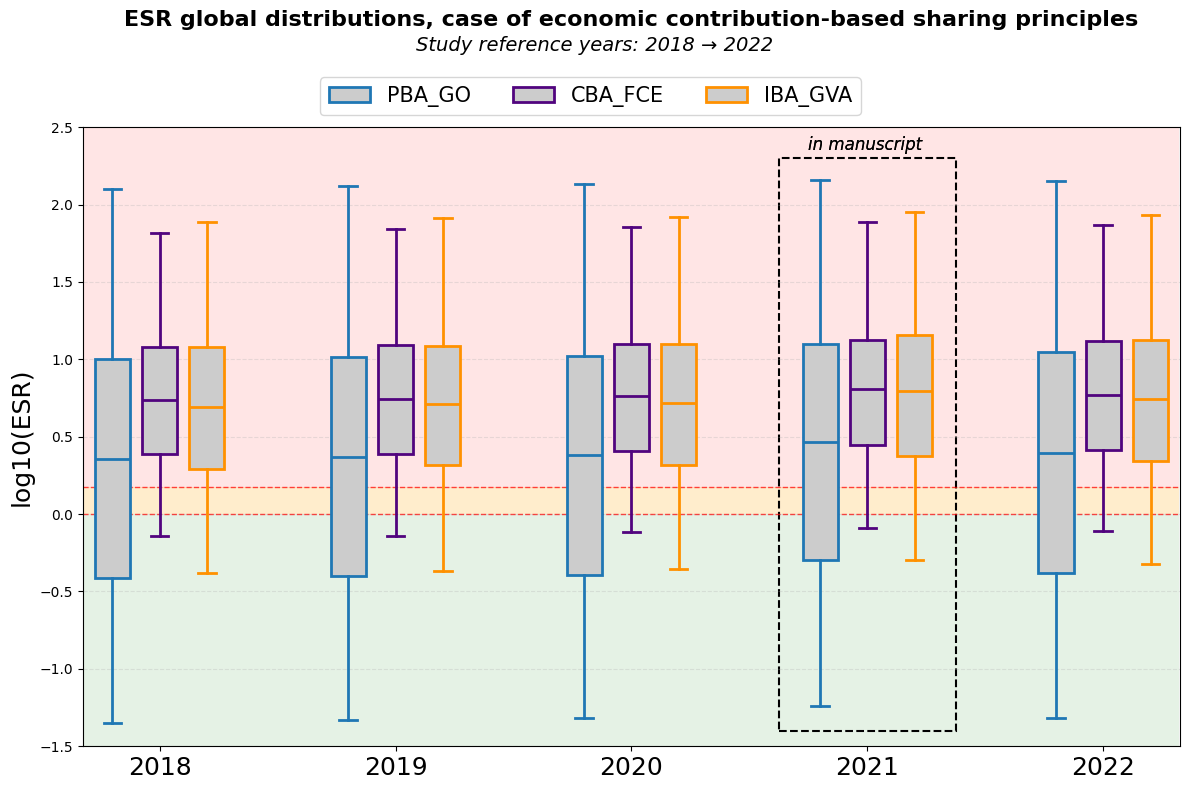

In [ ]:
# Figure S1

plot_global_sensi_distr_EC()

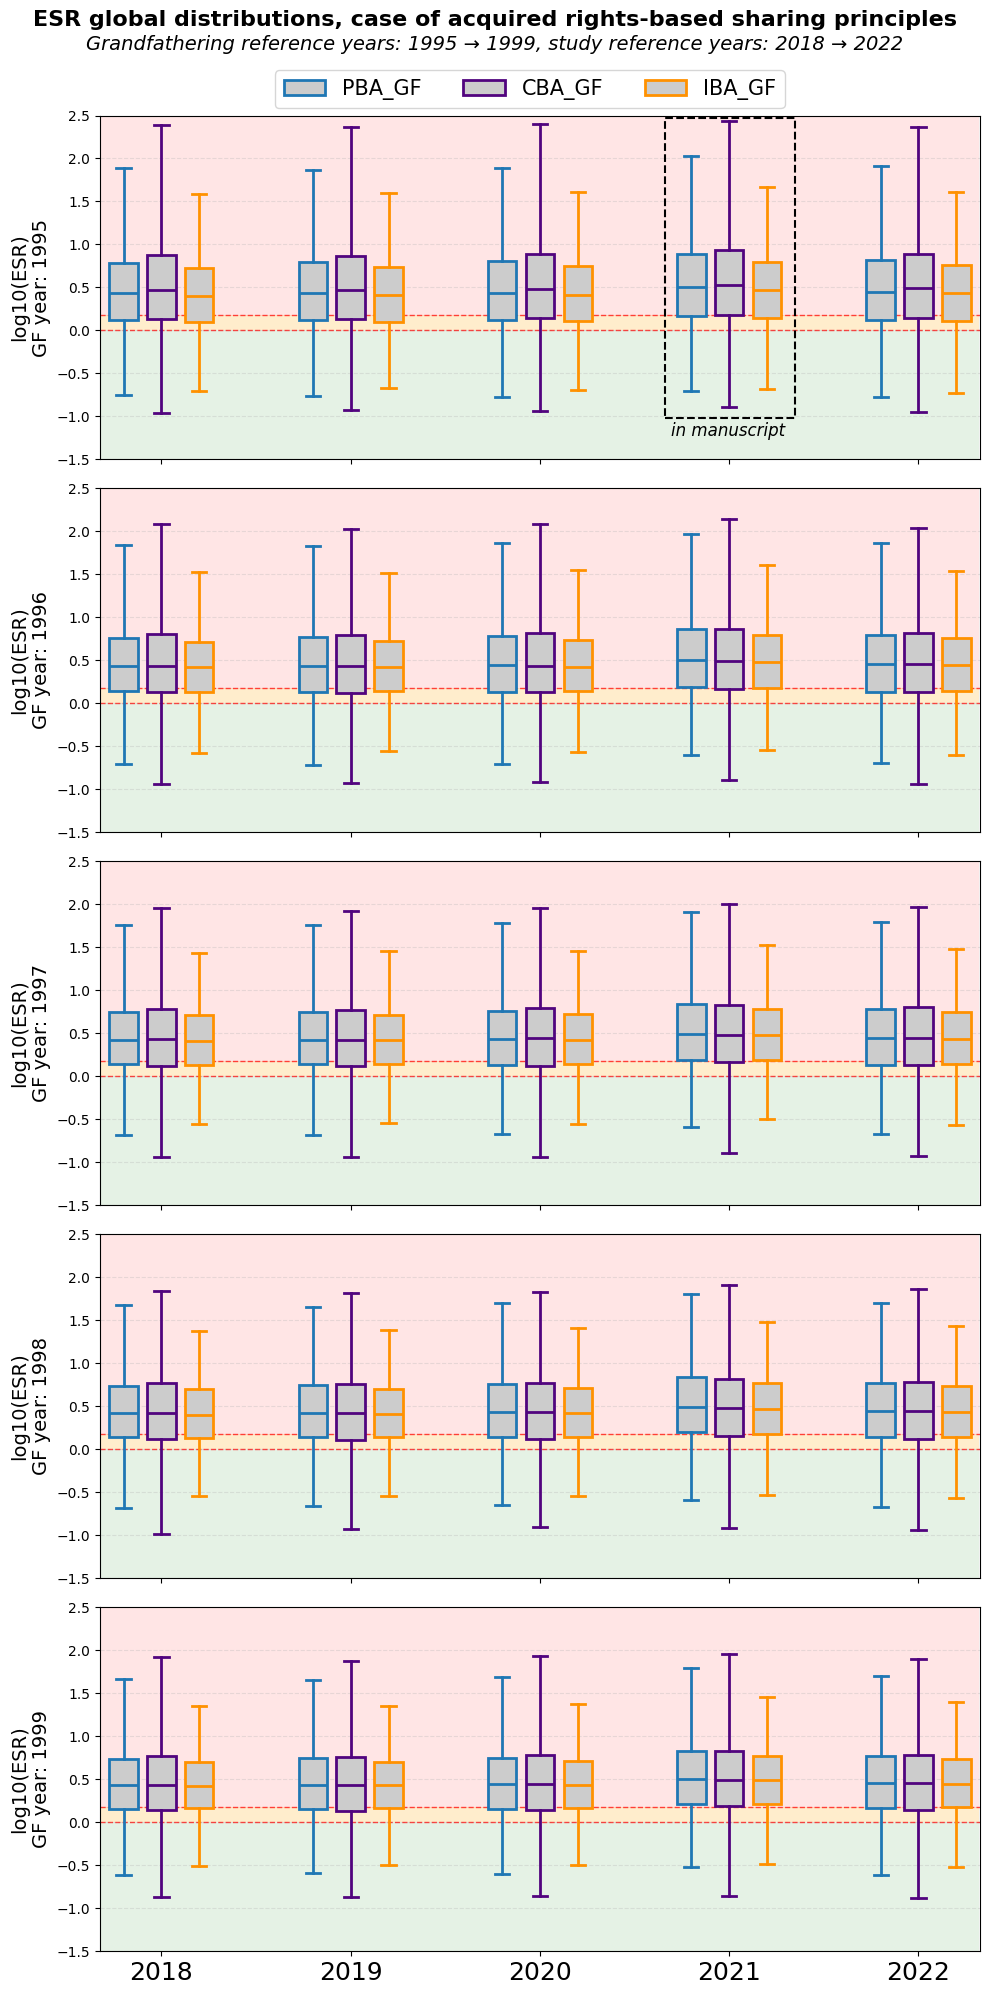

In [ ]:
# Figure S2

plot_global_sensi_distr_GF()

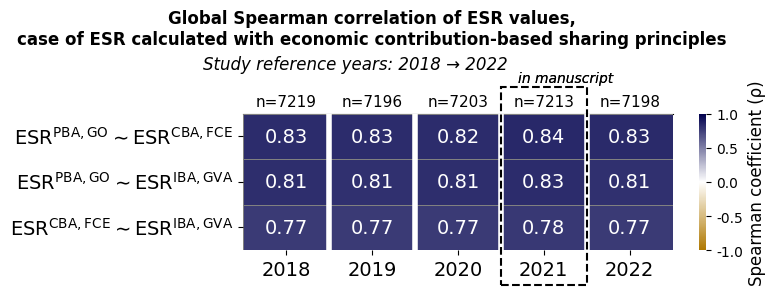

In [ ]:
# Figure S3

plot_global_sensi_HM_spear_EC()

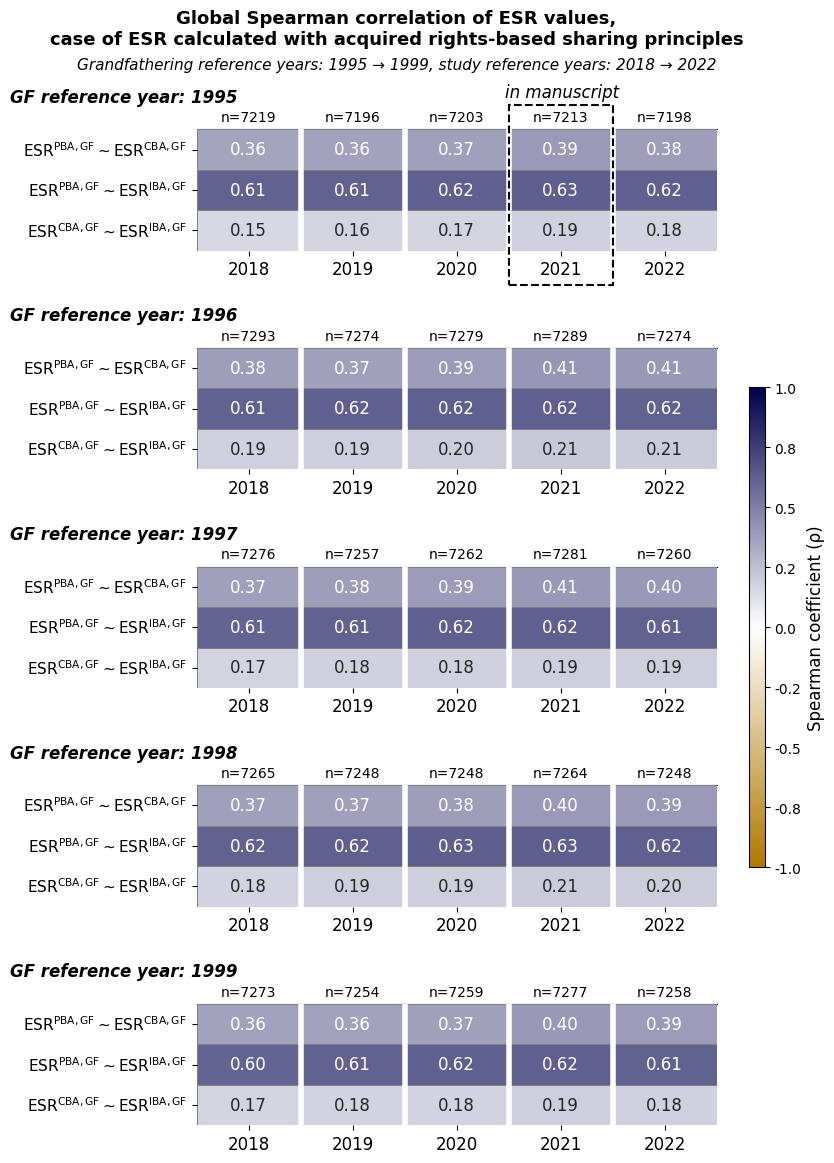

In [ ]:
# Figure S4

plot_global_sensi_HM_spear_GF()

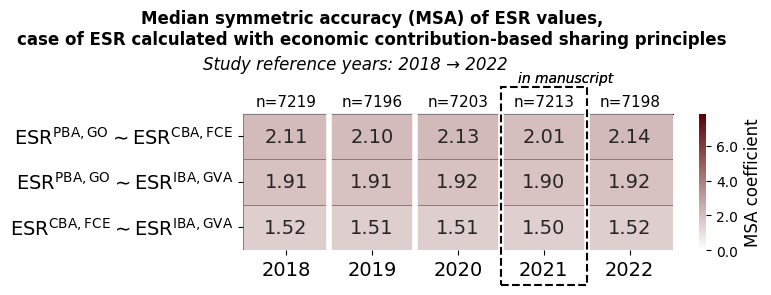

In [ ]:
# Figure S5

plot_global_sensi_HM_malr_EC()

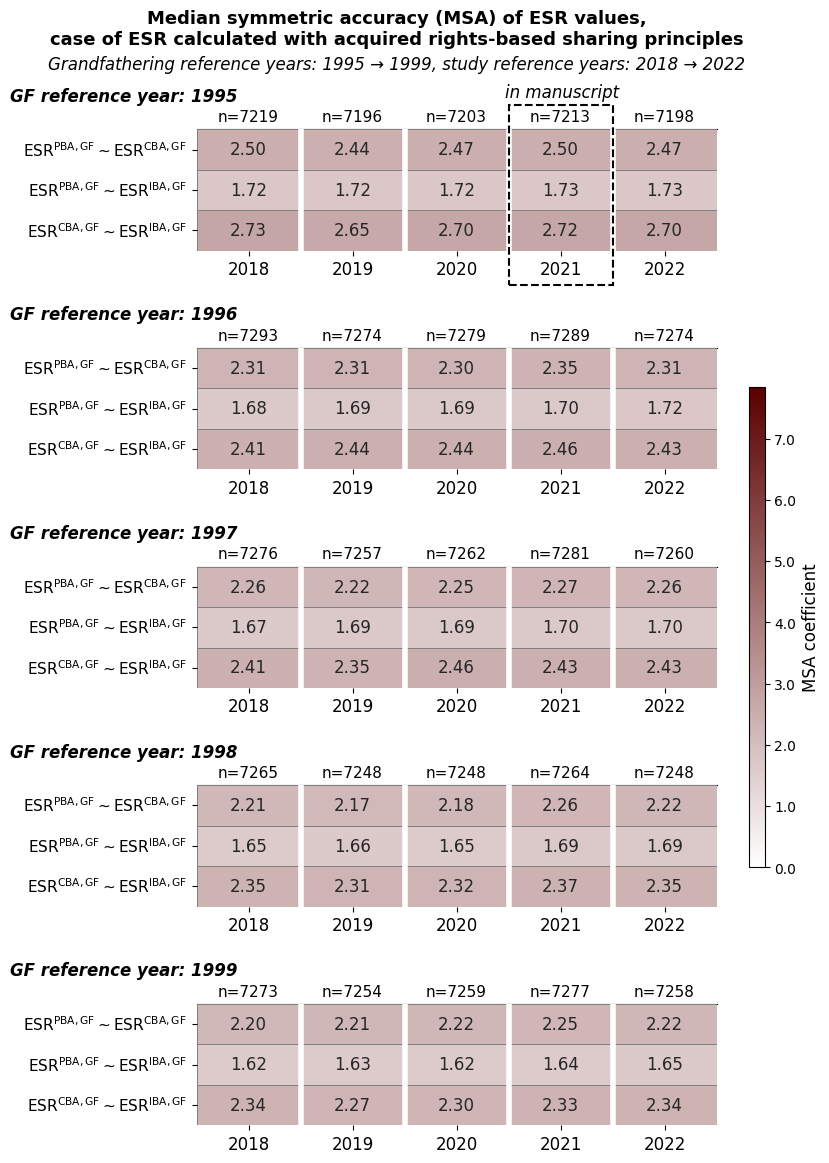

In [ ]:
# Figure S6

plot_global_sensi_HM_malr_GF()

In [ ]:
# Figures S7 to S11

plot_sect_cate_sensi_distr_EC()

5 graphes sauvegardés dans le dossier '1. Sensitivity by sector categories of ESR distribution. Case of EC-based SP'


In [ ]:
# Figures S12 to S36

plot_sect_cate_sensi_distr_GF()

25 graphes sauvegardés dans le dossier '2. Sensitivity by sector categories of ESR distribution. Case of AR-based SP'


In [ ]:
# Figures S37 to S41

plot_sect_cate_sensi_HM_spear_EC()

5 graphes sauvegardés dans le dossier '3. Sensitivity by sectors categories of Spearman correlation. Case of EC-based SP'


In [ ]:
# Figures S42 to S66

plot_sect_cate_sensi_HM_spear_GF()

25 graphes sauvegardés dans le dossier '4. Sensitivity by sectors categories of Spearman correlation. Case of AR-based SP'


In [ ]:
# Figures S67 to S71

plot_sect_cate_sensi_HM_malr_EC()

5 graphes sauvegardés dans le dossier '5. Sensitivity by sectors categories of MSA of ESR. Case of EC-based SP'


In [ ]:
# Figures S72 to S96

plot_sect_cate_sensi_HM_malr_GF()

25 graphes sauvegardés dans le dossier '6. Sensitivity by sectors categories of MSA of ESR. Case of AR-based SP'


## Analysis for explaining the treatment of ESR missing values (2021, GF 1995)

### Fig 5

In [ ]:
# nb ESR NaN,= 0 et < 0
ESR_isna = ESR.isna()
print(ESR_isna.sum())

ESR_inf = np.isinf(ESR)
print(ESR_inf.sum())

ESR_0 = (ESR == 0)
print(ESR_0.sum())

ESR_negative = (ESR < 0)
print(ESR_negative.sum())

ESR_PBA_GO     1650
ESR_CBA_FCE    2061
ESR_IBA_GVA    1659
ESR_PBA_GF     1318
ESR_CBA_GF     1764
ESR_IBA_GF     1315
dtype: int64
ESR_PBA_GO       0
ESR_CBA_FCE      0
ESR_IBA_GVA      0
ESR_PBA_GF     266
ESR_CBA_GF     438
ESR_IBA_GF     279
dtype: int64
ESR_PBA_GO      16
ESR_CBA_FCE      0
ESR_IBA_GVA      3
ESR_PBA_GF     348
ESR_CBA_GF     297
ESR_IBA_GF     347
dtype: int64
ESR_PBA_GO      0
ESR_CBA_FCE     0
ESR_IBA_GVA     0
ESR_PBA_GF      0
ESR_CBA_GF      0
ESR_IBA_GF     62
dtype: int64


In [ ]:
# explication ESR economic contribution NaN
x_0 = (data_2021['x_4'] == 0).sum()
print(x_0)
Y_0 = (data_2021['Y_total_4'] == 0).sum()
print(Y_0)
v_0 = (data_2021['v_4'] == 0).sum()
print(v_0)

1650
2061
1659


In [ ]:
# Explication ESR grandfathering NaN et inf
AI_1995_0 = (AI_1995 == 0).sum()
print(AI_1995_0)

PBA    1584
CBA    2202
IBA    1594
dtype: int64


In [ ]:
# explication ESR_PBA_GO = 0
print(data_2021['J'].loc[('HU', 'Other Liquid Biofuels')])
print(data_2021['J'].loc[('RU', 'Electricity by solar thermal')])
print(data_2021['J'].loc[('ZA', 'Electricity by nuclear')])
print(data_2021['J'].loc[('GB', 'Nickel ores and concentrates')])
print(data_2021['J'].loc[('ZA', 'Gasoline Type Jet Fuel')])
print(data_2021['J'].loc[('BR', 'Other Hydrocarbons')])
print(data_2021['J'].loc[('PL', 'Other Hydrocarbons')])
print(data_2021['J'].loc[('RU', 'Additives/Blending Components')])
print(data_2021['J'].loc[('BR', 'Patent Fuel')])
print(data_2021['J'].loc[('NO', 'Oxygen Steel Furnace Gas')])
print(data_2021['J'].loc[('MX', 'Transportation services via pipelines')])
print(data_2021['J'].loc[('NO', 'Gas Works Gas')])
print(data_2021['J'].loc[('DK', 'Natural Gas Liquids')])
print(data_2021['J'].loc[('ZA', 'Electricity by wind')])
print(data_2021['J'].loc[('ZA', 'Electricity by biomass and waste')])
print(data_2021['J'].loc[('DK', 'Precious metal ores and concentrates')])

0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0


In [ ]:
#explication ESR_IBA_GVA = 0
G_4 = data_2021['G']
G_4.index = index_4
G_4.columns = index_4

secteur_test = ('NO', 'Oxygen Steel Furnace Gas', 'Western Europe', 'Utility')
vtest = pd.DataFrame(np.zeros((len(data_2021['x']), 1)), index_4)

vtest.loc[secteur_test] = data_2021['v_4'].loc[secteur_test]

x_IBAtest = (vtest.T @ G_4).T
print(x_IBAtest.sum())
x_IBAtest_0 = x_IBAtest[x_IBAtest > 0].dropna()
print(x_IBAtest_0)
print("J = ", data_2021['J'].loc[('NO', 'Oxygen Steel Furnace Gas')])

secteur_test = ('IE', 'Petroleum Coke', 'Western Europe', 'Manufacturing_Fossil')
vtest = pd.DataFrame(np.zeros((len(data_2021['x']), 1)), index_4)

vtest.loc[secteur_test] = data_2021['v_4'].loc[secteur_test]

x_IBAtest = (vtest.T @ G_4).T
print(x_IBAtest.sum())
x_IBAtest_0 = x_IBAtest[x_IBAtest > 0].dropna()
print(x_IBAtest_0)
print("J = ", data_2021['J'].loc[('IE', 'Petroleum Coke')])

secteur_test = ('NO', 'Gas Works Gas', 'Western Europe', 'Utility')
vtest = pd.DataFrame(np.zeros((len(data_2021['x']), 1)), index_4)

vtest.loc[secteur_test] = data_2021['v_4'].loc[secteur_test]

x_IBAtest = (vtest.T @ G_4).T
print(x_IBAtest.sum())
x_IBAtest_0 = x_IBAtest[x_IBAtest > 0].dropna()
print(x_IBAtest_0)
print("J = ", data_2021['J'].loc[('NO', 'Gas Works Gas')])

0    37.355736
dtype: float64
                                                                                0
regions sectors                  aggregated_regions aggregated_sectors           
NO      Oxygen Steel Furnace Gas Western Europe     Utility             37.355736
J =  0.0
0    3.265450e-09
dtype: float64
                                                                           0
regions sectors        aggregated_regions aggregated_sectors                
IE      Petroleum Coke Western Europe     Manufacturing_Fossil  3.265450e-09
J =  0.0
0    37.885318
dtype: float64
                                                                     0
regions sectors       aggregated_regions aggregated_sectors           
NO      Gas Works Gas Western Europe     Utility             37.885318
J =  0.0


In [ ]:
# explication ESR_GF = 0

df_analysis_impact_PBA = df_analysis_impact[['PBA_1995', 'PBA_2021']]

count = (
    (df_analysis_impact_PBA['PBA_1995'] != 0) &
    (df_analysis_impact_PBA['PBA_2021'] == 0)
).sum()
print(f"Number of sectors where PBA_2021 is 0 and PBA_1995 is not 0: {count}")

df_analysis_impact_CBA = df_analysis_impact[['CBA_1995', 'CBA_2021']]

count = (
    (df_analysis_impact_CBA['CBA_1995'] != 0) &
    (df_analysis_impact_CBA['CBA_2021'] == 0)
).sum()
print(f"Number of sectors where CBA_2021 is 0 and CBA_1995 is not 0: {count}")

df_analysis_impact_PBA = df_analysis_impact[['IBA_1995', 'IBA_2021']]

count = (
    (df_analysis_impact_PBA['IBA_1995'] != 0) &
    (df_analysis_impact_PBA['IBA_2021'] == 0)
).sum()
print(f"Number of sectors where IBA_2021 is 0 and IBA_1995 is not 0: {count}")

Number of sectors where PBA_2021 is 0 and PBA_1995 is not 0: 348
Number of sectors where CBA_2021 is 0 and CBA_1995 is not 0: 297
Number of sectors where IBA_2021 is 0 and IBA_1995 is not 0: 347


In [ ]:
# explication ESR_IBA_GF < 0

v_1995 = data_1995['v_4'].rename('v_1995')
v_2021 = data_2021['v_4'].rename('v_2021')
IBA_1995 = AI_1995['IBA'].rename('IBA_1995')
IBA_2021 = AI_2021['IBA'].rename('IBA_2021')

df_analysis_GF_v_inf0 = pd.concat(
    [
        df_analysis_GF[['aCC_GF (IBA, 1995)_2021',
                        'ESR_IBA_GF (IBA, 1995)_2021']],
        v_1995.rename('v_1995'),
        v_2021.rename('v_2021'),
        IBA_1995.rename('IBA_1995'),
        IBA_2021.rename('IBA_2021')
    ],
    axis=1
)

count = (
    (df_analysis_GF_v_inf0['IBA_2021'] < 0) &
    (df_analysis_GF_v_inf0['IBA_1995'] > 0)
).sum()
print(f"Number of sectors where IBA_2021 < 0 and IBA_1995 > 0: {count}")

count = (
    (df_analysis_GF_v_inf0['IBA_2021'] > 0) &
    (df_analysis_GF_v_inf0['IBA_1995'] < 0)
).sum()
print(f"Number of sectors where IBA_2021 > 0 and IBA_1995 < 0: {count}")

count = (
    (df_analysis_GF_v_inf0['v_2021'] < 0) &
    (df_analysis_GF_v_inf0['v_1995'] > 0)
).sum()
print(f"Number of sectors where v_2021 < 0 and v_1995 > 0: {count}")

count = (
    (df_analysis_GF_v_inf0['v_2021'] > 0) &
    (df_analysis_GF_v_inf0['v_1995'] < 0)
).sum()
print(f"Number of sectors where v_2021 > 0 and v_1995 < 0: {count}")

Number of sectors where IBA_2021 < 0 and IBA_1995 > 0: 33
Number of sectors where IBA_2021 > 0 and IBA_1995 < 0: 28
Number of sectors where v_2021 < 0 and v_1995 > 0: 33
Number of sectors where v_2021 > 0 and v_1995 < 0: 28


In [ ]:
count = (
    ((df_analysis_GF_v_inf0['ESR_IBA_GF (IBA, 1995)_2021'] >= 0) &
    ((df_analysis_GF_v_inf0['v_2021'] < 0) | (df_analysis_GF_v_inf0['v_1995'] < 0)))
).sum()
print(f"Number of sectors where ESR_IBA_GF (IBA, 1995)_2021 >= 0 and (v_2021 < 0 or v_1995 < 0): {count}")

Number of sectors where ESR_IBA_GF (IBA, 1995)_2021 >= 0 and (v_2021 < 0 or v_1995 < 0): 9


### Fig 6

In [ ]:
def esr_fig6_by_category(ESR, sector_order, cat_level=3):
    """Secteurs absents de la Fig. 6 (ESR non fini ou < 0 dans au moins une des 6 approches),
    par catégorie de secteurs. Les colonnes de motifs sont NON exclusives."""
    cols = ['ESR_PBA_GO', 'ESR_CBA_FCE', 'ESR_IBA_GVA', 'ESR_PBA_GF', 'ESR_CBA_GF', 'ESR_IBA_GF']
    E = ESR[cols]
    cat = pd.Series(ESR.index.get_level_values(cat_level), index=ESR.index)
    cats = [c for c in sector_order if c in set(cat)]

    R = pd.DataFrame({
        'ESR = NaN (impact=0, aCC=0)':    E.isna().any(axis=1),
        'ESR = +inf (impact>0, aCC=0)':   (E == np.inf).any(axis=1),
        'ESR = -inf (impact<0, aCC=0)':   (E == -np.inf).any(axis=1),
        'ESR < 0 (finite)':               (np.isfinite(E) & (E < 0)).any(axis=1)})
    excluded = R.any(axis=1)

    t = R.groupby(cat).sum().reindex(cats)
    t['Total excluded (unique sectors)'] = excluded.groupby(cat).sum().reindex(cats)
    t['of which: several reasons'] = (R.sum(axis=1) > 1).groupby(cat).sum().reindex(cats)
    t.insert(0, 'Total sectors', cat.value_counts().reindex(cats))
    t['Kept in Fig. 6'] = t['Total sectors'] - t['Total excluded (unique sectors)']
    t['% excluded'] = (100 * t['Total excluded (unique sectors)'] / t['Total sectors']).round(1)
    t.loc['Global'] = t.sum()
    t.loc['Global', '% excluded'] = round(100 * t.loc['Global', 'Total excluded (unique sectors)']
                                          / t.loc['Global', 'Total sectors'], 1)
    assert t.loc['Global', 'Total sectors'] == len(ESR)

    return t

res = esr_fig6_by_category(ESR, sector_order, cat_level=3)

# res.to_excel('treatment_missing_ESR_fig6.xlsx')